# Programming 3: Quantum Fourier Transform

**Prof. Dr. Birger Horstmann, Konstantin Lamp, Lukas Haßfurth**

**to be discussed in the tutorial on November 25, 2026**

## Preliminary remarks:

You already know qiskit's `Statevector` class from the previous notebook. Let us consider, again, the Bell state

$$ | \Phi^+ \rangle = \frac{1}{\sqrt 2}\left(|00\rangle + |11\rangle\right). $$

Instead of creating the state with a quantum circuit, you can also build the statevector by providing it the $2^n$ coefficients directly:

In [1]:
from math import sqrt
import numpy as np
from qiskit.quantum_info import Statevector

coefficients = [1/sqrt(2), 0, 0, 1/sqrt(2)]
# build the statevector from a numpy array of coefficients
statevector = Statevector(np.array(coefficients))

# lets look at the result
print(statevector)
statevector.draw('latex')

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


<IPython.core.display.Latex object>

Another interesting way of building quantum states is to perform the tensor product of the computational basis states 
$\vert 0 \rangle = \begin{pmatrix}
           1 \\
           0
         \end{pmatrix}$ 
and $\vert 1 \rangle = \begin{pmatrix}
           0\\
           1
         \end{pmatrix}$ 
directly.

In [2]:
# lets define our basis state vectors
zero = np.array([1,0])
one = np.array([0,1])

# use np.kron(a,b) to calculate the tensor product |a>|b>
state = 1/sqrt(2) * (np.kron(zero,zero) + np.kron(one,one)) # == 1/sqrt(2) * (|00> + |11>)

# lets see how this looks:
print(state)

# create our statevector object
statevector_2 = Statevector(state)

# its still the same
print(statevector == statevector_2)

statevector_2.draw('latex')

[0.70710678 0.         0.         0.70710678]
True


<IPython.core.display.Latex object>

This becomes especially important when we have a vector in a factorized form, for example the $\vert\mathrm{++}\rangle$ state:

$$ \vert\mathrm{++}\rangle = \vert\mathrm{+}\rangle \otimes \vert\mathrm{+}\rangle = \frac{1}{2} \left ( \vert 0 \rangle + \vert 1 \rangle \right) \otimes \left ( \vert 0 \rangle + \vert 1 \rangle \right)$$

In [3]:
# using the tensor form we can build our individual plus states
plus = (zero + one)/sqrt(2)

# and perform the tensor product afterwards
plus_plus = np.kron(plus,plus)

# look at the result
statevector_pp = Statevector(plus_plus)
statevector_pp.draw('latex')

<IPython.core.display.Latex object>

This way, we can easily create even higher dimensional vectors:

In [4]:
# say we want to create the |++++> state
# so we have four qubits
n_qubits = 4

# we can build the total tensor product iteratively
tensor_product = 1
# in this for loop, we do not need to keep track of the index
# so instead of creating a variable, we use the dummy (blank) '_'
for _ in range(n_qubits):
    tensor_product = np.kron(tensor_product, plus)

# _ actually is a variable, it is just a convention to use it as dummy
# print(type(_), _)

# lets look at the final result
statevector_4d = Statevector(tensor_product)
print(tensor_product)
statevector_4d.draw('latex')

[0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25
 0.25 0.25]


<IPython.core.display.Latex object>

Another cool thing is that you can visualize statevector objects in the Bloch sphere picture. It shows the factorized form of the quantum state, so for the $\vert \mathrm{++} \rangle$ and $\vert \mathrm{++++} \rangle$ state, we see vectors pointing along the x-Axis.

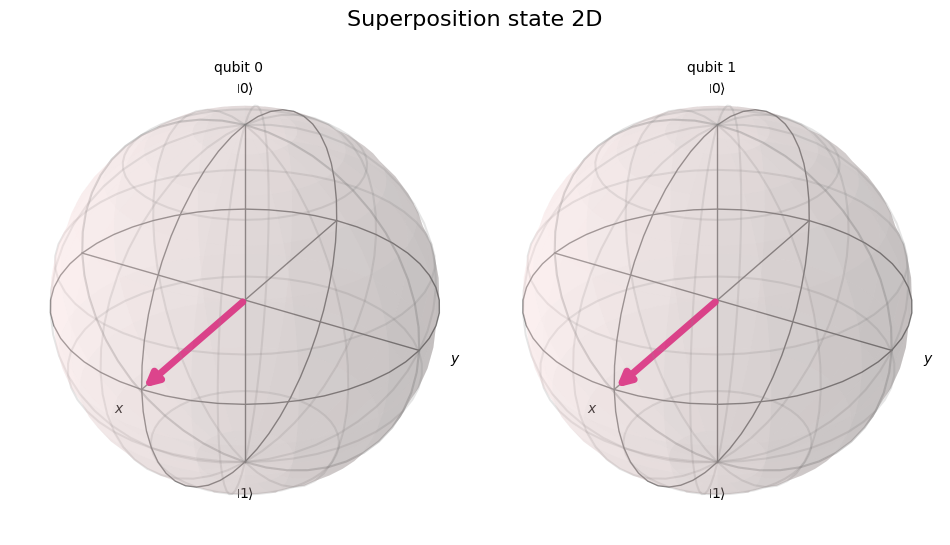

In [5]:
from qiskit.visualization import plot_bloch_multivector

plot_bloch_multivector(statevector_pp, title='Superposition state 2D')

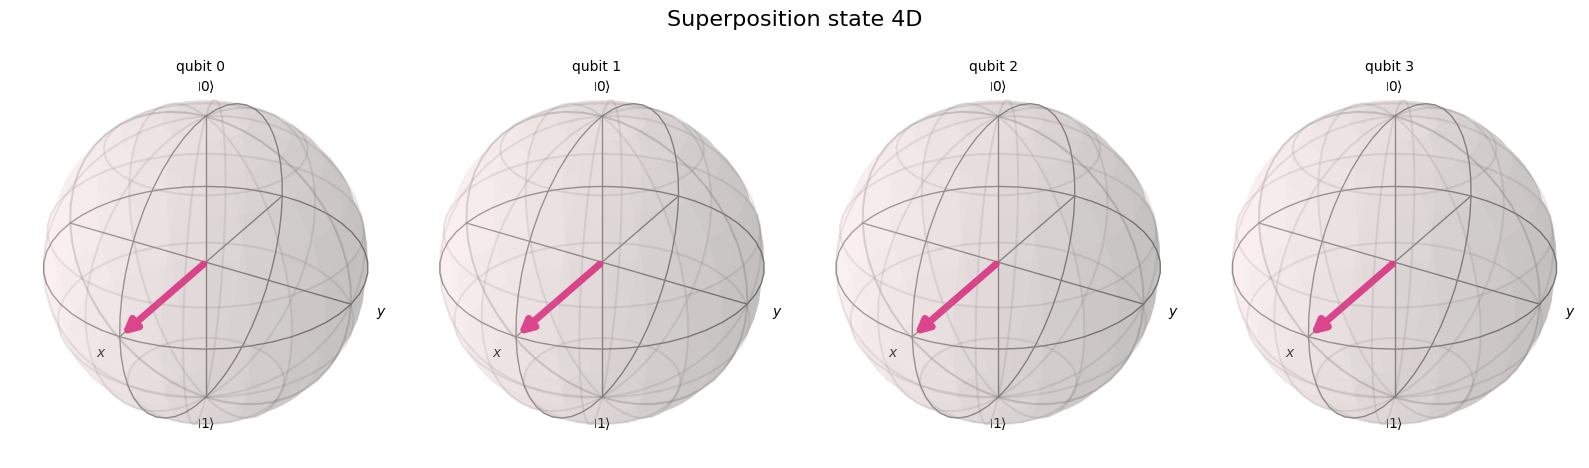

In [6]:
plot_bloch_multivector(statevector_4d, title='Superposition state 4D')

For our Bell state $\vert \Phi^+ \rangle$, things become a little more complicated. Since this is an entangled state, we can not factorize it directly.
The correct way to treat such systems is to calculate the reduced density matrices for each subsystem, which is defined as the partial trace of the total density matrix $\rho = \vert \Psi \rangle \langle \Psi \vert$.

For subsystem $A$ we have:

$$\rho _{A} = \mathrm{Tr}_B \; \rho = \sum _{i \in  \{ 0,1 \}}\left(\mathbb{I}_{A}\otimes \langle i|_{B}\right)\left(|\Psi \rangle \langle \Psi |\right)\left(\mathbb{I}_{A}\otimes |i\rangle _{B}\right)$$

As you might want to confirm this yields:

$$ \rho_A = \rho_B = \frac 1 2 \left ( \vert 0 \rangle \langle 0 \vert + \vert 1 \rangle \langle 1 \vert \right ) $$



for which $r_A=r_B=0$, \[compare *Sheet 1, 3g)*\]. Therefore we don't see any vectors:

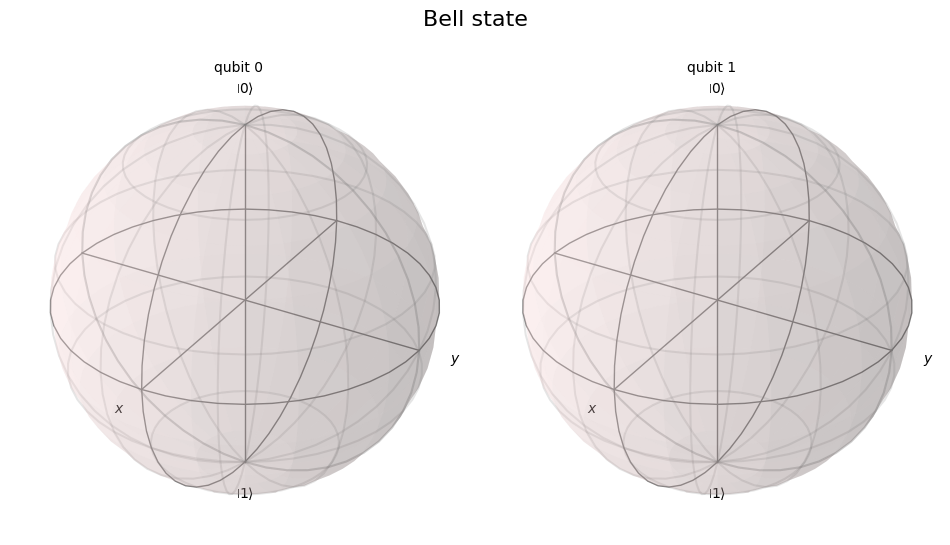

In [7]:
plot_bloch_multivector(statevector, title='Bell state')

# Exercise: Quantum Fourier Transform

The Quantum Fourier Transform (QFT) maps a state in the computational basis to a state in the Fourier basis.

$$ \vert \text{State in the computational basis} \rangle \xrightarrow{\quad \mathrm{QFT} \quad} \vert \text{State in the Fourier basis} \rangle $$

For the $n$ qubit basis state $\vert x \rangle = \vert x_1 , \dots, x_n\rangle,\ x \in [0,2^n),\ x_i \in \{0,1\}$  it is defined as:

$$ \begin{align*}
\text{QFT}\vert x \rangle =& \frac{1}{\sqrt{2^n}} \bigotimes_{k=1}^n \biggl ( \vert 0 \rangle + {\exp \small \left ({\frac{2\pi \mathrm i}{2^k}x} \right )} \vert 1 \rangle \biggr ) = 
\frac{1}{\sqrt{2^n}}\biggl ( \vert 0 \rangle + {\exp \small \left ({\frac{2\pi \mathrm i}{2}x} \right )} \vert 1 \rangle \biggr ) \otimes
\biggl ( \vert 0 \rangle + {\exp \small \left ({\frac{2\pi \mathrm i}{2^2}x} \right )} \vert 1 \rangle \biggr ) \otimes \dots \\
&\dots \otimes
\biggl ( \vert 0 \rangle + {\exp \small \left ({\frac{2\pi \mathrm i}{2^{n-1}}x} \right )} \vert 1 \rangle \biggr ) \otimes
\biggl ( \vert 0 \rangle + {\exp \small \left ({\frac{2\pi \mathrm i}{2^n}x} \right )} \vert 1 \rangle \biggr ) 
\end{align*}$$

**a)** Consider the example from exercise sheet 4, problem 2:

$$ \vert \phi \rangle = \frac 1 2
\begin{pmatrix}
1\\1\\1\\1
\end{pmatrix} = \vert \mathrm{++} \rangle = \frac 1 2 \biggl ( \vert 00 \rangle + \vert 01 \rangle + \vert 10 \rangle + \vert 11 \rangle \biggr ) = \frac 1 2 \biggl ( \vert 0 \rangle + \vert 1 \rangle + \vert 2 \rangle + \vert 3 \rangle \biggr )
$$

$$
\mathrm{QFT}\vert \phi \rangle = \vert 00 \rangle 
$$

**Built the two qubit Fourier transform of $\vert \phi \rangle$ using tensor products.**

*Hint:* Calculate the sum of computational basis states.

In [15]:
# Lets first import some additional modules
from math import pi
from cmath import exp
from qiskit import QuantumCircuit

# define constants for this problem
n_qubits = 2
n_states = 2**n_qubits

In [19]:
# define a function with inputs x and k to retrieve
# the fourier state |0> + exp(...)|1> of the kth qubit.
# this is a complex vector of the form (1+0j, exp(...)) = 1*|0> + exp(...)|1>
# j is the imaginary unit in python
def fourier_state(x, k):
    phase = exp(2j*pi * x/(2**k))
    return np.array([1 + 0j, phase], dtype=complex)


# initialize result array to 0
result = np.zeros(n_states, dtype=complex)

input_amplitudes = np.array([1, -1, 1, -1], dtype=complex)

# iterate over the basis states
for x in range(n_states):
    # build the tensor product qft_x
    qft_x = np.array([1.0 + 0j])

    # iteratively multiply qft_x with single qubit states
    for k in range(1, n_qubits + 1):
        qft_x = np.kron(qft_x, fourier_state(x, k))

    # the complete QFT is the normalized sum over all basis states
    result += input_amplitudes[x] * qft_x / n_states


# convert the result array to a statevector
# print and draw
qft_statevector = Statevector(result)
print(qft_statevector)
qft_statevector.draw('latex')


Statevector([ 0.00000000e+00+0.00000000e+00j,
              1.81686794e-17+2.77555756e-17j,
              1.00000000e+00-1.83697020e-16j,
             -8.22616137e-17+1.11022302e-16j],
            dims=(2, 2))


<IPython.core.display.Latex object>

**b) Repeat exercise a) using a circuit-based approach to build the two qubit QFT.**

*Hint:* Use a phase gate $\mathrm{P}(\lambda) = 
\begin{pmatrix}
1 & 0\\
0 & \mathrm{e}^{\mathrm{i}\lambda}
\end{pmatrix}
$ applicable by calling `p(lambda, qubit)`.

In [ ]:
# again we compute the sum, so initialize the result array to zero
result = np.zeros(n_states, dtype=complex)

# iterate over basis states
for x in range(n_states):
    # create a quantum circuit
    circuit = QuantumCircuit(n_qubits)

    # add gates transforming each qubit from |0> -> |0> + exp(...)|1>
    circuit.h(0)
    circuit.p(2 * pi * x / 2, 0)

    circuit.h(1)
    circuit.p(2 * pi * x / 4, 1)

    # Add Statevector(...).data to the result array
    result += Statevector(circuit).data / sqrt(n_states)

# convert the result array to a statevector
# print and draw
qft_statevector = Statevector(result)
print(qft_statevector)
qft_statevector.draw('latex')


**c)** Of course, in reality we might not actually know our quantum state beforehand, so neither can we construct the sum explicitly, nor can we input the value of $x$ as a variable. In order to perform a full-fledged QFT we therefore need to probe values of x on the fly. We can take advantage of the binary representation of $x$.

$$ x = 2^{n-1}x_1 + 2^{n-2}x_2 + \dots + 2^1 x_{n-1} + 2^0 x_n $$

We can sum up the value of $x$ by probing the values of the individual qubits $x_i$ and accounting for the prefactor $2^{n-i}$.

The rotation of the k-th qubit therefore becomes:

$$ \biggl ( \vert 0 \rangle + {\exp \small \left (\frac{2\pi \mathrm i}{2^k}x \right ) } \vert 1 \rangle \biggr ) = 
\biggl ( \vert 0 \rangle + {\exp \small \left (\frac{2\pi \mathrm i}{2^k} \sum_{i=1}^n  2^{n-i} x_i \right )} \vert 1 \rangle \biggr ) $$

Notice, that for $n-i >= k$ we are actually just adding multiples of $2 \pi \mathrm i$ to the phase of the exponential, i.e. full rotations in phase space which have no effect on the result. We can therefore disregard those numbers and start counting from $n - k + 1$.

There is one caveat to this observation. We will only need the value of the last qubit to calculate the QFT of the first qubit, we need the last two values for the second one and so forth. However, we can also see that the value of the first qubit is only needed to calculate the last QFT qubit. The second value is no longer needed after the second to last QFT qubit is calculated and so on. This means we can simply swap the order of how we encode the QFT states, overwrite the corresponding qubit states and swap everything back in the end (or at least keep in mind that the order is reversed).

So how do we actually probe for values of other qubits? You are already well familiar with a gate which behaves like this - the CNOT gate. C stands for "controlled" and there are many other controlled gates. For the purpose of the QFT we obviously need a controlled phase gate

$$\mathrm{CP}(\lambda) = 
\begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 &\mathrm{e}^{\mathrm{i}\lambda}
\end{pmatrix}$$

This is implemented in qiskit as `cp(lambda, control, target)`.

One last thing which we need is how to probe the state of the qubit we are currently changing, i.e. $i=n-k+1$. Lets look at the formula:

$$ \frac{2\pi \mathrm i}{2^k} 2^{n-i} x_i \overset{i=n-k+1}{=} \frac{2\pi \mathrm i}{2^k}   2^{k-1} x_i = \mathrm i \pi \, x_i$$

So, if $x_i=0$ we have $\exp(0)=1$. If $x_i=1$ we have $\exp(\mathrm i \pi) = -1$.
We will want to map 
$$ \vert 0 \rangle \rightarrow \vert 0 \rangle + \vert 1 \rangle \\
\vert 1 \rangle \rightarrow \vert 0 \rangle - \vert 1 \rangle{} $$
This is exactly the action Hadamard gate $\mathrm{H} = 
\begin{pmatrix}
1 & 1\\
1 & -1\\
\end{pmatrix}
$.

So now that we have everything together:



**Write your own (reversed output) QFT circuit _for a variable number of qubits_. Test your code on the $\vert \text{++}\rangle$ and $\vert \text{++++}\rangle$ states.**

*Hint:* The state of the reversed order fourier qubit $k' \in [1,n]$ is:

$$ \biggl ( \vert 0 \rangle + {\exp \small \left (\frac{2\pi \mathrm i}{2^{n-k'+1}} \sum_{i=k'}^n  2^{n-i} x_i \right )} \vert 1 \rangle \biggr ) =  
\biggl ( \vert 0 \rangle + {\exp \small \left (  \sum_{i'=0}^{n-k'}  \frac{\mathrm i \pi}{2^{i'}} x_{i'+k'} \right )} \vert 1 \rangle \biggr )$$


In [ ]:
# create a function that takes the number of qubits as an argument
# and returns a circuit which applies a QFT with output qubits reversed
def qft(n_qubits):
    # create the circuit object
    circuit = QuantumCircuit(n_qubits, name='QFT')

    # iterate over qubits (k')
    # Attention! Qubit indices are 0-based
    # The text uses a 1-based description
    for k in range(n_qubits):
        circuit.barrier()

        # add hadamard (i' = 0)
        circuit.h(k)

        # add controlled phase gates (i' = 1,...,n-k')
        for i in range(k + 1, n_qubits):
            circuit.cp(pi / (2 ** (i - k)), i, k)

    # add a barrier at the end
    circuit.barrier()

    # qiskit writes a state as |q_n-1,...,q_1,q_0>
    # reversing the qubit labels gives the reversed-output convention
    return circuit.reverse_bits()


In [ ]:
# now let us test our circuit on the + states
# lets define a function taking the number of qubits as argument
def test(n_qubits):
    # create a new initialization circuit object
    initialization = QuantumCircuit(n_qubits)

    # add hadamard gates to build the + states
    for qubit in range(n_qubits):
        initialization.h(qubit)

    # append initialization and qft
    complete_circuit = initialization.compose(qft(n_qubits))

    # draw decomposed circuit
    figure = complete_circuit.decompose().draw('mpl')

    # create and show the statevector
    statevector = Statevector(complete_circuit)
    display(statevector)

    # we have to return the figure created by draw for it to show
    return figure


In [ ]:
test(2)

In [ ]:
test(4)

**d) Create a function to restore the correct QFT qubit order. Test your complete circuit by calculating the Fourier transform of 5 = `101`. Plot the bloch multivector.**

*Hint 1:* Use swap gates `circuit.swap(q_1, q_2)`.

*Hint 2:* Use  `circuit.num_qubits` to get the total number of qubits for any quantum circuit.

*Hint 3:* The result should look like this:

<?xml version="1.0" encoding="utf-8" standalone="no"?>
<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"
  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">
<svg xmlns:xlink="http://www.w3.org/1999/xlink" width="1036.8pt" height="345.6pt" viewBox="0 0 1036.8 345.6" xmlns="http://www.w3.org/2000/svg" version="1.1">
 <metadata>
  <rdf:RDF xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:cc="http://creativecommons.org/ns#" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">
   <cc:Work>
    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>
    <dc:date>2023-05-14T00:18:56.262028</dc:date>
    <dc:format>image/svg+xml</dc:format>
    <dc:creator>
     <cc:Agent>
      <dc:title>Matplotlib v3.7.1, https://matplotlib.org/</dc:title>
     </cc:Agent>
    </dc:creator>
   </cc:Work>
  </rdf:RDF>
 </metadata>
 <defs>
  <style type="text/css">*{stroke-linejoin: round; stroke-linecap: butt}</style>
 </defs>
 <g id="figure_1">
  <g id="patch_1">
   <path d="M 0 345.6 
L 1036.8 345.6 
L 1036.8 0 
L 0 0 
z
" style="fill: #ffffff"/>
  </g>
  <g id="patch_2">
   <path d="M 129.6 292.692706 
L 365.929412 292.692706 
L 365.929412 56.363294 
L 129.6 56.363294 
z
" style="fill: #ffffff"/>
  </g>
  <g id="axes_1">
   <g id="line2d_1">
    <path d="M 170.132408 148.00192 
L 337.243643 196.242779 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_2">
    <path d="M 199.878662 215.570664 
L 296.566983 131.836121 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_3">
    <path d="M 250.958347 251.76666 
L 250.958347 84.59589 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_4">
    <path d="M 337.243643 196.242779 
L 342.284187 190.24856 
L 345.654445 184.021231 
L 347.334485 177.678439 
L 347.337092 171.334359 
L 345.704532 165.097573 
L 342.504947 159.069441 
L 337.828612 153.342938 
L 331.784286 148.00192 
L 324.495776 143.120732 
L 316.098858 138.764104 
L 306.738578 134.987253 
L 296.566983 131.836121 
L 285.741245 129.347686 
L 274.422161 127.550286 
L 262.772958 126.463917 
L 250.958347 126.100478 
L 239.143735 126.463917 
L 227.494532 127.550286 
L 216.175448 129.347686 
L 205.34971 131.836121 
L 195.178115 134.987253 
L 185.817835 138.764104 
L 177.420917 143.120732 
L 170.132408 148.00192 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_5">
    <path d="M 296.566983 131.836121 
L 296.409427 121.608413 
L 295.50584 112.080535 
L 293.856214 103.407115 
L 291.47045 95.737746 
L 288.369232 89.214669 
L 284.584899 83.970013 
L 280.162212 80.12257 
L 275.158954 77.774194 
L 269.646255 77.005908 
L 263.708531 77.873885 
L 257.442954 80.405528 
L 250.958347 84.59589 
L 244.373461 90.404755 
L 237.814602 97.754675 
L 231.412635 106.530257 
L 225.299464 116.578957 
L 219.604119 127.713506 
L 214.448654 139.716038 
L 209.944098 152.343781 
L 206.1867 165.336096 
L 203.254716 178.422473 
L 201.205952 191.33103 
L 200.076203 203.796993 
L 199.878662 215.570664 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_6">
    <path d="M 170.132408 148.00192 
L 164.088081 153.342938 
L 159.411746 159.069441 
L 156.212161 165.097573 
L 154.579601 171.334359 
L 154.582208 177.678439 
L 156.262248 184.021231 
L 159.632506 190.24856 
L 164.67305 196.242779 
L 171.328656 201.885365 
L 179.50717 207.059947 
L 189.079104 211.655659 
L 199.878662 215.570664 
L 211.706374 218.715681 
L 224.333344 221.017291 
L 237.507033 222.420795 
L 250.958347 222.892433 
L 264.40966 222.420795 
L 277.58335 221.017291 
L 290.210319 218.715681 
L 302.038031 215.570664 
L 312.837589 211.655659 
L 322.409523 207.059947 
L 330.588037 201.885365 
L 337.243643 196.242779 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_7">
    <path d="M 199.878662 215.570664 
L 200.604299 226.424417 
L 202.223122 236.158399 
L 204.686177 244.60469 
L 207.928106 251.629881 
L 211.870052 257.136087 
L 216.42271 261.060574 
L 221.489351 263.374223 
L 226.968659 264.079102 
L 232.757281 263.205438 
L 238.752025 260.80825 
L 244.85166 256.963889 
L 250.958347 251.76666 
L 256.978695 245.325685 
L 262.824518 237.762094 
L 268.413322 229.206595 
L 273.66859 219.797441 
L 278.519929 209.678781 
L 282.903131 198.999354 
L 286.760189 187.911469 
L 290.039338 176.570219 
L 292.695132 165.132838 
L 294.688615 153.758124 
L 295.987583 142.60586 
L 296.566983 131.836121 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="Poly3DCollection_1">
    <path d="M 271.081632 172.659 
L 269.401307 184.272109 
L 267.422942 195.702616 
L 259.252552 194.865032 
L 250.958347 194.584648 
L 250.958347 183.038812 
L 250.958347 171.334359 
L 261.093179 171.666495 
z
" clip-path="url(#pd8221dd24e)" style="fill: #776767; fill-opacity: 0.2"/>
    <path d="M 250.958347 171.334359 
L 250.958347 183.038812 
L 250.958347 194.584648 
L 242.664141 194.865032 
L 234.493751 195.702616 
L 232.515386 184.272109 
L 230.835061 172.659 
L 240.823514 171.666495 
z
" clip-path="url(#pd8221dd24e)" style="fill: #887575; fill-opacity: 0.2"/>
    <path d="M 250.958347 148.084071 
L 250.958347 159.629906 
L 250.958347 171.334359 
L 240.823514 171.666495 
L 230.835061 172.659 
L 229.475247 161.021616 
L 228.455187 149.518673 
L 239.626722 148.443721 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 273.461506 149.518673 
L 272.441447 161.021616 
L 271.081632 172.659 
L 261.093179 171.666495 
L 250.958347 171.334359 
L 250.958347 159.629906 
L 250.958347 148.084071 
L 262.289971 148.443721 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7a6a6a; fill-opacity: 0.2"/>
    <path d="M 290.039338 176.570219 
L 286.760189 187.911469 
L 282.903131 198.999354 
L 275.346713 197.086686 
L 267.422942 195.702616 
L 269.401307 184.272109 
L 271.081632 172.659 
L 280.778227 174.300131 
z
" clip-path="url(#pd8221dd24e)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 230.835061 172.659 
L 232.515386 184.272109 
L 234.493751 195.702616 
L 226.56998 197.086686 
L 219.013563 198.999354 
L 215.156504 187.911469 
L 211.877356 176.570219 
L 221.138467 174.300131 
z
" clip-path="url(#pd8221dd24e)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 228.455187 149.518673 
L 229.475247 161.021616 
L 230.835061 172.659 
L 221.138467 174.300131 
L 211.877356 176.570219 
L 209.221561 165.132838 
L 207.228078 153.758124 
L 217.603067 151.296882 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 294.688615 153.758124 
L 292.695132 165.132838 
L 290.039338 176.570219 
L 280.778227 174.300131 
L 271.081632 172.659 
L 272.441447 161.021616 
L 273.461506 149.518673 
L 284.313627 151.296882 
z
" clip-path="url(#pd8221dd24e)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 250.958347 194.584648 
L 250.958347 205.813606 
L 250.958347 216.56824 
L 245.052591 216.773652 
L 239.238711 217.387014 
L 236.744485 206.792992 
L 234.493751 195.702616 
L 242.664141 194.865032 
z
" clip-path="url(#pd8221dd24e)" style="fill: #837272; fill-opacity: 0.2"/>
    <path d="M 267.422942 195.702616 
L 265.172208 206.792992 
L 262.677982 217.387014 
L 256.864102 216.773652 
L 250.958347 216.56824 
L 250.958347 205.813606 
L 250.958347 194.584648 
L 259.252552 194.865032 
z
" clip-path="url(#pd8221dd24e)" style="fill: #766767; fill-opacity: 0.2"/>
    <path d="M 250.958347 126.100478 
L 250.958347 136.855112 
L 250.958347 148.084071 
L 239.626722 148.443721 
L 228.455187 149.518673 
L 227.790803 138.308851 
L 227.494532 127.550286 
L 239.143735 126.463917 
z
" clip-path="url(#pd8221dd24e)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 274.422161 127.550286 
L 274.12589 138.308851 
L 273.461506 149.518673 
L 262.289971 148.443721 
L 250.958347 148.084071 
L 250.958347 136.855112 
L 250.958347 126.100478 
L 262.772958 126.463917 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 282.903131 198.999354 
L 278.519929 209.678781 
L 273.66859 219.797441 
L 268.309105 218.399715 
L 262.677982 217.387014 
L 265.172208 206.792992 
L 267.422942 195.702616 
L 275.346713 197.086686 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6b5d5d; fill-opacity: 0.2"/>
    <path d="M 234.493751 195.702616 
L 236.744485 206.792992 
L 239.238711 217.387014 
L 233.607588 218.399715 
L 228.248104 219.797441 
L 223.396764 209.678781 
L 219.013563 198.999354 
L 226.56998 197.086686 
z
" clip-path="url(#pd8221dd24e)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 296.566983 131.836121 
L 295.987583 142.60586 
L 294.688615 153.758124 
L 284.313627 151.296882 
L 273.461506 149.518673 
L 274.12589 138.308851 
L 274.422161 127.550286 
L 285.741245 129.347686 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 227.494532 127.550286 
L 227.790803 138.308851 
L 228.455187 149.518673 
L 217.603067 151.296882 
L 207.228078 153.758124 
L 205.92911 142.60586 
L 205.34971 131.836121 
L 216.175448 129.347686 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 211.877356 176.570219 
L 215.156504 187.911469 
L 219.013563 198.999354 
L 211.942033 201.415531 
L 205.468485 204.302903 
L 199.933275 193.774155 
L 195.220117 182.878125 
L 203.192411 179.441534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 306.696576 182.878125 
L 301.983419 193.774155 
L 296.448208 204.302903 
L 289.97466 201.415531 
L 282.903131 198.999354 
L 286.760189 187.911469 
L 290.039338 176.570219 
L 298.724282 179.441534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5d5050; fill-opacity: 0.2"/>
    <path d="M 313.39056 160.606595 
L 310.518706 171.769503 
L 306.696576 182.878125 
L 298.724282 179.441534 
L 290.039338 176.570219 
L 292.695132 165.132838 
L 294.688615 153.758124 
L 304.431356 156.873784 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 207.228078 153.758124 
L 209.221561 165.132838 
L 211.877356 176.570219 
L 203.192411 179.441534 
L 195.220117 182.878125 
L 191.397987 171.769503 
L 188.526133 160.606595 
L 197.485337 156.873784 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b59d9d; fill-opacity: 0.2"/>
    <path d="M 296.448208 204.302903 
L 290.169173 214.314075 
L 283.233415 223.662585 
L 278.670598 221.560232 
L 273.66859 219.797441 
L 278.519929 209.678781 
L 282.903131 198.999354 
L 289.97466 201.415531 
z
" clip-path="url(#pd8221dd24e)" style="fill: #635656; fill-opacity: 0.2"/>
    <path d="M 219.013563 198.999354 
L 223.396764 209.678781 
L 228.248104 219.797441 
L 223.246095 221.560232 
L 218.683278 223.662585 
L 211.74752 214.314075 
L 205.468485 204.302903 
L 211.942033 201.415531 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 262.677982 217.387014 
L 259.972395 227.330444 
L 257.090872 236.471964 
L 254.049801 236.14307 
L 250.958347 236.032871 
L 250.958347 226.692547 
L 250.958347 216.56824 
L 256.864102 216.773652 
z
" clip-path="url(#pd8221dd24e)" style="fill: #786868; fill-opacity: 0.2"/>
    <path d="M 250.958347 216.56824 
L 250.958347 226.692547 
L 250.958347 236.032871 
L 247.866892 236.14307 
L 244.825821 236.471964 
L 241.944298 227.330444 
L 239.238711 217.387014 
L 245.052591 216.773652 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 250.958347 106.635848 
L 250.958347 115.976172 
L 250.958347 126.100478 
L 239.143735 126.463917 
L 227.494532 127.550286 
L 227.575092 117.399872 
L 228.037173 108.012306 
L 239.41655 106.980912 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 273.87952 108.012306 
L 274.341601 117.399872 
L 274.422161 127.550286 
L 262.772958 126.463917 
L 250.958347 126.100478 
L 250.958347 115.976172 
L 250.958347 106.635848 
L 262.500143 106.980912 
z
" clip-path="url(#pd8221dd24e)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 273.66859 219.797441 
L 268.413322 229.206595 
L 262.824518 237.762094 
L 260.031876 237.014451 
L 257.090872 236.471964 
L 259.972395 227.330444 
L 262.677982 217.387014 
L 268.309105 218.399715 
z
" clip-path="url(#pd8221dd24e)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 239.238711 217.387014 
L 241.944298 227.330444 
L 244.825821 236.471964 
L 241.884817 237.014451 
L 239.092175 237.762094 
L 233.503371 229.206595 
L 228.248104 219.797441 
L 233.607588 218.399715 
z
" clip-path="url(#pd8221dd24e)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 205.34971 131.836121 
L 205.92911 142.60586 
L 207.228078 153.758124 
L 197.485337 156.873784 
L 188.526133 160.606595 
L 186.653471 149.550486 
L 185.817835 138.764104 
L 195.178115 134.987253 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 316.098858 138.764104 
L 315.263222 149.550486 
L 313.39056 160.606595 
L 304.431356 156.873784 
L 294.688615 153.758124 
L 295.987583 142.60586 
L 296.566983 131.836121 
L 306.738578 134.987253 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5e5252; fill-opacity: 0.2"/>
    <path d="M 283.233415 223.662585 
L 275.736602 232.209469 
L 267.782665 239.822963 
L 265.422594 238.703202 
L 262.824518 237.762094 
L 268.413322 229.206595 
L 273.66859 219.797441 
L 278.670598 221.560232 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 228.248104 219.797441 
L 233.503371 229.206595 
L 239.092175 237.762094 
L 236.494099 238.703202 
L 234.134029 239.822963 
L 226.180092 232.209469 
L 218.683278 223.662585 
L 223.246095 221.560232 
z
" clip-path="url(#pd8221dd24e)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 295.50584 112.080535 
L 296.409427 121.608413 
L 296.566983 131.836121 
L 285.741245 129.347686 
L 274.422161 127.550286 
L 274.341601 117.399872 
L 273.87952 108.012306 
L 284.934795 109.718588 
z
" clip-path="url(#pd8221dd24e)" style="fill: #756565; fill-opacity: 0.2"/>
    <path d="M 228.037173 108.012306 
L 227.575092 117.399872 
L 227.494532 127.550286 
L 216.175448 129.347686 
L 205.34971 131.836121 
L 205.507266 121.608413 
L 206.410853 112.080535 
L 216.981898 109.718588 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 319.987433 191.26134 
L 314.090673 201.552764 
L 307.179641 211.325964 
L 302.216507 207.62194 
L 296.448208 204.302903 
L 301.983419 193.774155 
L 306.696576 182.878125 
L 313.825419 186.835664 
z
" clip-path="url(#pd8221dd24e)" style="fill: #554949; fill-opacity: 0.2"/>
    <path d="M 195.220117 182.878125 
L 199.933275 193.774155 
L 205.468485 204.302903 
L 199.700186 207.62194 
L 194.737052 211.325964 
L 187.826021 201.552764 
L 181.92926 191.26134 
L 188.091274 186.835664 
z
" clip-path="url(#pd8221dd24e)" style="fill: #baa1a1; fill-opacity: 0.2"/>
    <path d="M 205.468485 204.302903 
L 211.74752 214.314075 
L 218.683278 223.662585 
L 214.636121 226.073593 
L 211.174665 228.757157 
L 202.558258 220.438681 
L 194.737052 211.325964 
L 199.700186 207.62194 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 307.179641 211.325964 
L 299.358435 220.438681 
L 290.742028 228.757157 
L 287.280573 226.073593 
L 283.233415 223.662585 
L 290.169173 214.314075 
L 296.448208 204.302903 
L 302.216507 207.62194 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5d5151; fill-opacity: 0.2"/>
    <path d="M 328.381666 169.729688 
L 324.777605 180.601513 
L 319.987433 191.26134 
L 313.825419 186.835664 
L 306.696576 182.878125 
L 310.518706 171.769503 
L 313.39056 160.606595 
L 321.420261 164.910357 
z
" clip-path="url(#pd8221dd24e)" style="fill: #514747; fill-opacity: 0.2"/>
    <path d="M 188.526133 160.606595 
L 191.397987 171.769503 
L 195.220117 182.878125 
L 188.091274 186.835664 
L 181.92926 191.26134 
L 177.139089 180.601513 
L 173.535028 169.729688 
L 180.496432 164.910357 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c7adad; fill-opacity: 0.2"/>
    <path d="M 218.683278 223.662585 
L 226.180092 232.209469 
L 234.134029 239.822963 
L 232.051957 241.103613 
L 230.283783 242.524649 
L 220.46126 236.157088 
L 211.174665 228.757157 
L 214.636121 226.073593 
z
" clip-path="url(#pd8221dd24e)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 290.742028 228.757157 
L 281.455433 236.157088 
L 271.63291 242.524649 
L 269.864736 241.103613 
L 267.782665 239.822963 
L 275.736602 232.209469 
L 283.233415 223.662585 
L 287.280573 226.073593 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 314.568592 118.6543 
L 315.871603 128.411071 
L 316.098858 138.764104 
L 306.738578 134.987253 
L 296.566983 131.836121 
L 296.409427 121.608413 
L 295.50584 112.080535 
L 305.435058 115.07093 
z
" clip-path="url(#pd8221dd24e)" style="fill: #665858; fill-opacity: 0.2"/>
    <path d="M 206.410853 112.080535 
L 205.507266 121.608413 
L 205.34971 131.836121 
L 195.178115 134.987253 
L 185.817835 138.764104 
L 186.04509 128.411071 
L 187.348101 118.6543 
L 196.481635 115.07093 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 257.090872 236.471964 
L 254.072169 244.664452 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 244.439164 
L 250.958347 236.032871 
L 254.049801 236.14307 
z
" clip-path="url(#pd8221dd24e)" style="fill: #736464; fill-opacity: 0.2"/>
    <path d="M 250.958347 236.032871 
L 250.958347 244.439164 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 247.844524 244.664452 
L 244.825821 236.471964 
L 247.866892 236.14307 
z
" clip-path="url(#pd8221dd24e)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 262.824518 237.762094 
L 256.978695 245.325685 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 254.072169 244.664452 
L 257.090872 236.471964 
L 260.031876 237.014451 
z
" clip-path="url(#pd8221dd24e)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 244.825821 236.471964 
L 247.844524 244.664452 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 244.937998 245.325685 
L 239.092175 237.762094 
L 241.884817 237.014451 
z
" clip-path="url(#pd8221dd24e)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 314.337791 219.667579 
L 305.439471 227.693192 
L 295.667088 234.773366 
L 293.555376 231.672264 
L 290.742028 228.757157 
L 299.358435 220.438681 
L 307.179641 211.325964 
L 311.246737 215.361304 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 271.814508 92.125222 
L 273.035636 99.538772 
L 273.87952 108.012306 
L 262.500143 106.980912 
L 250.958347 106.635848 
L 250.958347 98.229555 
L 250.958347 90.902058 
L 261.461768 91.208735 
z
" clip-path="url(#pd8221dd24e)" style="fill: #917d7d; fill-opacity: 0.2"/>
    <path d="M 250.958347 90.902058 
L 250.958347 98.229555 
L 250.958347 106.635848 
L 239.41655 106.980912 
L 228.037173 108.012306 
L 228.881057 99.538772 
L 230.102185 92.125222 
L 240.454925 91.208735 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 295.667088 234.773366 
L 285.170412 240.803671 
L 274.108187 245.693745 
L 273.056014 244.063082 
L 271.63291 242.524649 
L 281.455433 236.157088 
L 290.742028 228.757157 
L 293.555376 231.672264 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 267.782665 239.822963 
L 259.483464 246.379781 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 256.978695 245.325685 
L 262.824518 237.762094 
L 265.422594 238.703202 
z
" clip-path="url(#pd8221dd24e)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 239.092175 237.762094 
L 244.937998 245.325685 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 242.433229 246.379781 
L 234.134029 239.822963 
L 236.494099 238.703202 
z
" clip-path="url(#pd8221dd24e)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 331.784286 148.00192 
L 330.734024 158.807772 
L 328.381666 169.729688 
L 321.420261 164.910357 
L 313.39056 160.606595 
L 315.263222 149.550486 
L 316.098858 138.764104 
L 324.495776 143.120732 
z
" clip-path="url(#pd8221dd24e)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 185.817835 138.764104 
L 186.653471 149.550486 
L 188.526133 160.606595 
L 180.496432 164.910357 
L 173.535028 169.729688 
L 171.182669 158.807772 
L 170.132408 148.00192 
L 177.420917 143.120732 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 328.966938 201.263408 
L 322.222724 210.814252 
L 314.337791 219.667579 
L 311.246737 215.361304 
L 307.179641 211.325964 
L 314.090673 201.552764 
L 319.987433 191.26134 
L 325.068677 196.093829 
z
" clip-path="url(#pd8221dd24e)" style="fill: #514646; fill-opacity: 0.2"/>
    <path d="M 234.134029 239.822963 
L 242.433229 246.379781 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 240.499549 247.757621 
L 230.283783 242.524649 
L 232.051957 241.103613 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7e6d6d; fill-opacity: 0.2"/>
    <path d="M 271.63291 242.524649 
L 261.417144 247.757621 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 259.483464 246.379781 
L 267.782665 239.822963 
L 269.864736 241.103613 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7a6969; fill-opacity: 0.2"/>
    <path d="M 291.47045 95.737746 
L 293.856214 103.407115 
L 295.50584 112.080535 
L 284.934795 109.718588 
L 273.87952 108.012306 
L 273.035636 99.538772 
L 271.814508 92.125222 
L 281.866746 93.640852 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 230.102185 92.125222 
L 228.881057 99.538772 
L 228.037173 108.012306 
L 216.981898 109.718588 
L 206.410853 112.080535 
L 208.060479 103.407115 
L 210.446243 95.737746 
L 220.049948 93.640852 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b8a0a0; fill-opacity: 0.2"/>
    <path d="M 274.108187 245.693745 
L 262.6467 249.368051 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 261.417144 247.757621 
L 271.63291 242.524649 
L 273.056014 244.063082 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7e6e6e; fill-opacity: 0.2"/>
    <path d="M 275.026034 249.122348 
L 263.084767 251.103358 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 262.6467 249.368051 
L 274.108187 245.693745 
L 274.769421 247.389642 
z
" clip-path="url(#pd8221dd24e)" style="fill: #847272; fill-opacity: 0.2"/>
    <path d="M 297.623224 241.331676 
L 286.598776 245.850309 
L 275.026034 249.122348 
L 274.769421 247.389642 
L 274.108187 245.693745 
L 285.170412 240.803671 
L 295.667088 234.773366 
L 297.033742 238.010857 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6c5e5e; fill-opacity: 0.2"/>
    <path d="M 338.593837 180.646689 
L 334.45674 191.156805 
L 328.966938 201.263408 
L 325.068677 196.093829 
L 319.987433 191.26134 
L 324.777605 180.601513 
L 328.381666 169.729688 
L 334.145349 174.999845 
z
" clip-path="url(#pd8221dd24e)" style="fill: #4d4343; fill-opacity: 0.2"/>
    <path d="M 274.304537 252.580032 
L 262.696545 252.846066 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 263.084767 251.103358 
L 275.026034 249.122348 
L 274.871058 250.86245 
z
" clip-path="url(#pd8221dd24e)" style="fill: #897777; fill-opacity: 0.2"/>
    <path d="M 317.337797 228.82065 
L 307.92513 235.628568 
L 297.623224 241.331676 
L 297.033742 238.010857 
L 295.667088 234.773366 
L 305.439471 227.693192 
L 314.337791 219.667579 
L 316.385608 224.17813 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5c5050; fill-opacity: 0.2"/>
    <path d="M 329.861253 127.415082 
L 331.498627 137.481054 
L 331.784286 148.00192 
L 324.495776 143.120732 
L 316.098858 138.764104 
L 315.871603 128.411071 
L 314.568592 118.6543 
L 322.757828 122.786627 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5c4f4f; fill-opacity: 0.2"/>
    <path d="M 187.348101 118.6543 
L 186.04509 128.411071 
L 185.817835 138.764104 
L 177.420917 143.120732 
L 170.132408 148.00192 
L 170.418066 137.481054 
L 172.05544 127.415082 
L 179.158865 122.786627 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 271.973015 255.828582 
L 261.50348 254.476714 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 262.696545 252.846066 
L 274.304537 252.580032 
L 273.333701 254.245191 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8f7c7c; fill-opacity: 0.2"/>
    <path d="M 210.446243 95.737746 
L 208.060479 103.407115 
L 206.410853 112.080535 
L 196.481635 115.07093 
L 187.348101 118.6543 
L 189.72561 109.65426 
L 193.161057 101.566859 
L 201.436253 98.390668 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 308.755636 101.566859 
L 312.191083 109.65426 
L 314.568592 118.6543 
L 305.435058 115.07093 
L 295.50584 112.080535 
L 293.856214 103.407115 
L 291.47045 95.737746 
L 300.48044 98.390668 
z
" clip-path="url(#pd8221dd24e)" style="fill: #726262; fill-opacity: 0.2"/>
    <path d="M 296.405271 247.998269 
L 285.600996 250.960463 
L 274.304537 252.580032 
L 274.871058 250.86245 
L 275.026034 249.122348 
L 286.598776 245.850309 
L 297.623224 241.331676 
L 297.415835 244.680034 
z
" clip-path="url(#pd8221dd24e)" style="fill: #706161; fill-opacity: 0.2"/>
    <path d="M 332.879633 212.295003 
L 325.704262 221.004864 
L 317.337797 228.82065 
L 316.385608 224.17813 
L 314.337791 219.667579 
L 322.222724 210.814252 
L 328.966938 201.263408 
L 331.594255 206.692256 
z
" clip-path="url(#pd8221dd24e)" style="fill: #524747; fill-opacity: 0.2"/>
    <path d="M 342.504947 159.069441 
L 341.297189 169.894521 
L 338.593837 180.646689 
L 334.145349 174.999845 
L 328.381666 169.729688 
L 330.734024 158.807772 
L 331.784286 148.00192 
L 337.828612 153.342938 
z
" clip-path="url(#pd8221dd24e)" style="fill: #4f4444; fill-opacity: 0.2"/>
    <path d="M 268.285809 81.022056 
L 270.22601 85.910179 
L 271.814508 92.125222 
L 261.461768 91.208735 
L 250.958347 90.902058 
L 250.958347 84.790687 
L 250.958347 80.022667 
L 259.686727 80.273297 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 250.958347 80.022667 
L 250.958347 84.790687 
L 250.958347 90.902058 
L 240.454925 91.208735 
L 230.102185 92.125222 
L 231.690683 85.910179 
L 233.630884 81.022056 
L 242.229966 80.273297 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 292.020832 254.310389 
L 282.201305 255.780599 
L 271.973015 255.828582 
L 273.333701 254.245191 
L 274.304537 252.580032 
L 285.600996 250.960463 
L 296.405271 247.998269 
L 294.599407 251.227834 
z
" clip-path="url(#pd8221dd24e)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 315.831551 238.189444 
L 306.539594 243.724182 
L 296.405271 247.998269 
L 297.415835 244.680034 
L 297.623224 241.331676 
L 307.92513 235.628568 
L 317.337797 228.82065 
L 317.158757 233.51803 
z
" clip-path="url(#pd8221dd24e)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 284.584899 83.970013 
L 288.369232 89.214669 
L 291.47045 95.737746 
L 281.866746 93.640852 
L 271.814508 92.125222 
L 270.22601 85.910179 
L 268.285809 81.022056 
L 276.627288 82.259534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 233.630884 81.022056 
L 231.690683 85.910179 
L 230.102185 92.125222 
L 220.049948 93.640852 
L 210.446243 95.737746 
L 213.547461 89.214669 
L 217.331794 83.970013 
L 225.289405 82.259534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 343.152932 192.728187 
L 338.733579 202.821044 
L 332.879633 212.295003 
L 331.594255 206.692256 
L 328.966938 201.263408 
L 334.45674 191.156805 
L 338.593837 180.646689 
L 341.624533 186.586852 
z
" clip-path="url(#pd8221dd24e)" style="fill: #4e4343; fill-opacity: 0.2"/>
    <path d="M 193.161057 101.566859 
L 189.72561 109.65426 
L 187.348101 118.6543 
L 179.158865 122.786627 
L 172.05544 127.415082 
L 175.040829 117.972794 
L 179.34961 109.319374 
L 185.756138 105.225859 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 322.567083 109.319374 
L 326.875865 117.972794 
L 329.861253 127.415082 
L 322.757828 122.786627 
L 314.568592 118.6543 
L 312.191083 109.65426 
L 308.755636 101.566859 
L 316.160555 105.225859 
z
" clip-path="url(#pd8221dd24e)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 340.293908 137.903985 
L 342.176403 148.346406 
L 342.504947 159.069441 
L 337.828612 153.342938 
L 331.784286 148.00192 
L 331.498627 137.481054 
L 329.861253 127.415082 
L 335.746685 132.477834 
z
" clip-path="url(#pd8221dd24e)" style="fill: #574b4b; fill-opacity: 0.2"/>
    <path d="M 298.860552 88.715277 
L 304.295276 94.540926 
L 308.755636 101.566859 
L 300.48044 98.390668 
L 291.47045 95.737746 
L 288.369232 89.214669 
L 284.584899 83.970013 
L 292.035545 86.131418 
z
" clip-path="url(#pd8221dd24e)" style="fill: #817070; fill-opacity: 0.2"/>
    <path d="M 217.331794 83.970013 
L 213.547461 89.214669 
L 210.446243 95.737746 
L 201.436253 98.390668 
L 193.161057 101.566859 
L 197.621417 94.540926 
L 203.056142 88.715277 
L 209.881148 86.131418 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ceb3b3; fill-opacity: 0.2"/>
    <path d="M 331.242234 223.648359 
L 324.11683 231.466327 
L 315.831551 238.189444 
L 317.158757 233.51803 
L 317.337797 228.82065 
L 325.704262 221.004864 
L 332.879633 212.295003 
L 332.771853 217.979571 
z
" clip-path="url(#pd8221dd24e)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 309.767869 247.120728 
L 301.264425 251.416632 
L 292.020832 254.310389 
L 294.599407 251.227834 
L 296.405271 247.998269 
L 306.539594 243.724182 
L 315.831551 238.189444 
L 313.359572 242.751684 
z
" clip-path="url(#pd8221dd24e)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 347.337092 171.334359 
L 346.044371 182.175536 
L 343.152932 192.728187 
L 341.624533 186.586852 
L 338.593837 180.646689 
L 341.297189 169.894521 
L 342.504947 159.069441 
L 345.704532 165.097573 
z
" clip-path="url(#pd8221dd24e)" style="fill: #504545; fill-opacity: 0.2"/>
    <path d="M 250.958347 74.955614 
L 250.958347 76.711957 
L 250.958347 80.022667 
L 242.229966 80.273297 
L 233.630884 81.022056 
L 235.900876 77.575971 
L 238.47212 75.67013 
L 244.666613 75.134861 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 263.444573 75.67013 
L 266.015817 77.575971 
L 268.285809 81.022056 
L 259.686727 80.273297 
L 250.958347 80.022667 
L 250.958347 76.711957 
L 250.958347 74.955614 
L 257.25008 75.134861 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 331.922109 118.577344 
L 336.864636 127.921761 
L 340.293908 137.903985 
L 335.746685 132.477834 
L 329.861253 127.415082 
L 326.875865 117.972794 
L 322.567083 109.319374 
L 327.85655 113.791212 
z
" clip-path="url(#pd8221dd24e)" style="fill: #645656; fill-opacity: 0.2"/>
    <path d="M 310.189706 95.004379 
L 316.981707 101.613551 
L 322.567083 109.319374 
L 316.160555 105.225859 
L 308.755636 101.566859 
L 304.295276 94.540926 
L 298.860552 88.715277 
L 304.947078 91.686694 
z
" clip-path="url(#pd8221dd24e)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 203.056142 88.715277 
L 197.621417 94.540926 
L 193.161057 101.566859 
L 185.756138 105.225859 
L 179.34961 109.319374 
L 184.934986 101.613551 
L 191.726987 95.004379 
L 196.969615 91.686694 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 341.475738 205.206987 
L 337.068911 214.850188 
L 331.242234 223.648359 
L 332.771853 217.979571 
L 332.879633 212.295003 
L 338.733579 202.821044 
L 343.152932 192.728187 
L 343.116024 198.97055 
z
" clip-path="url(#pd8221dd24e)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 238.47212 75.67013 
L 235.900876 77.575971 
L 233.630884 81.022056 
L 225.289405 82.259534 
L 217.331794 83.970013 
L 221.754481 80.12257 
L 226.757739 77.774194 
L 232.471098 76.554015 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c0a6a6; fill-opacity: 0.2"/>
    <path d="M 275.158954 77.774194 
L 280.162212 80.12257 
L 284.584899 83.970013 
L 276.627288 82.259534 
L 268.285809 81.022056 
L 266.015817 77.575971 
L 263.444573 75.67013 
L 269.445595 76.554015 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 344.970949 149.518659 
L 346.985379 160.385894 
L 347.337092 171.334359 
L 345.704532 165.097573 
L 342.504947 159.069441 
L 342.176403 148.346406 
L 340.293908 137.903985 
L 343.397661 143.613712 
z
" clip-path="url(#pd8221dd24e)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 323.930587 234.530173 
L 317.372903 241.468271 
L 309.767869 247.120728 
L 313.359572 242.751684 
L 315.831551 238.189444 
L 324.11683 231.466327 
L 331.242234 223.648359 
L 328.28722 229.199778 
z
" clip-path="url(#pd8221dd24e)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 226.757739 77.774194 
L 221.754481 80.12257 
L 217.331794 83.970013 
L 209.881148 86.131418 
L 203.056142 88.715277 
L 209.396311 84.215404 
L 216.554117 81.149851 
L 221.423125 79.313473 
z
" clip-path="url(#pd8221dd24e)" style="fill: #cdb1b1; fill-opacity: 0.2"/>
    <path d="M 285.362577 81.149851 
L 292.520382 84.215404 
L 298.860552 88.715277 
L 292.035545 86.131418 
L 284.584899 83.970013 
L 280.162212 80.12257 
L 275.158954 77.774194 
L 280.493568 79.313473 
z
" clip-path="url(#pd8221dd24e)" style="fill: #927f7f; fill-opacity: 0.2"/>
    <path d="M 317.769476 102.482145 
L 325.527344 110.043032 
L 331.922109 118.577344 
L 327.85655 113.791212 
L 322.567083 109.319374 
L 316.981707 101.613551 
L 310.189706 95.004379 
L 314.492206 98.620751 
z
" clip-path="url(#pd8221dd24e)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 345.654445 184.021231 
L 344.362743 194.873294 
L 341.475738 205.206987 
L 343.116024 198.97055 
L 343.152932 192.728187 
L 346.044371 182.175536 
L 347.337092 171.334359 
L 347.334485 177.678439 
z
" clip-path="url(#pd8221dd24e)" style="fill: #564a4a; fill-opacity: 0.2"/>
    <path d="M 216.554117 81.149851 
L 209.396311 84.215404 
L 203.056142 88.715277 
L 196.969615 91.686694 
L 191.726987 95.004379 
L 199.63188 89.627731 
L 208.532114 85.602571 
L 212.232173 83.25663 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 293.384579 85.602571 
L 302.284813 89.627731 
L 310.189706 95.004379 
L 304.947078 91.686694 
L 298.860552 88.715277 
L 292.520382 84.215404 
L 285.362577 81.149851 
L 289.68452 83.25663 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 336.029351 128.798857 
L 341.304934 138.92528 
L 344.970949 149.518659 
L 343.397661 143.613712 
L 340.293908 137.903985 
L 336.864636 127.921761 
L 331.922109 118.577344 
L 334.671388 123.606145 
z
" clip-path="url(#pd8221dd24e)" style="fill: #645757; fill-opacity: 0.2"/>
    <path d="M 333.376837 217.210496 
L 329.304952 226.403303 
L 323.930587 234.530173 
L 328.28722 229.199778 
L 331.242234 223.648359 
L 337.068911 214.850188 
L 341.475738 205.206987 
L 338.222238 211.325373 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5f5252; fill-opacity: 0.2"/>
    <path d="M 257.546949 76.763462 
L 260.607495 75.381862 
L 263.444573 75.67013 
L 257.25008 75.134861 
L 250.958347 74.955614 
L 250.958347 74.829804 
L 250.958347 76.385593 
L 254.279612 76.480424 
z
" clip-path="url(#pd8221dd24e)" style="fill: #af9797; fill-opacity: 0.2"/>
    <path d="M 250.958347 76.385593 
L 250.958347 74.829804 
L 250.958347 74.955614 
L 244.666613 75.134861 
L 238.47212 75.67013 
L 241.309198 75.381862 
L 244.369744 76.763462 
L 247.637082 76.480424 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b69e9e; fill-opacity: 0.2"/>
    <path d="M 263.708531 77.873885 
L 269.646255 77.005908 
L 275.158954 77.774194 
L 269.445595 76.554015 
L 263.444573 75.67013 
L 260.607495 75.381862 
L 257.546949 76.763462 
L 260.707165 77.230352 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a89292; fill-opacity: 0.2"/>
    <path d="M 244.369744 76.763462 
L 241.309198 75.381862 
L 238.47212 75.67013 
L 232.471098 76.554015 
L 226.757739 77.774194 
L 232.270438 77.005908 
L 238.208162 77.873885 
L 241.209528 77.230352 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 343.290619 161.52294 
L 345.30295 172.838042 
L 345.654445 184.021231 
L 347.334485 177.678439 
L 347.337092 171.334359 
L 346.985379 160.385894 
L 344.970949 149.518659 
L 344.948558 155.522676 
z
" clip-path="url(#pd8221dd24e)" style="fill: #5e5151; fill-opacity: 0.2"/>
    <path d="M 298.660755 90.865697 
L 308.765754 96.045154 
L 317.769476 102.482145 
L 314.492206 98.620751 
L 310.189706 95.004379 
L 302.284813 89.627731 
L 293.384579 85.602571 
L 296.395865 88.152117 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8a7878; fill-opacity: 0.2"/>
    <path d="M 269.039505 79.648238 
L 277.493891 79.606403 
L 285.362577 81.149851 
L 280.493568 79.313473 
L 275.158954 77.774194 
L 269.646255 77.005908 
L 263.708531 77.873885 
L 266.501515 78.684069 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 238.208162 77.873885 
L 232.270438 77.005908 
L 226.757739 77.774194 
L 221.423125 79.313473 
L 216.554117 81.149851 
L 224.422802 79.606403 
L 232.877188 79.648238 
L 235.415178 78.684069 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 320.976073 110.69723 
L 329.217919 119.328943 
L 336.029351 128.798857 
L 334.671388 123.606145 
L 331.922109 118.577344 
L 325.527344 110.043032 
L 317.769476 102.482145 
L 319.949612 106.52917 
z
" clip-path="url(#pd8221dd24e)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 273.182944 81.975344 
L 283.629762 83.027159 
L 293.384579 85.602571 
L 289.68452 83.25663 
L 285.362577 81.149851 
L 277.493891 79.606403 
L 269.039505 79.648238 
L 271.279527 80.751185 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 232.877188 79.648238 
L 224.422802 79.606403 
L 216.554117 81.149851 
L 212.232173 83.25663 
L 208.532114 85.602571 
L 218.286931 83.027159 
L 228.733749 81.975344 
L 230.637166 80.751185 
z
" clip-path="url(#pd8221dd24e)" style="fill: #cfb3b3; fill-opacity: 0.2"/>
    <path d="M 337.243643 196.242779 
L 336.04776 207.099791 
L 333.376837 217.210496 
L 338.222238 211.325373 
L 341.475738 205.206987 
L 344.362743 194.873294 
L 345.654445 184.021231 
L 342.284187 190.24856 
z
" clip-path="url(#pd8221dd24e)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 334.37577 139.330139 
L 339.632133 150.28328 
L 343.290619 161.52294 
L 344.948558 155.522676 
L 344.970949 149.518659 
L 341.304934 138.92528 
L 336.029351 128.798857 
L 335.941285 134.070341 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 300.775186 96.609101 
L 311.440082 103.073083 
L 320.976073 110.69723 
L 319.949612 106.52917 
L 317.769476 102.482145 
L 308.765754 96.045154 
L 298.660755 90.865697 
L 300.132229 93.700125 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8b7979; fill-opacity: 0.2"/>
    <path d="M 275.851113 84.706542 
L 287.624745 87.05667 
L 298.660755 90.865697 
L 296.395865 88.152117 
L 293.384579 85.602571 
L 283.629762 83.027159 
L 273.182944 81.975344 
L 274.71613 83.301 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 254.312081 79.838078 
L 257.546949 76.763462 
L 254.279612 76.480424 
L 250.958347 76.385593 
L 250.958347 79.644759 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 250.958347 79.644759 
L 250.958347 76.385593 
L 247.637082 76.480424 
L 244.369744 76.763462 
L 247.604613 79.838078 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 335.055572 173.077354 
L 336.91817 184.831997 
L 337.243643 196.242779 
L 342.284187 190.24856 
L 345.654445 184.021231 
L 345.30295 172.838042 
L 343.290619 161.52294 
L 339.986044 167.411514 
z
" clip-path="url(#pd8221dd24e)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 257.442954 80.405528 
L 263.708531 77.873885 
L 260.707165 77.230352 
L 257.546949 76.763462 
L 254.312081 79.838078 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 247.604613 79.838078 
L 244.369744 76.763462 
L 241.209528 77.230352 
L 238.208162 77.873885 
L 244.473739 80.405528 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #af9898; fill-opacity: 0.2"/>
    <path d="M 319.431496 119.116676 
L 327.603746 128.873424 
L 334.37577 139.330139 
L 335.941285 134.070341 
L 336.029351 128.798857 
L 329.217919 119.328943 
L 320.976073 110.69723 
L 320.80984 114.91726 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7b6b6b; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 260.141798 81.310267 
L 269.039505 79.648238 
L 266.501515 78.684069 
L 263.708531 77.873885 
L 257.442954 80.405528 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 244.473739 80.405528 
L 238.208162 77.873885 
L 235.415178 78.684069 
L 232.877188 79.648238 
L 241.774896 81.310267 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 276.846294 87.663197 
L 289.172721 91.436881 
L 300.775186 96.609101 
L 300.132229 93.700125 
L 298.660755 90.865697 
L 287.624745 87.05667 
L 275.851113 84.706542 
L 276.566158 86.168763 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 262.226278 82.493152 
L 273.182944 81.975344 
L 271.279527 80.751185 
L 269.039505 79.648238 
L 260.141798 81.310267 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 241.774896 81.310267 
L 232.877188 79.648238 
L 230.637166 80.751185 
L 228.733749 81.975344 
L 239.690415 82.493152 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 263.552884 83.87611 
L 275.851113 84.706542 
L 274.71613 83.301 
L 273.182944 81.975344 
L 262.226278 82.493152 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b89f9f; fill-opacity: 0.2"/>
    <path d="M 299.502034 102.453795 
L 310.00584 110.251775 
L 319.431496 119.116676 
L 320.80984 114.91726 
L 320.976073 110.69723 
L 311.440082 103.073083 
L 300.775186 96.609101 
L 300.567682 99.543837 
z
" clip-path="url(#pd8221dd24e)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 264.02707 85.366781 
L 276.846294 87.663197 
L 276.566158 86.168763 
L 275.851113 84.706542 
L 263.552884 83.87611 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 326.819537 149.43512 
L 331.672605 161.201618 
L 335.055572 173.077354 
L 339.986044 167.411514 
L 343.290619 161.52294 
L 339.632133 150.28328 
L 334.37577 139.330139 
L 331.327467 144.483894 
z
" clip-path="url(#pd8221dd24e)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 276.078287 90.646834 
L 288.11977 95.876228 
L 299.502034 102.453795 
L 300.567682 99.543837 
L 300.775186 96.609101 
L 289.172721 91.436881 
L 276.846294 87.663197 
L 276.68375 89.164493 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a79191; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 263.610777 86.864304 
L 276.078287 90.646834 
L 276.68375 89.164493 
L 276.846294 87.663197 
L 264.02707 85.366781 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c3a9a9; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 262.326552 88.265982 
L 273.576443 93.451756 
L 275.037411 92.084384 
L 276.078287 90.646834 
L 263.610777 86.864304 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c9aeae; fill-opacity: 0.2"/>
    <path d="M 313.069596 127.153083 
L 320.579994 138.009829 
L 326.819537 149.43512 
L 331.327467 144.483894 
L 334.37577 139.330139 
L 327.603746 128.873424 
L 319.431496 119.116676 
L 316.843078 123.220561 
z
" clip-path="url(#pd8221dd24e)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 273.576443 93.451756 
L 284.487277 100.067329 
L 294.842021 107.993731 
L 297.585721 105.287544 
L 299.502034 102.453795 
L 288.11977 95.876228 
L 276.078287 90.646834 
L 275.037411 92.084384 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 294.842021 107.993731 
L 304.433367 117.081264 
L 313.069596 127.153083 
L 316.843078 123.220561 
L 319.431496 119.116676 
L 310.00584 110.251775 
L 299.502034 102.453795 
L 297.585721 105.287544 
z
" clip-path="url(#pd8221dd24e)" style="fill: #988383; fill-opacity: 0.2"/>
   </g>
   <g id="patch_3">
    <path d="M 250.014581 169.573269 
Q 239.226702 149.442813 231.079327 134.239603 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
    <path d="M 231.332457 143.180292 
L 231.079327 134.239603 
L 238.383756 139.401512 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dc267f; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
   </g>
   <g id="text_1">
    <!-- $x$ -->
    <g transform="translate(185.918518 227.821802) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-Oblique-78" d="M 3841 3500 
L 2234 1784 
L 3219 0 
L 2559 0 
L 1819 1388 
L 531 0 
L -166 0 
L 1556 1844 
L 641 3500 
L 1300 3500 
L 1972 2234 
L 3144 3500 
L 3841 3500 
z
" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-Oblique-78" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_2">
    <!-- $y$ -->
    <g transform="translate(352.204831 204.16679) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-Oblique-79" d="M 1588 -325 
Q 1188 -997 936 -1164 
Q 684 -1331 294 -1331 
L -159 -1331 
L -63 -850 
L 269 -850 
Q 509 -850 678 -719 
Q 847 -588 1056 -206 
L 1234 128 
L 459 3500 
L 1069 3500 
L 1650 819 
L 3256 3500 
L 3859 3500 
L 1588 -325 
z
" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-Oblique-79" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_3">
    <!-- $\left|0\right&gt;$ -->
    <g transform="translate(244.508347 69.185051) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-7c" d="M 1344 4891 
L 1344 -1509 
L 813 -1509 
L 813 4891 
L 1344 4891 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-30" d="M 2034 4250 
Q 1547 4250 1301 3770 
Q 1056 3291 1056 2328 
Q 1056 1369 1301 889 
Q 1547 409 2034 409 
Q 2525 409 2770 889 
Q 3016 1369 3016 2328 
Q 3016 3291 2770 3770 
Q 2525 4250 2034 4250 
z
M 2034 4750 
Q 2819 4750 3233 4129 
Q 3647 3509 3647 2328 
Q 3647 1150 3233 529 
Q 2819 -91 2034 -91 
Q 1250 -91 836 529 
Q 422 1150 422 2328 
Q 422 3509 836 4129 
Q 1250 4750 2034 4750 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-27e9" d="M 1925 2006 
L 1044 -844 
L 513 -844 
L 1394 2006 
L 513 4856 
L 1044 4856 
L 1925 2006 
z
" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 16.625) scale(0.756406)"/>
     <use xlink:href="#DejaVuSans-30" transform="translate(25.479126 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(89.102173 0.125)"/>
    </g>
   </g>
   <g id="text_4">
    <!-- $\left|1\right&gt;$ -->
    <g transform="translate(244.558347 269.915838) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-31" d="M 794 531 
L 1825 531 
L 1825 4091 
L 703 3866 
L 703 4441 
L 1819 4666 
L 2450 4666 
L 2450 531 
L 3481 531 
L 3481 0 
L 794 0 
L 794 531 
z
" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 17.34375) scale(0.729062)"/>
     <use xlink:href="#DejaVuSans-31" transform="translate(24.552612 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(88.175659 0.125)"/>
    </g>
   </g>
   <g id="text_5">
    <!-- qubit 0 -->
    <g transform="translate(230.127987 51.875802) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-71" d="M 947 1747 
Q 947 1113 1208 752 
Q 1469 391 1925 391 
Q 2381 391 2643 752 
Q 2906 1113 2906 1747 
Q 2906 2381 2643 2742 
Q 2381 3103 1925 3103 
Q 1469 3103 1208 2742 
Q 947 2381 947 1747 
z
M 2906 525 
Q 2725 213 2448 61 
Q 2172 -91 1784 -91 
Q 1150 -91 751 415 
Q 353 922 353 1747 
Q 353 2572 751 3078 
Q 1150 3584 1784 3584 
Q 2172 3584 2448 3432 
Q 2725 3281 2906 2969 
L 2906 3500 
L 3481 3500 
L 3481 -1331 
L 2906 -1331 
L 2906 525 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-75" d="M 544 1381 
L 544 3500 
L 1119 3500 
L 1119 1403 
Q 1119 906 1312 657 
Q 1506 409 1894 409 
Q 2359 409 2629 706 
Q 2900 1003 2900 1516 
L 2900 3500 
L 3475 3500 
L 3475 0 
L 2900 0 
L 2900 538 
Q 2691 219 2414 64 
Q 2138 -91 1772 -91 
Q 1169 -91 856 284 
Q 544 659 544 1381 
z
M 1991 3584 
L 1991 3584 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-62" d="M 3116 1747 
Q 3116 2381 2855 2742 
Q 2594 3103 2138 3103 
Q 1681 3103 1420 2742 
Q 1159 2381 1159 1747 
Q 1159 1113 1420 752 
Q 1681 391 2138 391 
Q 2594 391 2855 752 
Q 3116 1113 3116 1747 
z
M 1159 2969 
Q 1341 3281 1617 3432 
Q 1894 3584 2278 3584 
Q 2916 3584 3314 3078 
Q 3713 2572 3713 1747 
Q 3713 922 3314 415 
Q 2916 -91 2278 -91 
Q 1894 -91 1617 61 
Q 1341 213 1159 525 
L 1159 0 
L 581 0 
L 581 4863 
L 1159 4863 
L 1159 2969 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-69" d="M 603 3500 
L 1178 3500 
L 1178 0 
L 603 0 
L 603 3500 
z
M 603 4863 
L 1178 4863 
L 1178 4134 
L 603 4134 
L 603 4863 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-74" d="M 1172 4494 
L 1172 3500 
L 2356 3500 
L 2356 3053 
L 1172 3053 
L 1172 1153 
Q 1172 725 1289 603 
Q 1406 481 1766 481 
L 2356 481 
L 2356 0 
L 1766 0 
Q 1100 0 847 248 
Q 594 497 594 1153 
L 594 3053 
L 172 3053 
L 172 3500 
L 594 3500 
L 594 4494 
L 1172 4494 
z
" transform="scale(0.015625)"/>
      <path id="DejaVuSans-20" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-71"/>
     <use xlink:href="#DejaVuSans-75" x="63.476562"/>
     <use xlink:href="#DejaVuSans-62" x="126.855469"/>
     <use xlink:href="#DejaVuSans-69" x="190.332031"/>
     <use xlink:href="#DejaVuSans-74" x="218.115234"/>
     <use xlink:href="#DejaVuSans-20" x="257.324219"/>
     <use xlink:href="#DejaVuSans-30" x="289.111328"/>
    </g>
   </g>
   <g id="Line3DCollection_1">
    <path d="M 250.958347 84.59589 
L 262.326552 88.265982 
L 273.576443 93.451756 
L 284.487277 100.067329 
L 294.842021 107.993731 
L 304.433367 117.081264 
L 313.069596 127.153083 
L 320.579994 138.009829 
L 326.819537 149.43512 
L 331.672605 161.201618 
L 335.055572 173.077354 
L 336.91817 184.831997 
L 337.243643 196.242779 
L 336.04776 207.099791 
L 333.376837 217.210496 
L 329.304952 226.403303 
L 323.930587 234.530173 
L 317.372903 241.468271 
L 309.767869 247.120728 
L 301.264425 251.416632 
L 292.020832 254.310389 
L 282.201305 255.780599 
L 271.973015 255.828582 
L 261.50348 254.476714 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 263.900299 84.614161 
L 276.566158 86.168763 
L 288.718107 89.22056 
L 300.132229 93.700125 
L 310.603439 99.510252 
L 319.949612 106.52917 
L 328.014782 114.614268 
L 334.671388 123.606145 
L 339.821585 133.332787 
L 343.397661 143.613712 
L 345.36169 154.263924 
L 345.704532 165.097573 
L 344.444312 175.93125 
L 341.624533 186.586852 
L 337.31194 196.894038 
L 331.594255 206.692256 
L 324.577874 215.8324 
L 316.385608 224.17813 
L 307.154495 231.606915 
L 297.033742 238.010857 
L 286.182778 243.297352 
L 274.769421 247.389642 
L 262.968137 250.227296 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 260.141798 81.310267 
L 269.039505 79.648238 
L 277.493891 79.606403 
L 285.362577 81.149851 
L 292.520382 84.215404 
L 298.860552 88.715277 
L 304.295276 94.540926 
L 308.755636 101.566859 
L 312.191083 109.65426 
L 314.568592 118.6543 
L 315.871603 128.411071 
L 316.098858 138.764104 
L 315.263222 149.550486 
L 313.39056 160.606595 
L 310.518706 171.769503 
L 306.696576 182.878125 
L 301.983419 193.774155 
L 296.448208 204.302903 
L 290.169173 214.314075 
L 283.233415 223.662585 
L 275.736602 232.209469 
L 267.782665 239.822963 
L 259.483464 246.379781 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 252.649304 79.693286 
L 254.279612 76.480424 
L 255.821415 74.968322 
L 257.25008 75.134861 
L 258.544412 76.92867 
L 259.686727 80.273297 
L 260.66281 85.071401 
L 261.461768 91.208735 
L 262.075837 98.557781 
L 262.500143 106.980912 
L 262.732457 116.333068 
L 262.772958 126.463917 
L 262.624009 137.219544 
L 262.289971 148.443721 
L 261.777049 159.978827 
L 261.093179 171.666495 
L 260.247946 183.34808 
L 259.252552 194.865032 
L 258.119799 206.059271 
L 256.864102 216.773652 
L 255.501524 226.85261 
L 254.049801 236.14307 
L 252.528366 244.495716 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 244.473739 80.405528 
L 238.208162 77.873885 
L 232.270438 77.005908 
L 226.757739 77.774194 
L 221.754481 80.12257 
L 217.331794 83.970013 
L 213.547461 89.214669 
L 210.446243 95.737746 
L 208.060479 103.407115 
L 206.410853 112.080535 
L 205.507266 121.608413 
L 205.34971 131.836121 
L 205.92911 142.60586 
L 207.228078 153.758124 
L 209.221561 165.132838 
L 211.877356 176.570219 
L 215.156504 187.911469 
L 219.013563 198.999354 
L 223.396764 209.678781 
L 228.248104 219.797441 
L 233.503371 229.206595 
L 239.092175 237.762094 
L 244.937998 245.325685 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 239.690415 82.493152 
L 228.733749 81.975344 
L 218.286931 83.027159 
L 208.532114 85.602571 
L 199.63188 89.627731 
L 191.726987 95.004379 
L 184.934986 101.613551 
L 179.34961 109.319374 
L 175.040829 117.972794 
L 172.05544 127.415082 
L 170.418066 137.481054 
L 170.132408 148.00192 
L 171.182669 158.807772 
L 173.535028 169.729688 
L 177.139089 180.601513 
L 181.92926 191.26134 
L 187.826021 201.552764 
L 194.737052 211.325964 
L 202.558258 220.438681 
L 211.174665 228.757157 
L 220.46126 236.157088 
L 230.283783 242.524649 
L 240.499549 247.757621 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 304.433367 117.081264 
L 307.726936 113.742086 
L 310.00584 110.251775 
L 311.245301 106.674255 
L 311.440082 103.073083 
L 310.603439 99.510252 
L 308.765754 96.045154 
L 305.972954 92.73372 
L 302.284813 89.627731 
L 297.773204 86.774284 
L 292.520382 84.215404 
L 286.617331 81.987776 
L 280.162212 80.12257 
L 273.258931 78.645339 
L 266.015817 77.575971 
L 258.544412 76.92867 
L 250.958347 76.711957 
L 243.372281 76.92867 
L 235.900876 77.575971 
L 228.657762 78.645339 
L 221.754481 80.12257 
L 215.299363 81.987776 
L 209.396311 84.215404 
L 204.143489 86.774284 
L 199.63188 89.627731 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 335.055572 173.077354 
L 339.986044 167.411514 
L 343.290619 161.52294 
L 344.948558 155.522676 
L 344.970949 149.518659 
L 343.397661 143.613712 
L 340.293908 137.903985 
L 335.746685 132.477834 
L 329.861253 127.415082 
L 322.757828 122.786627 
L 314.568592 118.6543 
L 305.435058 115.07093 
L 295.50584 112.080535 
L 284.934795 109.718588 
L 273.87952 108.012306 
L 262.500143 106.980912 
L 250.958347 106.635848 
L 239.41655 106.980912 
L 228.037173 108.012306 
L 216.981898 109.718588 
L 206.410853 112.080535 
L 196.481635 115.07093 
L 187.348101 118.6543 
L 179.158865 122.786627 
L 172.05544 127.415082 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 329.304952 226.403303 
L 333.941764 220.741187 
L 337.068911 214.850188 
L 338.66386 208.840841 
L 338.733579 202.821044 
L 337.31194 196.894038 
L 334.45674 191.156805 
L 330.246557 185.698875 
L 324.777605 180.601513 
L 318.16074 175.937219 
L 310.518706 171.769503 
L 301.983677 168.152852 
L 292.695132 165.132838 
L 282.798059 162.746309 
L 272.441447 161.021616 
L 261.777049 159.978827 
L 250.958347 159.629906 
L 240.139644 159.978827 
L 229.475247 161.021616 
L 219.118634 162.746309 
L 209.221561 165.132838 
L 199.933017 168.152852 
L 191.397987 171.769503 
L 183.755953 175.937219 
L 177.139089 180.601513 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 292.020832 254.310389 
L 294.599407 251.227834 
L 296.405271 247.998269 
L 297.415835 244.680034 
L 297.623224 241.331676 
L 297.033742 238.010857 
L 295.667088 234.773366 
L 293.555376 231.672264 
L 290.742028 228.757157 
L 287.280573 226.073593 
L 283.233415 223.662585 
L 278.670598 221.560232 
L 273.66859 219.797441 
L 268.309105 218.399715 
L 262.677982 217.387014 
L 256.864102 216.773652 
L 250.958347 216.56824 
L 245.052591 216.773652 
L 239.238711 217.387014 
L 233.607588 218.399715 
L 228.248104 219.797441 
L 223.246095 221.560232 
L 218.683278 223.662585 
L 214.636121 226.073593 
L 211.174665 228.757157 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Line3DCollection_2">
    <path d="M 250.958347 84.59589 
L 239.690415 82.493152 
L 228.733749 81.975344 
L 218.286931 83.027159 
L 208.532114 85.602571 
L 199.63188 89.627731 
L 191.726987 95.004379 
L 184.934986 101.613551 
L 179.34961 109.319374 
L 175.040829 117.972794 
L 172.05544 127.415082 
L 170.418066 137.481054 
L 170.132408 148.00192 
L 171.182669 158.807772 
L 173.535028 169.729688 
L 177.139089 180.601513 
L 181.92926 191.26134 
L 187.826021 201.552764 
L 194.737052 211.325964 
L 202.558258 220.438681 
L 211.174665 228.757157 
L 220.46126 236.157088 
L 230.283783 242.524649 
L 240.499549 247.757621 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 237.986427 86.121144 
L 225.232943 89.164493 
L 212.94235 93.668242 
L 201.349011 99.543837 
L 190.671392 106.674255 
L 181.106853 114.91726 
L 172.827238 124.109372 
L 165.975408 134.070341 
L 160.662815 144.607912 
L 156.968135 155.522676 
L 154.936926 166.612795 
L 154.582208 177.678439 
L 155.885863 188.525792 
L 158.800669 198.97055 
L 163.252833 208.840841 
L 169.14484 217.979571 
L 176.358483 226.246205 
L 184.757937 233.51803 
L 194.192775 239.690973 
L 204.500858 244.680034 
L 215.511035 248.41942 
L 227.045635 250.86245 
L 238.922755 251.981303 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 241.659106 89.474442 
L 232.422779 95.879584 
L 223.432463 103.708887 
L 214.870727 112.824767 
L 206.914331 123.056895 
L 199.728856 134.206049 
L 193.463544 146.049307 
L 188.246656 158.346343 
L 184.181607 170.846493 
L 181.344115 183.296215 
L 179.780498 195.446516 
L 179.50717 207.059947 
L 180.51131 217.916809 
L 182.752562 227.820303 
L 186.165621 236.600456 
L 190.663438 244.116752 
L 196.140846 250.259489 
L 202.478343 254.949998 
L 209.545852 258.13986 
L 217.206272 259.809359 
L 225.318707 259.965356 
L 233.741283 258.638818 
L 242.333536 255.882174 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 249.237419 91.14083 
L 247.519454 99.242022 
L 245.838876 108.773733 
L 244.230679 119.57122 
L 242.729375 131.43319 
L 241.367862 144.126141 
L 240.17628 157.390514 
L 239.180934 170.948393 
L 238.403353 184.512337 
L 237.859544 197.794816 
L 237.559507 210.51764 
L 237.507033 222.420795 
L 237.699772 233.270136 
L 238.129582 242.863541 
L 238.783084 251.035258 
L 239.642397 257.658372 
L 240.685974 262.645465 
L 241.889477 265.947662 
L 243.22665 267.55238 
L 244.670129 267.4801 
L 246.192163 265.780527 
L 247.765229 262.528452 
L 249.362524 257.819597 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 257.543232 90.404755 
L 264.102091 97.754675 
L 270.504058 106.530257 
L 276.617229 116.578957 
L 282.312574 127.713506 
L 287.468039 139.716038 
L 291.972595 152.343781 
L 295.729993 165.336096 
L 298.661978 178.422473 
L 300.710741 191.33103 
L 301.84049 203.796993 
L 302.038031 215.570664 
L 301.312394 226.424417 
L 299.693571 236.158399 
L 297.230516 244.60469 
L 293.988587 251.629881 
L 290.046641 257.136087 
L 285.493983 261.060574 
L 280.427342 263.374223 
L 274.948034 264.079102 
L 269.159412 263.205438 
L 263.164669 260.80825 
L 257.065033 256.963889 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 262.326552 88.265982 
L 273.576443 93.451756 
L 284.487277 100.067329 
L 294.842021 107.993731 
L 304.433367 117.081264 
L 313.069596 127.153083 
L 320.579994 138.009829 
L 326.819537 149.43512 
L 331.672605 161.201618 
L 335.055572 173.077354 
L 336.91817 184.831997 
L 337.243643 196.242779 
L 336.04776 207.099791 
L 333.376837 217.210496 
L 329.304952 226.403303 
L 323.930587 234.530173 
L 317.372903 241.468271 
L 309.767869 247.120728 
L 301.264425 251.416632 
L 292.020832 254.310389 
L 282.201305 255.780599 
L 271.973015 255.828582 
L 261.50348 254.476714 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
L 250.958347 84.59589 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 199.63188 89.627731 
L 195.943739 92.73372 
L 193.150939 96.045154 
L 191.313254 99.510252 
L 190.476611 103.073083 
L 190.671392 106.674255 
L 191.910853 110.251775 
L 194.189757 113.742086 
L 197.483326 117.081264 
L 201.746602 120.206369 
L 206.914331 123.056895 
L 212.901432 125.576296 
L 219.604119 127.713506 
L 226.901692 129.424401 
L 234.658981 130.67312 
L 242.729375 131.43319 
L 250.958347 131.688372 
L 259.187318 131.43319 
L 267.257712 130.67312 
L 275.015001 129.424401 
L 282.312574 127.713506 
L 289.015261 125.576296 
L 295.002362 123.056895 
L 300.170091 120.206369 
L 304.433367 117.081264 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 172.05544 127.415082 
L 166.170008 132.477834 
L 161.622785 137.903985 
L 158.519033 143.613712 
L 156.945744 149.518659 
L 156.968135 155.522676 
L 158.626074 161.52294 
L 161.930649 167.411514 
L 166.861121 173.077354 
L 173.362513 178.40876 
L 181.344115 183.296215 
L 190.679173 187.635509 
L 201.205952 191.33103 
L 212.730321 194.299035 
L 225.02988 196.470709 
L 237.859544 197.794816 
L 250.958347 198.239746 
L 264.05715 197.794816 
L 276.886813 196.470709 
L 289.186373 194.299035 
L 300.710741 191.33103 
L 311.23752 187.635509 
L 320.572578 183.296215 
L 328.554181 178.40876 
L 335.055572 173.077354 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 177.139089 180.601513 
L 171.670136 185.698875 
L 167.459953 191.156805 
L 164.604753 196.894038 
L 163.183114 202.821044 
L 163.252833 208.840841 
L 164.847782 214.850188 
L 167.974929 220.741187 
L 172.611741 226.403303 
L 178.704194 231.725788 
L 186.165621 236.600456 
L 194.876618 240.92471 
L 204.686177 244.60469 
L 215.414147 247.558395 
L 226.855039 249.718581 
L 238.783084 251.035258 
L 250.958347 251.477619 
L 263.13361 251.035258 
L 275.061654 249.718581 
L 286.502546 247.558395 
L 297.230516 244.60469 
L 307.040075 240.92471 
L 315.751072 236.600456 
L 323.212499 231.725788 
L 329.304952 226.403303 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 211.174665 228.757157 
L 208.361317 231.672264 
L 206.249605 234.773366 
L 204.882951 238.010857 
L 204.293469 241.331676 
L 204.500858 244.680034 
L 205.511423 247.998269 
L 207.317286 251.227834 
L 209.895861 254.310389 
L 213.209627 257.188994 
L 217.206272 259.809359 
L 221.819232 262.121122 
L 226.968659 264.079102 
L 232.562818 265.644477 
L 238.499888 266.785844 
L 244.670129 267.4801 
L 250.958347 267.713104 
L 257.246564 267.4801 
L 263.416806 266.785844 
L 269.353875 265.644477 
L 274.948034 264.079102 
L 280.097461 262.121122 
L 284.710421 259.809359 
L 288.707066 257.188994 
L 292.020832 254.310389 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
" clip-path="url(#pd8221dd24e)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Poly3DCollection_2">
    <path d="M 194.737052 211.325964 
L 202.558258 220.438681 
L 211.174665 228.757157 
L 208.361317 231.672264 
L 206.249605 234.773366 
L 196.477223 227.693192 
L 187.578902 219.667579 
L 190.669956 215.361304 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 211.174665 228.757157 
L 220.46126 236.157088 
L 230.283783 242.524649 
L 228.860679 244.063082 
L 227.808506 245.693745 
L 216.746281 240.803671 
L 206.249605 234.773366 
L 208.361317 231.672264 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 181.92926 191.26134 
L 187.826021 201.552764 
L 194.737052 211.325964 
L 190.669956 215.361304 
L 187.578902 219.667579 
L 179.693969 210.814252 
L 172.949755 201.263408 
L 176.848016 196.093829 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 230.283783 242.524649 
L 240.499549 247.757621 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 239.269994 249.368051 
L 227.808506 245.693745 
L 228.860679 244.063082 
z
" clip-path="url(#pd8221dd24e)" style="fill: #837171; fill-opacity: 0.2"/>
    <path d="M 227.808506 245.693745 
L 239.269994 249.368051 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 238.831926 251.103358 
L 226.890659 249.122348 
L 227.147272 247.389642 
z
" clip-path="url(#pd8221dd24e)" style="fill: #897676; fill-opacity: 0.2"/>
    <path d="M 206.249605 234.773366 
L 216.746281 240.803671 
L 227.808506 245.693745 
L 227.147272 247.389642 
L 226.890659 249.122348 
L 215.317917 245.850309 
L 204.293469 241.331676 
L 204.882951 238.010857 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a58f8f; fill-opacity: 0.2"/>
    <path d="M 173.535028 169.729688 
L 177.139089 180.601513 
L 181.92926 191.26134 
L 176.848016 196.093829 
L 172.949755 201.263408 
L 167.459953 191.156805 
L 163.322856 180.646689 
L 167.771345 174.999845 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 226.890659 249.122348 
L 238.831926 251.103358 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 239.220149 252.846066 
L 227.612156 252.580032 
L 227.045635 250.86245 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 187.578902 219.667579 
L 196.477223 227.693192 
L 206.249605 234.773366 
L 204.882951 238.010857 
L 204.293469 241.331676 
L 193.991563 235.628568 
L 184.578896 228.82065 
L 185.531085 224.17813 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 227.612156 252.580032 
L 239.220149 252.846066 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 240.413214 254.476714 
L 229.943678 255.828582 
L 228.582992 254.245191 
z
" clip-path="url(#pd8221dd24e)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 229.943678 255.828582 
L 240.413214 254.476714 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 242.333536 255.882174 
L 233.741283 258.638818 
L 231.672607 257.301976 
z
" clip-path="url(#pd8221dd24e)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 268.17541 258.638818 
L 259.583157 255.882174 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 261.50348 254.476714 
L 271.973015 255.828582 
L 270.244086 257.301976 
z
" clip-path="url(#pd8221dd24e)" style="fill: #948181; fill-opacity: 0.2"/>
    <path d="M 204.293469 241.331676 
L 215.317917 245.850309 
L 226.890659 249.122348 
L 227.045635 250.86245 
L 227.612156 252.580032 
L 216.315697 250.960463 
L 205.511423 247.998269 
L 204.500858 244.680034 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a99292; fill-opacity: 0.2"/>
    <path d="M 233.741283 258.638818 
L 242.333536 255.882174 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 244.85166 256.963889 
L 238.752025 260.80825 
L 236.114723 259.814774 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 263.164669 260.80825 
L 257.065033 256.963889 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 259.583157 255.882174 
L 268.17541 258.638818 
L 265.80197 259.814774 
z
" clip-path="url(#pd8221dd24e)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 172.949755 201.263408 
L 179.693969 210.814252 
L 187.578902 219.667579 
L 185.531085 224.17813 
L 184.578896 228.82065 
L 176.212431 221.004864 
L 169.03706 212.295003 
L 170.322439 206.692256 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d0b4b4; fill-opacity: 0.2"/>
    <path d="M 238.752025 260.80825 
L 244.85166 256.963889 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 247.794676 257.645343 
L 244.629425 262.177864 
L 241.607078 261.600866 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 257.287268 262.177864 
L 254.122017 257.645343 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 257.065033 256.963889 
L 263.164669 260.80825 
L 260.309615 261.600866 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9c8888; fill-opacity: 0.2"/>
    <path d="M 170.132408 148.00192 
L 171.182669 158.807772 
L 173.535028 169.729688 
L 167.771345 174.999845 
L 163.322856 180.646689 
L 160.619504 169.894521 
L 159.411746 159.069441 
L 164.088081 153.342938 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e2c4c4; fill-opacity: 0.2"/>
    <path d="M 244.629425 262.177864 
L 247.794676 257.645343 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 257.878032 
L 250.958347 262.646052 
L 247.765229 262.528452 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 250.958347 262.646052 
L 250.958347 257.878032 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 250.958347 251.76666 
L 254.122017 257.645343 
L 257.287268 262.177864 
L 254.151464 262.528452 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 205.511423 247.998269 
L 216.315697 250.960463 
L 227.612156 252.580032 
L 228.582992 254.245191 
L 229.943678 255.828582 
L 219.715388 255.780599 
L 209.895861 254.310389 
L 207.317286 251.227834 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9494; fill-opacity: 0.2"/>
    <path d="M 184.578896 228.82065 
L 193.991563 235.628568 
L 204.293469 241.331676 
L 204.500858 244.680034 
L 205.511423 247.998269 
L 195.377099 243.724182 
L 186.085142 238.189444 
L 184.757937 233.51803 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c0a7a7; fill-opacity: 0.2"/>
    <path d="M 163.322856 180.646689 
L 167.459953 191.156805 
L 172.949755 201.263408 
L 170.322439 206.692256 
L 169.03706 212.295003 
L 163.183114 202.821044 
L 158.763761 192.728187 
L 160.29216 186.586852 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 209.895861 254.310389 
L 219.715388 255.780599 
L 229.943678 255.828582 
L 231.672607 257.301976 
L 233.741283 258.638818 
L 225.318707 259.965356 
L 217.206272 259.809359 
L 213.209627 257.188994 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 284.710421 259.809359 
L 276.597986 259.965356 
L 268.17541 258.638818 
L 270.244086 257.301976 
L 271.973015 255.828582 
L 282.201305 255.780599 
L 292.020832 254.310389 
L 288.707066 257.188994 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7d6c6c; fill-opacity: 0.2"/>
    <path d="M 172.05544 127.415082 
L 170.418066 137.481054 
L 170.132408 148.00192 
L 164.088081 153.342938 
L 159.411746 159.069441 
L 159.74029 148.346406 
L 161.622785 137.903985 
L 166.170008 132.477834 
z
" clip-path="url(#pd8221dd24e)" style="fill: #eacbcb; fill-opacity: 0.2"/>
    <path d="M 169.03706 212.295003 
L 176.212431 221.004864 
L 184.578896 228.82065 
L 184.757937 233.51803 
L 186.085142 238.189444 
L 177.799863 231.466327 
L 170.674459 223.648359 
L 169.14484 217.979571 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 274.948034 264.079102 
L 269.159412 263.205438 
L 263.164669 260.80825 
L 265.80197 259.814774 
L 268.17541 258.638818 
L 276.597986 259.965356 
L 284.710421 259.809359 
L 280.097461 262.121122 
z
" clip-path="url(#pd8221dd24e)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 217.206272 259.809359 
L 225.318707 259.965356 
L 233.741283 258.638818 
L 236.114723 259.814774 
L 238.752025 260.80825 
L 232.757281 263.205438 
L 226.968659 264.079102 
L 221.819232 262.121122 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 186.085142 238.189444 
L 195.377099 243.724182 
L 205.511423 247.998269 
L 207.317286 251.227834 
L 209.895861 254.310389 
L 200.652268 251.416632 
L 192.148825 247.120728 
L 188.557121 242.751684 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c1a8a8; fill-opacity: 0.2"/>
    <path d="M 159.411746 159.069441 
L 160.619504 169.894521 
L 163.322856 180.646689 
L 160.29216 186.586852 
L 158.763761 192.728187 
L 155.872322 182.175536 
L 154.579601 171.334359 
L 156.212161 165.097573 
z
" clip-path="url(#pd8221dd24e)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 226.968659 264.079102 
L 232.757281 263.205438 
L 238.752025 260.80825 
L 241.607078 261.600866 
L 244.629425 262.177864 
L 241.513497 265.25528 
L 238.499888 266.785844 
L 232.562818 265.644477 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 263.416806 266.785844 
L 260.403196 265.25528 
L 257.287268 262.177864 
L 260.309615 261.600866 
L 263.164669 260.80825 
L 269.159412 263.205438 
L 274.948034 264.079102 
L 269.353875 265.644477 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 238.499888 266.785844 
L 241.513497 265.25528 
L 244.629425 262.177864 
L 247.765229 262.528452 
L 250.958347 262.646052 
L 250.958347 265.956762 
L 250.958347 267.713104 
L 244.670129 267.4801 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9d8888; fill-opacity: 0.2"/>
    <path d="M 250.958347 267.713104 
L 250.958347 265.956762 
L 250.958347 262.646052 
L 254.151464 262.528452 
L 257.287268 262.177864 
L 260.403196 265.25528 
L 263.416806 266.785844 
L 257.246564 267.4801 
z
" clip-path="url(#pd8221dd24e)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 179.34961 109.319374 
L 175.040829 117.972794 
L 172.05544 127.415082 
L 166.170008 132.477834 
L 161.622785 137.903985 
L 165.052058 127.921761 
L 169.994584 118.577344 
L 174.060143 113.791212 
z
" clip-path="url(#pd8221dd24e)" style="fill: #edcdcd; fill-opacity: 0.2"/>
    <path d="M 158.763761 192.728187 
L 163.183114 202.821044 
L 169.03706 212.295003 
L 169.14484 217.979571 
L 170.674459 223.648359 
L 164.847782 214.850188 
L 160.440955 205.206987 
L 158.800669 198.97055 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e7c8c8; fill-opacity: 0.2"/>
    <path d="M 192.148825 247.120728 
L 200.652268 251.416632 
L 209.895861 254.310389 
L 213.209627 257.188994 
L 217.206272 259.809359 
L 209.545852 258.13986 
L 202.478343 254.949998 
L 196.812688 251.213534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 299.438351 254.949998 
L 292.370842 258.13986 
L 284.710421 259.809359 
L 288.707066 257.188994 
L 292.020832 254.310389 
L 301.264425 251.416632 
L 309.767869 247.120728 
L 305.104005 251.213534 
z
" clip-path="url(#pd8221dd24e)" style="fill: #736363; fill-opacity: 0.2"/>
    <path d="M 161.622785 137.903985 
L 159.74029 148.346406 
L 159.411746 159.069441 
L 156.212161 165.097573 
L 154.579601 171.334359 
L 154.931314 160.385894 
L 156.945744 149.518659 
L 158.519033 143.613712 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f6d5d5; fill-opacity: 0.2"/>
    <path d="M 170.674459 223.648359 
L 177.799863 231.466327 
L 186.085142 238.189444 
L 188.557121 242.751684 
L 192.148825 247.120728 
L 184.54379 241.468271 
L 177.986106 234.530173 
L 173.629473 229.199778 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 202.478343 254.949998 
L 209.545852 258.13986 
L 217.206272 259.809359 
L 221.819232 262.121122 
L 226.968659 264.079102 
L 221.489351 263.374223 
L 216.42271 261.060574 
L 209.05302 258.255015 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b9a1a1; fill-opacity: 0.2"/>
    <path d="M 285.493983 261.060574 
L 280.427342 263.374223 
L 274.948034 264.079102 
L 280.097461 262.121122 
L 284.710421 259.809359 
L 292.370842 258.13986 
L 299.438351 254.949998 
L 292.863673 258.255015 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 191.726987 95.004379 
L 184.934986 101.613551 
L 179.34961 109.319374 
L 174.060143 113.791212 
L 169.994584 118.577344 
L 176.38935 110.043032 
L 184.147217 102.482145 
L 187.424487 98.620751 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 154.579601 171.334359 
L 155.872322 182.175536 
L 158.763761 192.728187 
L 158.800669 198.97055 
L 160.440955 205.206987 
L 157.553951 194.873294 
L 156.262248 184.021231 
L 154.582208 177.678439 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 216.42271 261.060574 
L 221.489351 263.374223 
L 226.968659 264.079102 
L 232.562818 265.644477 
L 238.499888 266.785844 
L 235.642939 266.698845 
L 232.997366 264.948615 
L 224.454114 263.307763 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b19999; fill-opacity: 0.2"/>
    <path d="M 268.919327 264.948615 
L 266.273754 266.698845 
L 263.416806 266.785844 
L 269.353875 265.644477 
L 274.948034 264.079102 
L 280.427342 263.374223 
L 285.493983 261.060574 
L 277.462579 263.307763 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8c7979; fill-opacity: 0.2"/>
    <path d="M 169.994584 118.577344 
L 165.052058 127.921761 
L 161.622785 137.903985 
L 158.519033 143.613712 
L 156.945744 149.518659 
L 160.611759 138.92528 
L 165.887342 128.798857 
L 167.245305 123.606145 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 177.986106 234.530173 
L 184.54379 241.468271 
L 192.148825 247.120728 
L 196.812688 251.213534 
L 202.478343 254.949998 
L 196.140846 250.259489 
L 190.663438 244.116752 
L 183.691619 239.536074 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d3b7b7; fill-opacity: 0.2"/>
    <path d="M 311.253255 244.116752 
L 305.775847 250.259489 
L 299.438351 254.949998 
L 305.104005 251.213534 
L 309.767869 247.120728 
L 317.372903 241.468271 
L 323.930587 234.530173 
L 318.225074 239.536074 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6e5f5f; fill-opacity: 0.2"/>
    <path d="M 160.440955 205.206987 
L 164.847782 214.850188 
L 170.674459 223.648359 
L 173.629473 229.199778 
L 177.986106 234.530173 
L 172.611741 226.403303 
L 168.539856 217.210496 
L 163.694455 211.325373 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e8c9c9; fill-opacity: 0.2"/>
    <path d="M 232.997366 264.948615 
L 235.642939 266.698845 
L 238.499888 266.785844 
L 244.670129 267.4801 
L 250.958347 267.713104 
L 250.958347 267.838915 
L 250.958347 266.283126 
L 241.889477 265.947662 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 250.958347 266.283126 
L 250.958347 267.838915 
L 250.958347 267.713104 
L 257.246564 267.4801 
L 263.416806 266.785844 
L 266.273754 266.698845 
L 268.919327 264.948615 
L 260.027217 265.947662 
z
" clip-path="url(#pd8221dd24e)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 156.945744 149.518659 
L 154.931314 160.385894 
L 154.579601 171.334359 
L 154.582208 177.678439 
L 156.262248 184.021231 
L 156.613743 172.838042 
L 158.626074 161.52294 
L 156.968135 155.522676 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fcdada; fill-opacity: 0.2"/>
    <path d="M 208.532114 85.602571 
L 199.63188 89.627731 
L 191.726987 95.004379 
L 187.424487 98.620751 
L 184.147217 102.482145 
L 193.150939 96.045154 
L 203.255938 90.865697 
L 205.520828 88.152117 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 184.147217 102.482145 
L 176.38935 110.043032 
L 169.994584 118.577344 
L 167.245305 123.606145 
L 165.887342 128.798857 
L 172.698774 119.328943 
L 180.940621 110.69723 
L 181.967081 106.52917 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 190.663438 244.116752 
L 196.140846 250.259489 
L 202.478343 254.949998 
L 209.05302 258.255015 
L 216.42271 261.060574 
L 211.870052 257.136087 
L 207.928106 251.629881 
L 198.789237 248.176979 
z
" clip-path="url(#pd8221dd24e)" style="fill: #cbb0b0; fill-opacity: 0.2"/>
    <path d="M 293.988587 251.629881 
L 290.046641 257.136087 
L 285.493983 261.060574 
L 292.863673 258.255015 
L 299.438351 254.949998 
L 305.775847 250.259489 
L 311.253255 244.116752 
L 303.127456 248.176979 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7d6d6d; fill-opacity: 0.2"/>
    <path d="M 156.262248 184.021231 
L 157.553951 194.873294 
L 160.440955 205.206987 
L 163.694455 211.325373 
L 168.539856 217.210496 
L 165.868933 207.099791 
L 164.67305 196.242779 
L 159.632506 190.24856 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f5d4d4; fill-opacity: 0.2"/>
    <path d="M 168.539856 217.210496 
L 172.611741 226.403303 
L 177.986106 234.530173 
L 183.691619 239.536074 
L 190.663438 244.116752 
L 186.165621 236.600456 
L 182.752562 227.820303 
L 174.922414 222.746598 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 319.164131 227.820303 
L 315.751072 236.600456 
L 311.253255 244.116752 
L 318.225074 239.536074 
L 323.930587 234.530173 
L 329.304952 226.403303 
L 333.376837 217.210496 
L 326.99428 222.746598 
z
" clip-path="url(#pd8221dd24e)" style="fill: #6d5f5f; fill-opacity: 0.2"/>
    <path d="M 165.887342 128.798857 
L 160.611759 138.92528 
L 156.945744 149.518659 
L 156.968135 155.522676 
L 158.626074 161.52294 
L 162.28456 150.28328 
L 167.540923 139.330139 
L 165.975408 134.070341 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fedcdc; fill-opacity: 0.2"/>
    <path d="M 207.928106 251.629881 
L 211.870052 257.136087 
L 216.42271 261.060574 
L 224.454114 263.307763 
L 232.997366 264.948615 
L 230.617059 261.518508 
L 228.55367 256.424567 
L 217.912885 254.399735 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 273.363023 256.424567 
L 271.299634 261.518508 
L 268.919327 264.948615 
L 277.462579 263.307763 
L 285.493983 261.060574 
L 290.046641 257.136087 
L 293.988587 251.629881 
L 284.003808 254.399735 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 203.255938 90.865697 
L 193.150939 96.045154 
L 184.147217 102.482145 
L 181.967081 106.52917 
L 180.940621 110.69723 
L 190.476611 103.073083 
L 201.141508 96.609101 
L 201.784464 93.700125 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 228.733749 81.975344 
L 218.286931 83.027159 
L 208.532114 85.602571 
L 205.520828 88.152117 
L 203.255938 90.865697 
L 214.291948 87.05667 
L 226.06558 84.706542 
L 227.200563 83.301 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 228.55367 256.424567 
L 230.617059 261.518508 
L 232.997366 264.948615 
L 241.889477 265.947662 
L 250.958347 266.283126 
L 250.958347 263.023959 
L 250.958347 258.072829 
L 239.642397 257.658372 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b09999; fill-opacity: 0.2"/>
    <path d="M 250.958347 258.072829 
L 250.958347 263.023959 
L 250.958347 266.283126 
L 260.027217 265.947662 
L 268.919327 264.948615 
L 271.299634 261.518508 
L 273.363023 256.424567 
L 262.274296 257.658372 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a08b8b; fill-opacity: 0.2"/>
    <path d="M 158.626074 161.52294 
L 156.613743 172.838042 
L 156.262248 184.021231 
L 159.632506 190.24856 
L 164.67305 196.242779 
L 164.998524 184.831997 
L 166.861121 173.077354 
L 161.930649 167.411514 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fddbdb; fill-opacity: 0.2"/>
    <path d="M 180.940621 110.69723 
L 172.698774 119.328943 
L 165.887342 128.798857 
L 165.975408 134.070341 
L 167.540923 139.330139 
L 174.312948 128.873424 
L 182.485198 119.116676 
L 181.106853 114.91726 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fad8d8; fill-opacity: 0.2"/>
    <path d="M 226.06558 84.706542 
L 214.291948 87.05667 
L 203.255938 90.865697 
L 201.784464 93.700125 
L 201.141508 96.609101 
L 212.743972 91.436881 
L 225.070399 87.663197 
L 225.350535 86.168763 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dcbebe; fill-opacity: 0.2"/>
    <path d="M 299.693571 236.158399 
L 297.230516 244.60469 
L 293.988587 251.629881 
L 303.127456 248.176979 
L 311.253255 244.116752 
L 315.751072 236.600456 
L 319.164131 227.820303 
L 310.011024 232.323836 
z
" clip-path="url(#pd8221dd24e)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 182.752562 227.820303 
L 186.165621 236.600456 
L 190.663438 244.116752 
L 198.789237 248.176979 
L 207.928106 251.629881 
L 204.686177 244.60469 
L 202.223122 236.158399 
L 191.905669 232.323836 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 239.690415 82.493152 
L 228.733749 81.975344 
L 227.200563 83.301 
L 226.06558 84.706542 
L 238.363809 83.87611 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 164.67305 196.242779 
L 165.868933 207.099791 
L 168.539856 217.210496 
L 174.922414 222.746598 
L 182.752562 227.820303 
L 180.51131 217.916809 
L 179.50717 207.059947 
L 171.328656 201.885365 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f0d0d0; fill-opacity: 0.2"/>
    <path d="M 322.409523 207.059947 
L 321.405384 217.916809 
L 319.164131 227.820303 
L 326.99428 222.746598 
L 333.376837 217.210496 
L 336.04776 207.099791 
L 337.243643 196.242779 
L 330.588037 201.885365 
z
" clip-path="url(#pd8221dd24e)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 201.141508 96.609101 
L 190.476611 103.073083 
L 180.940621 110.69723 
L 181.106853 114.91726 
L 182.485198 119.116676 
L 191.910853 110.251775 
L 202.414659 102.453795 
L 201.349011 99.543837 
z
" clip-path="url(#pd8221dd24e)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 238.363809 83.87611 
L 226.06558 84.706542 
L 225.350535 86.168763 
L 225.070399 87.663197 
L 237.889623 85.366781 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c2a8a8; fill-opacity: 0.2"/>
    <path d="M 167.540923 139.330139 
L 162.28456 150.28328 
L 158.626074 161.52294 
L 161.930649 167.411514 
L 166.861121 173.077354 
L 170.244088 161.201618 
L 175.097156 149.43512 
L 170.589226 144.483894 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ffdddd; fill-opacity: 0.2"/>
    <path d="M 225.070399 87.663197 
L 212.743972 91.436881 
L 201.141508 96.609101 
L 201.349011 99.543837 
L 202.414659 102.453795 
L 213.796923 95.876228 
L 225.838406 90.646834 
L 225.232943 89.164493 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 237.889623 85.366781 
L 225.070399 87.663197 
L 225.232943 89.164493 
L 225.838406 90.646834 
L 238.305917 86.864304 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c8adad; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 238.305917 86.864304 
L 225.838406 90.646834 
L 226.879282 92.084384 
L 228.34025 93.451756 
L 239.590141 88.265982 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #cdb2b2; fill-opacity: 0.2"/>
    <path d="M 202.223122 236.158399 
L 204.686177 244.60469 
L 207.928106 251.629881 
L 217.912885 254.399735 
L 228.55367 256.424567 
L 226.855039 249.718581 
L 225.563501 241.490183 
L 213.514878 239.237519 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 276.353193 241.490183 
L 275.061654 249.718581 
L 273.363023 256.424567 
L 284.003808 254.399735 
L 293.988587 251.629881 
L 297.230516 244.60469 
L 299.693571 236.158399 
L 288.401815 239.237519 
z
" clip-path="url(#pd8221dd24e)" style="fill: #938080; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 239.590141 88.265982 
L 228.34025 93.451756 
L 230.198258 94.724497 
L 232.422779 95.879584 
L 241.659106 89.474442 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 260.257587 89.474442 
L 269.493914 95.879584 
L 271.718435 94.724497 
L 273.576443 93.451756 
L 262.326552 88.265982 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ceb2b2; fill-opacity: 0.2"/>
    <path d="M 182.485198 119.116676 
L 174.312948 128.873424 
L 167.540923 139.330139 
L 170.589226 144.483894 
L 175.097156 149.43512 
L 181.336699 138.009829 
L 188.847097 127.153083 
L 185.073615 123.220561 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 241.659106 89.474442 
L 232.422779 95.879584 
L 234.976235 96.895897 
L 237.814602 97.754675 
L 244.373461 90.404755 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 257.543232 90.404755 
L 264.102091 97.754675 
L 266.940458 96.895897 
L 269.493914 95.879584 
L 260.257587 89.474442 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 166.861121 173.077354 
L 164.998524 184.831997 
L 164.67305 196.242779 
L 171.328656 201.885365 
L 179.50717 207.059947 
L 179.780498 195.446516 
L 181.344115 183.296215 
L 173.362513 178.40876 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 320.572578 183.296215 
L 322.136196 195.446516 
L 322.409523 207.059947 
L 330.588037 201.885365 
L 337.243643 196.242779 
L 336.91817 184.831997 
L 335.055572 173.077354 
L 328.554181 178.40876 
z
" clip-path="url(#pd8221dd24e)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 225.838406 90.646834 
L 213.796923 95.876228 
L 202.414659 102.453795 
L 204.330972 105.287544 
L 207.074672 107.993731 
L 217.429416 100.067329 
L 228.34025 93.451756 
L 226.879282 92.084384 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 202.414659 102.453795 
L 191.910853 110.251775 
L 182.485198 119.116676 
L 185.073615 123.220561 
L 188.847097 127.153083 
L 197.483326 117.081264 
L 207.074672 107.993731 
L 204.330972 105.287544 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 225.563501 241.490183 
L 226.855039 249.718581 
L 228.55367 256.424567 
L 239.642397 257.658372 
L 250.958347 258.072829 
L 250.958347 251.477619 
L 250.958347 243.324999 
L 238.129582 242.863541 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 250.958347 243.324999 
L 250.958347 251.477619 
L 250.958347 258.072829 
L 262.274296 257.658372 
L 273.363023 256.424567 
L 275.061654 249.718581 
L 276.353193 241.490183 
L 263.787111 242.863541 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 244.373461 90.404755 
L 237.814602 97.754675 
L 240.888177 98.439939 
L 244.142509 98.938852 
L 247.546716 90.990928 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 254.369977 90.990928 
L 257.774184 98.938852 
L 261.028516 98.439939 
L 264.102091 97.754675 
L 257.543232 90.404755 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 247.546716 90.990928 
L 244.142509 98.938852 
L 247.519454 99.242022 
L 250.958347 99.34372 
L 250.958347 91.191099 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 250.958347 84.59589 
L 250.958347 91.191099 
L 250.958347 99.34372 
L 254.397239 99.242022 
L 257.774184 98.938852 
L 254.369977 90.990928 
L 250.958347 84.59589 
L 250.958347 84.59589 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 179.50717 207.059947 
L 180.51131 217.916809 
L 182.752562 227.820303 
L 191.905669 232.323836 
L 202.223122 236.158399 
L 200.604299 226.424417 
L 199.878662 215.570664 
L 189.079104 211.655659 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e6c7c7; fill-opacity: 0.2"/>
    <path d="M 302.038031 215.570664 
L 301.312394 226.424417 
L 299.693571 236.158399 
L 310.011024 232.323836 
L 319.164131 227.820303 
L 321.405384 217.916809 
L 322.409523 207.059947 
L 312.837589 211.655659 
z
" clip-path="url(#pd8221dd24e)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 228.34025 93.451756 
L 217.429416 100.067329 
L 207.074672 107.993731 
L 210.606384 110.52213 
L 214.870727 112.824767 
L 223.432463 103.708887 
L 232.422779 95.879584 
L 230.198258 94.724497 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 269.493914 95.879584 
L 278.48423 103.708887 
L 287.045966 112.824767 
L 291.310309 110.52213 
L 294.842021 107.993731 
L 284.487277 100.067329 
L 273.576443 93.451756 
L 271.718435 94.724497 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 175.097156 149.43512 
L 170.244088 161.201618 
L 166.861121 173.077354 
L 173.362513 178.40876 
L 181.344115 183.296215 
L 184.181607 170.846493 
L 188.246656 158.346343 
L 181.011237 154.087311 
z
" clip-path="url(#pd8221dd24e)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 313.670037 158.346343 
L 317.735086 170.846493 
L 320.572578 183.296215 
L 328.554181 178.40876 
L 335.055572 173.077354 
L 331.672605 161.201618 
L 326.819537 149.43512 
L 320.905456 154.087311 
z
" clip-path="url(#pd8221dd24e)" style="fill: #847373; fill-opacity: 0.2"/>
    <path d="M 207.074672 107.993731 
L 197.483326 117.081264 
L 188.847097 127.153083 
L 193.756642 130.83912 
L 199.728856 134.206049 
L 206.914331 123.056895 
L 214.870727 112.824767 
L 210.606384 110.52213 
z
" clip-path="url(#pd8221dd24e)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 287.045966 112.824767 
L 295.002362 123.056895 
L 302.187837 134.206049 
L 308.160051 130.83912 
L 313.069596 127.153083 
L 304.433367 117.081264 
L 294.842021 107.993731 
L 291.310309 110.52213 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 188.847097 127.153083 
L 181.336699 138.009829 
L 175.097156 149.43512 
L 181.011237 154.087311 
L 188.246656 158.346343 
L 193.463544 146.049307 
L 199.728856 134.206049 
L 193.756642 130.83912 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f7d6d6; fill-opacity: 0.2"/>
    <path d="M 302.187837 134.206049 
L 308.453149 146.049307 
L 313.670037 158.346343 
L 320.905456 154.087311 
L 326.819537 149.43512 
L 320.579994 138.009829 
L 313.069596 127.153083 
L 308.160051 130.83912 
z
" clip-path="url(#pd8221dd24e)" style="fill: #927e7e; fill-opacity: 0.2"/>
    <path d="M 199.878662 215.570664 
L 200.604299 226.424417 
L 202.223122 236.158399 
L 213.514878 239.237519 
L 225.563501 241.490183 
L 224.714175 231.867676 
L 224.333344 221.017291 
L 211.706374 218.715681 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d7baba; fill-opacity: 0.2"/>
    <path d="M 277.58335 221.017291 
L 277.202518 231.867676 
L 276.353193 241.490183 
L 288.401815 239.237519 
L 299.693571 236.158399 
L 301.312394 226.424417 
L 302.038031 215.570664 
L 290.210319 218.715681 
z
" clip-path="url(#pd8221dd24e)" style="fill: #9a8585; fill-opacity: 0.2"/>
    <path d="M 232.422779 95.879584 
L 223.432463 103.708887 
L 214.870727 112.824767 
L 219.796855 114.857061 
L 225.299464 116.578957 
L 231.412635 106.530257 
L 237.814602 97.754675 
L 234.976235 96.895897 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 264.102091 97.754675 
L 270.504058 106.530257 
L 276.617229 116.578957 
L 282.119838 114.857061 
L 287.045966 112.824767 
L 278.48423 103.708887 
L 269.493914 95.879584 
L 266.940458 96.895897 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 181.344115 183.296215 
L 179.780498 195.446516 
L 179.50717 207.059947 
L 189.079104 211.655659 
L 199.878662 215.570664 
L 200.076203 203.796993 
L 201.205952 191.33103 
L 190.679173 187.635509 
z
" clip-path="url(#pd8221dd24e)" style="fill: #edcece; fill-opacity: 0.2"/>
    <path d="M 300.710741 191.33103 
L 301.84049 203.796993 
L 302.038031 215.570664 
L 312.837589 211.655659 
L 322.409523 207.059947 
L 322.136196 195.446516 
L 320.572578 183.296215 
L 311.23752 187.635509 
z
" clip-path="url(#pd8221dd24e)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 237.814602 97.754675 
L 231.412635 106.530257 
L 225.299464 116.578957 
L 231.280282 117.955992 
L 237.630009 118.960263 
L 240.813885 108.316042 
L 244.142509 98.938852 
L 240.888177 98.439939 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 257.774184 98.938852 
L 261.102809 108.316042 
L 264.286684 118.960263 
L 270.636412 117.955992 
L 276.617229 116.578957 
L 270.504058 106.530257 
L 264.102091 97.754675 
L 261.028516 98.439939 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 250.958347 222.892433 
L 250.958347 233.741408 
L 250.958347 243.324999 
L 263.787111 242.863541 
L 276.353193 241.490183 
L 277.202518 231.867676 
L 277.58335 221.017291 
L 264.40966 222.420795 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 224.333344 221.017291 
L 224.714175 231.867676 
L 225.563501 241.490183 
L 238.129582 242.863541 
L 250.958347 243.324999 
L 250.958347 233.741408 
L 250.958347 222.892433 
L 237.507033 222.420795 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 244.142509 98.938852 
L 240.813885 108.316042 
L 237.630009 118.960263 
L 244.230679 119.57122 
L 250.958347 119.776285 
L 250.958347 108.92731 
L 250.958347 99.34372 
L 247.519454 99.242022 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d4b8b8; fill-opacity: 0.2"/>
    <path d="M 250.958347 99.34372 
L 250.958347 108.92731 
L 250.958347 119.776285 
L 257.686014 119.57122 
L 264.286684 118.960263 
L 261.102809 108.316042 
L 257.774184 98.938852 
L 254.397239 99.242022 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 214.870727 112.824767 
L 206.914331 123.056895 
L 199.728856 134.206049 
L 206.666298 137.18565 
L 214.448654 139.716038 
L 219.604119 127.713506 
L 225.299464 116.578957 
L 219.796855 114.857061 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e9caca; fill-opacity: 0.2"/>
    <path d="M 276.617229 116.578957 
L 282.312574 127.713506 
L 287.468039 139.716038 
L 295.250395 137.18565 
L 302.187837 134.206049 
L 295.002362 123.056895 
L 287.045966 112.824767 
L 282.119838 114.857061 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ae9797; fill-opacity: 0.2"/>
    <path d="M 188.246656 158.346343 
L 184.181607 170.846493 
L 181.344115 183.296215 
L 190.679173 187.635509 
L 201.205952 191.33103 
L 203.254716 178.422473 
L 206.1867 165.336096 
L 196.687259 162.123083 
z
" clip-path="url(#pd8221dd24e)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 295.729993 165.336096 
L 298.661978 178.422473 
L 300.710741 191.33103 
L 311.23752 187.635509 
L 320.572578 183.296215 
L 317.735086 170.846493 
L 313.670037 158.346343 
L 305.229434 162.123083 
z
" clip-path="url(#pd8221dd24e)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 199.728856 134.206049 
L 193.463544 146.049307 
L 188.246656 158.346343 
L 196.687259 162.123083 
L 206.1867 165.336096 
L 209.944098 152.343781 
L 214.448654 139.716038 
L 206.666298 137.18565 
z
" clip-path="url(#pd8221dd24e)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 287.468039 139.716038 
L 291.972595 152.343781 
L 295.729993 165.336096 
L 305.229434 162.123083 
L 313.670037 158.346343 
L 308.453149 146.049307 
L 302.187837 134.206049 
L 295.250395 137.18565 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 201.205952 191.33103 
L 200.076203 203.796993 
L 199.878662 215.570664 
L 211.706374 218.715681 
L 224.333344 221.017291 
L 224.437025 209.140703 
L 225.02988 196.470709 
L 212.730321 194.299035 
z
" clip-path="url(#pd8221dd24e)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 276.886813 196.470709 
L 277.479668 209.140703 
L 277.58335 221.017291 
L 290.210319 218.715681 
L 302.038031 215.570664 
L 301.84049 203.796993 
L 300.710741 191.33103 
L 289.186373 194.299035 
z
" clip-path="url(#pd8221dd24e)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 225.299464 116.578957 
L 219.604119 127.713506 
L 214.448654 139.716038 
L 222.934781 141.743529 
L 231.965615 143.22436 
L 234.658981 130.67312 
L 237.630009 118.960263 
L 231.280282 117.955992 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 264.286684 118.960263 
L 267.257712 130.67312 
L 269.951078 143.22436 
L 278.981912 141.743529 
L 287.468039 139.716038 
L 282.312574 127.713506 
L 276.617229 116.578957 
L 270.636412 117.955992 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 225.02988 196.470709 
L 224.437025 209.140703 
L 224.333344 221.017291 
L 237.507033 222.420795 
L 250.958347 222.892433 
L 250.958347 210.980347 
L 250.958347 198.239746 
L 237.859544 197.794816 
z
" clip-path="url(#pd8221dd24e)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 250.958347 198.239746 
L 250.958347 210.980347 
L 250.958347 222.892433 
L 264.40966 222.420795 
L 277.58335 221.017291 
L 277.479668 209.140703 
L 276.886813 196.470709 
L 264.05715 197.794816 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 250.958347 119.776285 
L 250.958347 131.688372 
L 250.958347 144.428972 
L 260.548832 144.126141 
L 269.951078 143.22436 
L 267.257712 130.67312 
L 264.286684 118.960263 
L 257.686014 119.57122 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c8aeae; fill-opacity: 0.2"/>
    <path d="M 237.630009 118.960263 
L 234.658981 130.67312 
L 231.965615 143.22436 
L 241.367862 144.126141 
L 250.958347 144.428972 
L 250.958347 131.688372 
L 250.958347 119.776285 
L 244.230679 119.57122 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 206.1867 165.336096 
L 203.254716 178.422473 
L 201.205952 191.33103 
L 212.730321 194.299035 
L 225.02988 196.470709 
L 226.104537 183.265177 
L 227.641435 169.799494 
L 216.570843 167.914309 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 274.275258 169.799494 
L 275.812156 183.265177 
L 276.886813 196.470709 
L 289.186373 194.299035 
L 300.710741 191.33103 
L 298.661978 178.422473 
L 295.729993 165.336096 
L 285.34585 167.914309 
z
" clip-path="url(#pd8221dd24e)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 214.448654 139.716038 
L 209.944098 152.343781 
L 206.1867 165.336096 
L 216.570843 167.914309 
L 227.641435 169.799494 
L 229.609206 156.357921 
L 231.965615 143.22436 
L 222.934781 141.743529 
z
" clip-path="url(#pd8221dd24e)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 269.951078 143.22436 
L 272.307487 156.357921 
L 274.275258 169.799494 
L 285.34585 167.914309 
L 295.729993 165.336096 
L 291.972595 152.343781 
L 287.468039 139.716038 
L 278.981912 141.743529 
z
" clip-path="url(#pd8221dd24e)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 227.641435 169.799494 
L 226.104537 183.265177 
L 225.02988 196.470709 
L 237.859544 197.794816 
L 250.958347 198.239746 
L 250.958347 184.931372 
L 250.958347 171.334359 
L 239.180934 170.948393 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 250.958347 171.334359 
L 250.958347 184.931372 
L 250.958347 198.239746 
L 264.05715 197.794816 
L 276.886813 196.470709 
L 275.812156 183.265177 
L 274.275258 169.799494 
L 262.735759 170.948393 
z
" clip-path="url(#pd8221dd24e)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 231.965615 143.22436 
L 229.609206 156.357921 
L 227.641435 169.799494 
L 239.180934 170.948393 
L 250.958347 171.334359 
L 250.958347 157.737347 
L 250.958347 144.428972 
L 241.367862 144.126141 
z
" clip-path="url(#pd8221dd24e)" style="fill: #d5b8b8; fill-opacity: 0.2"/>
    <path d="M 250.958347 144.428972 
L 250.958347 157.737347 
L 250.958347 171.334359 
L 262.735759 170.948393 
L 274.275258 169.799494 
L 272.307487 156.357921 
L 269.951078 143.22436 
L 260.548832 144.126141 
z
" clip-path="url(#pd8221dd24e)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
   </g>
  </g>
  <g id="patch_4">
   <path d="M 413.195294 292.692706 
L 649.524706 292.692706 
L 649.524706 56.363294 
L 413.195294 56.363294 
z
" style="fill: #ffffff"/>
  </g>
  <g id="axes_2">
   <g id="line2d_8">
    <path d="M 453.727702 148.00192 
L 620.838937 196.242779 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_9">
    <path d="M 483.473956 215.570664 
L 580.162277 131.836121 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_10">
    <path d="M 534.553641 251.76666 
L 534.553641 84.59589 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_11">
    <path d="M 620.838937 196.242779 
L 625.879481 190.24856 
L 629.249739 184.021231 
L 630.929779 177.678439 
L 630.932386 171.334359 
L 629.299826 165.097573 
L 626.100241 159.069441 
L 621.423906 153.342938 
L 615.37958 148.00192 
L 608.09107 143.120732 
L 599.694152 138.764104 
L 590.333872 134.987253 
L 580.162277 131.836121 
L 569.336539 129.347686 
L 558.017455 127.550286 
L 546.368252 126.463917 
L 534.553641 126.100478 
L 522.739029 126.463917 
L 511.089826 127.550286 
L 499.770742 129.347686 
L 488.945004 131.836121 
L 478.773409 134.987253 
L 469.41313 138.764104 
L 461.016211 143.120732 
L 453.727702 148.00192 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_12">
    <path d="M 580.162277 131.836121 
L 580.004721 121.608413 
L 579.101134 112.080535 
L 577.451509 103.407115 
L 575.065744 95.737746 
L 571.964527 89.214669 
L 568.180193 83.970013 
L 563.757506 80.12257 
L 558.754249 77.774194 
L 553.241549 77.005908 
L 547.303826 77.873885 
L 541.038248 80.405528 
L 534.553641 84.59589 
L 527.968755 90.404755 
L 521.409896 97.754675 
L 515.007929 106.530257 
L 508.894759 116.578957 
L 503.199413 127.713506 
L 498.043948 139.716038 
L 493.539392 152.343781 
L 489.781994 165.336096 
L 486.85001 178.422473 
L 484.801246 191.33103 
L 483.671497 203.796993 
L 483.473956 215.570664 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_13">
    <path d="M 453.727702 148.00192 
L 447.683375 153.342938 
L 443.007041 159.069441 
L 439.807455 165.097573 
L 438.174896 171.334359 
L 438.177502 177.678439 
L 439.857542 184.021231 
L 443.2278 190.24856 
L 448.268345 196.242779 
L 454.92395 201.885365 
L 463.102465 207.059947 
L 472.674398 211.655659 
L 483.473956 215.570664 
L 495.301668 218.715681 
L 507.928638 221.017291 
L 521.102327 222.420795 
L 534.553641 222.892433 
L 548.004954 222.420795 
L 561.178644 221.017291 
L 573.805613 218.715681 
L 585.633325 215.570664 
L 596.432883 211.655659 
L 606.004817 207.059947 
L 614.183331 201.885365 
L 620.838937 196.242779 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_14">
    <path d="M 483.473956 215.570664 
L 484.199593 226.424417 
L 485.818416 236.158399 
L 488.281471 244.60469 
L 491.5234 251.629881 
L 495.465346 257.136087 
L 500.018005 261.060574 
L 505.084645 263.374223 
L 510.563953 264.079102 
L 516.352575 263.205438 
L 522.347319 260.80825 
L 528.446954 256.963889 
L 534.553641 251.76666 
L 540.573989 245.325685 
L 546.419813 237.762094 
L 552.008616 229.206595 
L 557.263884 219.797441 
L 562.115223 209.678781 
L 566.498425 198.999354 
L 570.355483 187.911469 
L 573.634632 176.570219 
L 576.290426 165.132838 
L 578.283909 153.758124 
L 579.582877 142.60586 
L 580.162277 131.836121 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="Poly3DCollection_3">
    <path d="M 554.676927 172.659 
L 552.996601 184.272109 
L 551.018236 195.702616 
L 542.847847 194.865032 
L 534.553641 194.584648 
L 534.553641 183.038812 
L 534.553641 171.334359 
L 544.688473 171.666495 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #776767; fill-opacity: 0.2"/>
    <path d="M 534.553641 171.334359 
L 534.553641 183.038812 
L 534.553641 194.584648 
L 526.259435 194.865032 
L 518.089045 195.702616 
L 516.110681 184.272109 
L 514.430355 172.659 
L 524.418809 171.666495 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #887575; fill-opacity: 0.2"/>
    <path d="M 534.553641 148.084071 
L 534.553641 159.629906 
L 534.553641 171.334359 
L 524.418809 171.666495 
L 514.430355 172.659 
L 513.070541 161.021616 
L 512.050481 149.518673 
L 523.222016 148.443721 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 557.0568 149.518673 
L 556.036741 161.021616 
L 554.676927 172.659 
L 544.688473 171.666495 
L 534.553641 171.334359 
L 534.553641 159.629906 
L 534.553641 148.084071 
L 545.885265 148.443721 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7a6a6a; fill-opacity: 0.2"/>
    <path d="M 573.634632 176.570219 
L 570.355483 187.911469 
L 566.498425 198.999354 
L 558.942007 197.086686 
L 551.018236 195.702616 
L 552.996601 184.272109 
L 554.676927 172.659 
L 564.373521 174.300131 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 514.430355 172.659 
L 516.110681 184.272109 
L 518.089045 195.702616 
L 510.165274 197.086686 
L 502.608857 198.999354 
L 498.751798 187.911469 
L 495.47265 176.570219 
L 504.733761 174.300131 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 512.050481 149.518673 
L 513.070541 161.021616 
L 514.430355 172.659 
L 504.733761 174.300131 
L 495.47265 176.570219 
L 492.816855 165.132838 
L 490.823372 153.758124 
L 501.198361 151.296882 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 578.283909 153.758124 
L 576.290426 165.132838 
L 573.634632 176.570219 
L 564.373521 174.300131 
L 554.676927 172.659 
L 556.036741 161.021616 
L 557.0568 149.518673 
L 567.908921 151.296882 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 534.553641 194.584648 
L 534.553641 205.813606 
L 534.553641 216.56824 
L 528.647885 216.773652 
L 522.834005 217.387014 
L 520.33978 206.792992 
L 518.089045 195.702616 
L 526.259435 194.865032 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #837272; fill-opacity: 0.2"/>
    <path d="M 551.018236 195.702616 
L 548.767502 206.792992 
L 546.273276 217.387014 
L 540.459396 216.773652 
L 534.553641 216.56824 
L 534.553641 205.813606 
L 534.553641 194.584648 
L 542.847847 194.865032 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #766767; fill-opacity: 0.2"/>
    <path d="M 534.553641 126.100478 
L 534.553641 136.855112 
L 534.553641 148.084071 
L 523.222016 148.443721 
L 512.050481 149.518673 
L 511.386097 138.308851 
L 511.089826 127.550286 
L 522.739029 126.463917 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 558.017455 127.550286 
L 557.721184 138.308851 
L 557.0568 149.518673 
L 545.885265 148.443721 
L 534.553641 148.084071 
L 534.553641 136.855112 
L 534.553641 126.100478 
L 546.368252 126.463917 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 566.498425 198.999354 
L 562.115223 209.678781 
L 557.263884 219.797441 
L 551.904399 218.399715 
L 546.273276 217.387014 
L 548.767502 206.792992 
L 551.018236 195.702616 
L 558.942007 197.086686 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6b5d5d; fill-opacity: 0.2"/>
    <path d="M 518.089045 195.702616 
L 520.33978 206.792992 
L 522.834005 217.387014 
L 517.202883 218.399715 
L 511.843398 219.797441 
L 506.992058 209.678781 
L 502.608857 198.999354 
L 510.165274 197.086686 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 580.162277 131.836121 
L 579.582877 142.60586 
L 578.283909 153.758124 
L 567.908921 151.296882 
L 557.0568 149.518673 
L 557.721184 138.308851 
L 558.017455 127.550286 
L 569.336539 129.347686 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 511.089826 127.550286 
L 511.386097 138.308851 
L 512.050481 149.518673 
L 501.198361 151.296882 
L 490.823372 153.758124 
L 489.524404 142.60586 
L 488.945004 131.836121 
L 499.770742 129.347686 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 495.47265 176.570219 
L 498.751798 187.911469 
L 502.608857 198.999354 
L 495.537328 201.415531 
L 489.063779 204.302903 
L 483.528569 193.774155 
L 478.815411 182.878125 
L 486.787705 179.441534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 590.29187 182.878125 
L 585.578713 193.774155 
L 580.043503 204.302903 
L 573.569954 201.415531 
L 566.498425 198.999354 
L 570.355483 187.911469 
L 573.634632 176.570219 
L 582.319576 179.441534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5d5050; fill-opacity: 0.2"/>
    <path d="M 596.985854 160.606595 
L 594.114 171.769503 
L 590.29187 182.878125 
L 582.319576 179.441534 
L 573.634632 176.570219 
L 576.290426 165.132838 
L 578.283909 153.758124 
L 588.026651 156.873784 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 490.823372 153.758124 
L 492.816855 165.132838 
L 495.47265 176.570219 
L 486.787705 179.441534 
L 478.815411 182.878125 
L 474.993281 171.769503 
L 472.121428 160.606595 
L 481.080631 156.873784 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b59d9d; fill-opacity: 0.2"/>
    <path d="M 580.043503 204.302903 
L 573.764467 214.314075 
L 566.828709 223.662585 
L 562.265893 221.560232 
L 557.263884 219.797441 
L 562.115223 209.678781 
L 566.498425 198.999354 
L 573.569954 201.415531 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #635656; fill-opacity: 0.2"/>
    <path d="M 502.608857 198.999354 
L 506.992058 209.678781 
L 511.843398 219.797441 
L 506.841389 221.560232 
L 502.278572 223.662585 
L 495.342814 214.314075 
L 489.063779 204.302903 
L 495.537328 201.415531 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 546.273276 217.387014 
L 543.567689 227.330444 
L 540.686167 236.471964 
L 537.645095 236.14307 
L 534.553641 236.032871 
L 534.553641 226.692547 
L 534.553641 216.56824 
L 540.459396 216.773652 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #786868; fill-opacity: 0.2"/>
    <path d="M 534.553641 216.56824 
L 534.553641 226.692547 
L 534.553641 236.032871 
L 531.462186 236.14307 
L 528.421115 236.471964 
L 525.539592 227.330444 
L 522.834005 217.387014 
L 528.647885 216.773652 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 534.553641 106.635848 
L 534.553641 115.976172 
L 534.553641 126.100478 
L 522.739029 126.463917 
L 511.089826 127.550286 
L 511.170387 117.399872 
L 511.632468 108.012306 
L 523.011844 106.980912 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 557.474814 108.012306 
L 557.936895 117.399872 
L 558.017455 127.550286 
L 546.368252 126.463917 
L 534.553641 126.100478 
L 534.553641 115.976172 
L 534.553641 106.635848 
L 546.095437 106.980912 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 557.263884 219.797441 
L 552.008616 229.206595 
L 546.419813 237.762094 
L 543.62717 237.014451 
L 540.686167 236.471964 
L 543.567689 227.330444 
L 546.273276 217.387014 
L 551.904399 218.399715 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 522.834005 217.387014 
L 525.539592 227.330444 
L 528.421115 236.471964 
L 525.480112 237.014451 
L 522.687469 237.762094 
L 517.098665 229.206595 
L 511.843398 219.797441 
L 517.202883 218.399715 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 488.945004 131.836121 
L 489.524404 142.60586 
L 490.823372 153.758124 
L 481.080631 156.873784 
L 472.121428 160.606595 
L 470.248765 149.550486 
L 469.41313 138.764104 
L 478.773409 134.987253 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 599.694152 138.764104 
L 598.858516 149.550486 
L 596.985854 160.606595 
L 588.026651 156.873784 
L 578.283909 153.758124 
L 579.582877 142.60586 
L 580.162277 131.836121 
L 590.333872 134.987253 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5e5252; fill-opacity: 0.2"/>
    <path d="M 566.828709 223.662585 
L 559.331896 232.209469 
L 551.377959 239.822963 
L 549.017888 238.703202 
L 546.419813 237.762094 
L 552.008616 229.206595 
L 557.263884 219.797441 
L 562.265893 221.560232 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 511.843398 219.797441 
L 517.098665 229.206595 
L 522.687469 237.762094 
L 520.089393 238.703202 
L 517.729323 239.822963 
L 509.775386 232.209469 
L 502.278572 223.662585 
L 506.841389 221.560232 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 579.101134 112.080535 
L 580.004721 121.608413 
L 580.162277 131.836121 
L 569.336539 129.347686 
L 558.017455 127.550286 
L 557.936895 117.399872 
L 557.474814 108.012306 
L 568.530089 109.718588 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #756565; fill-opacity: 0.2"/>
    <path d="M 511.632468 108.012306 
L 511.170387 117.399872 
L 511.089826 127.550286 
L 499.770742 129.347686 
L 488.945004 131.836121 
L 489.10256 121.608413 
L 490.006147 112.080535 
L 500.577192 109.718588 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 603.582727 191.26134 
L 597.685967 201.552764 
L 590.774935 211.325964 
L 585.811801 207.62194 
L 580.043503 204.302903 
L 585.578713 193.774155 
L 590.29187 182.878125 
L 597.420713 186.835664 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #554949; fill-opacity: 0.2"/>
    <path d="M 478.815411 182.878125 
L 483.528569 193.774155 
L 489.063779 204.302903 
L 483.29548 207.62194 
L 478.332346 211.325964 
L 471.421315 201.552764 
L 465.524555 191.26134 
L 471.686568 186.835664 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #baa1a1; fill-opacity: 0.2"/>
    <path d="M 489.063779 204.302903 
L 495.342814 214.314075 
L 502.278572 223.662585 
L 498.231415 226.073593 
L 494.76996 228.757157 
L 486.153552 220.438681 
L 478.332346 211.325964 
L 483.29548 207.62194 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 590.774935 211.325964 
L 582.95373 220.438681 
L 574.337322 228.757157 
L 570.875867 226.073593 
L 566.828709 223.662585 
L 573.764467 214.314075 
L 580.043503 204.302903 
L 585.811801 207.62194 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5d5151; fill-opacity: 0.2"/>
    <path d="M 611.97696 169.729688 
L 608.372899 180.601513 
L 603.582727 191.26134 
L 597.420713 186.835664 
L 590.29187 182.878125 
L 594.114 171.769503 
L 596.985854 160.606595 
L 605.015556 164.910357 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #514747; fill-opacity: 0.2"/>
    <path d="M 472.121428 160.606595 
L 474.993281 171.769503 
L 478.815411 182.878125 
L 471.686568 186.835664 
L 465.524555 191.26134 
L 460.734383 180.601513 
L 457.130322 169.729688 
L 464.091726 164.910357 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c7adad; fill-opacity: 0.2"/>
    <path d="M 502.278572 223.662585 
L 509.775386 232.209469 
L 517.729323 239.822963 
L 515.647251 241.103613 
L 513.879077 242.524649 
L 504.056554 236.157088 
L 494.76996 228.757157 
L 498.231415 226.073593 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 574.337322 228.757157 
L 565.050727 236.157088 
L 555.228204 242.524649 
L 553.46003 241.103613 
L 551.377959 239.822963 
L 559.331896 232.209469 
L 566.828709 223.662585 
L 570.875867 226.073593 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 598.163886 118.6543 
L 599.466897 128.411071 
L 599.694152 138.764104 
L 590.333872 134.987253 
L 580.162277 131.836121 
L 580.004721 121.608413 
L 579.101134 112.080535 
L 589.030353 115.07093 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #665858; fill-opacity: 0.2"/>
    <path d="M 490.006147 112.080535 
L 489.10256 121.608413 
L 488.945004 131.836121 
L 478.773409 134.987253 
L 469.41313 138.764104 
L 469.640384 128.411071 
L 470.943395 118.6543 
L 480.076929 115.07093 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 540.686167 236.471964 
L 537.667463 244.664452 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 244.439164 
L 534.553641 236.032871 
L 537.645095 236.14307 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #736464; fill-opacity: 0.2"/>
    <path d="M 534.553641 236.032871 
L 534.553641 244.439164 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 531.439818 244.664452 
L 528.421115 236.471964 
L 531.462186 236.14307 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 546.419813 237.762094 
L 540.573989 245.325685 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 537.667463 244.664452 
L 540.686167 236.471964 
L 543.62717 237.014451 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 528.421115 236.471964 
L 531.439818 244.664452 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 528.533292 245.325685 
L 522.687469 237.762094 
L 525.480112 237.014451 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 597.933085 219.667579 
L 589.034765 227.693192 
L 579.262382 234.773366 
L 577.15067 231.672264 
L 574.337322 228.757157 
L 582.95373 220.438681 
L 590.774935 211.325964 
L 594.842031 215.361304 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 555.409802 92.125222 
L 556.63093 99.538772 
L 557.474814 108.012306 
L 546.095437 106.980912 
L 534.553641 106.635848 
L 534.553641 98.229555 
L 534.553641 90.902058 
L 545.057062 91.208735 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #917d7d; fill-opacity: 0.2"/>
    <path d="M 534.553641 90.902058 
L 534.553641 98.229555 
L 534.553641 106.635848 
L 523.011844 106.980912 
L 511.632468 108.012306 
L 512.476352 99.538772 
L 513.697479 92.125222 
L 524.050219 91.208735 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 579.262382 234.773366 
L 568.765706 240.803671 
L 557.703481 245.693745 
L 556.651308 244.063082 
L 555.228204 242.524649 
L 565.050727 236.157088 
L 574.337322 228.757157 
L 577.15067 231.672264 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 551.377959 239.822963 
L 543.078758 246.379781 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 540.573989 245.325685 
L 546.419813 237.762094 
L 549.017888 238.703202 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 522.687469 237.762094 
L 528.533292 245.325685 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 526.028523 246.379781 
L 517.729323 239.822963 
L 520.089393 238.703202 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 615.37958 148.00192 
L 614.329318 158.807772 
L 611.97696 169.729688 
L 605.015556 164.910357 
L 596.985854 160.606595 
L 598.858516 149.550486 
L 599.694152 138.764104 
L 608.09107 143.120732 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 469.41313 138.764104 
L 470.248765 149.550486 
L 472.121428 160.606595 
L 464.091726 164.910357 
L 457.130322 169.729688 
L 454.777963 158.807772 
L 453.727702 148.00192 
L 461.016211 143.120732 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 612.562232 201.263408 
L 605.818018 210.814252 
L 597.933085 219.667579 
L 594.842031 215.361304 
L 590.774935 211.325964 
L 597.685967 201.552764 
L 603.582727 191.26134 
L 608.663971 196.093829 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #514646; fill-opacity: 0.2"/>
    <path d="M 517.729323 239.822963 
L 526.028523 246.379781 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 524.094843 247.757621 
L 513.879077 242.524649 
L 515.647251 241.103613 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7e6d6d; fill-opacity: 0.2"/>
    <path d="M 555.228204 242.524649 
L 545.012439 247.757621 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 543.078758 246.379781 
L 551.377959 239.822963 
L 553.46003 241.103613 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7a6969; fill-opacity: 0.2"/>
    <path d="M 575.065744 95.737746 
L 577.451509 103.407115 
L 579.101134 112.080535 
L 568.530089 109.718588 
L 557.474814 108.012306 
L 556.63093 99.538772 
L 555.409802 92.125222 
L 565.46204 93.640852 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 513.697479 92.125222 
L 512.476352 99.538772 
L 511.632468 108.012306 
L 500.577192 109.718588 
L 490.006147 112.080535 
L 491.655773 103.407115 
L 494.041537 95.737746 
L 503.645242 93.640852 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b8a0a0; fill-opacity: 0.2"/>
    <path d="M 557.703481 245.693745 
L 546.241994 249.368051 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 545.012439 247.757621 
L 555.228204 242.524649 
L 556.651308 244.063082 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7e6e6e; fill-opacity: 0.2"/>
    <path d="M 558.621328 249.122348 
L 546.680061 251.103358 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 546.241994 249.368051 
L 557.703481 245.693745 
L 558.364716 247.389642 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #847272; fill-opacity: 0.2"/>
    <path d="M 581.218518 241.331676 
L 570.19407 245.850309 
L 558.621328 249.122348 
L 558.364716 247.389642 
L 557.703481 245.693745 
L 568.765706 240.803671 
L 579.262382 234.773366 
L 580.629036 238.010857 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6c5e5e; fill-opacity: 0.2"/>
    <path d="M 622.189131 180.646689 
L 618.052034 191.156805 
L 612.562232 201.263408 
L 608.663971 196.093829 
L 603.582727 191.26134 
L 608.372899 180.601513 
L 611.97696 169.729688 
L 617.740643 174.999845 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #4d4343; fill-opacity: 0.2"/>
    <path d="M 557.899831 252.580032 
L 546.291839 252.846066 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 546.680061 251.103358 
L 558.621328 249.122348 
L 558.466353 250.86245 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #897777; fill-opacity: 0.2"/>
    <path d="M 600.933091 228.82065 
L 591.520424 235.628568 
L 581.218518 241.331676 
L 580.629036 238.010857 
L 579.262382 234.773366 
L 589.034765 227.693192 
L 597.933085 219.667579 
L 599.980902 224.17813 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5c5050; fill-opacity: 0.2"/>
    <path d="M 613.456547 127.415082 
L 615.093921 137.481054 
L 615.37958 148.00192 
L 608.09107 143.120732 
L 599.694152 138.764104 
L 599.466897 128.411071 
L 598.163886 118.6543 
L 606.353122 122.786627 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5c4f4f; fill-opacity: 0.2"/>
    <path d="M 470.943395 118.6543 
L 469.640384 128.411071 
L 469.41313 138.764104 
L 461.016211 143.120732 
L 453.727702 148.00192 
L 454.01336 137.481054 
L 455.650735 127.415082 
L 462.754159 122.786627 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 555.568309 255.828582 
L 545.098774 254.476714 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 546.291839 252.846066 
L 557.899831 252.580032 
L 556.928995 254.245191 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8f7c7c; fill-opacity: 0.2"/>
    <path d="M 494.041537 95.737746 
L 491.655773 103.407115 
L 490.006147 112.080535 
L 480.076929 115.07093 
L 470.943395 118.6543 
L 473.320904 109.65426 
L 476.756351 101.566859 
L 485.031548 98.390668 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 592.35093 101.566859 
L 595.786377 109.65426 
L 598.163886 118.6543 
L 589.030353 115.07093 
L 579.101134 112.080535 
L 577.451509 103.407115 
L 575.065744 95.737746 
L 584.075734 98.390668 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #726262; fill-opacity: 0.2"/>
    <path d="M 580.000565 247.998269 
L 569.19629 250.960463 
L 557.899831 252.580032 
L 558.466353 250.86245 
L 558.621328 249.122348 
L 570.19407 245.850309 
L 581.218518 241.331676 
L 581.011129 244.680034 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #706161; fill-opacity: 0.2"/>
    <path d="M 616.474928 212.295003 
L 609.299556 221.004864 
L 600.933091 228.82065 
L 599.980902 224.17813 
L 597.933085 219.667579 
L 605.818018 210.814252 
L 612.562232 201.263408 
L 615.189549 206.692256 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #524747; fill-opacity: 0.2"/>
    <path d="M 626.100241 159.069441 
L 624.892483 169.894521 
L 622.189131 180.646689 
L 617.740643 174.999845 
L 611.97696 169.729688 
L 614.329318 158.807772 
L 615.37958 148.00192 
L 621.423906 153.342938 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #4f4444; fill-opacity: 0.2"/>
    <path d="M 551.881103 81.022056 
L 553.821304 85.910179 
L 555.409802 92.125222 
L 545.057062 91.208735 
L 534.553641 90.902058 
L 534.553641 84.790687 
L 534.553641 80.022667 
L 543.282022 80.273297 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 534.553641 80.022667 
L 534.553641 84.790687 
L 534.553641 90.902058 
L 524.050219 91.208735 
L 513.697479 92.125222 
L 515.285977 85.910179 
L 517.226178 81.022056 
L 525.82526 80.273297 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 575.616126 254.310389 
L 565.796599 255.780599 
L 555.568309 255.828582 
L 556.928995 254.245191 
L 557.899831 252.580032 
L 569.19629 250.960463 
L 580.000565 247.998269 
L 578.194701 251.227834 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 599.426845 238.189444 
L 590.134888 243.724182 
L 580.000565 247.998269 
L 581.011129 244.680034 
L 581.218518 241.331676 
L 591.520424 235.628568 
L 600.933091 228.82065 
L 600.754051 233.51803 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 568.180193 83.970013 
L 571.964527 89.214669 
L 575.065744 95.737746 
L 565.46204 93.640852 
L 555.409802 92.125222 
L 553.821304 85.910179 
L 551.881103 81.022056 
L 560.222582 82.259534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 517.226178 81.022056 
L 515.285977 85.910179 
L 513.697479 92.125222 
L 503.645242 93.640852 
L 494.041537 95.737746 
L 497.142755 89.214669 
L 500.927088 83.970013 
L 508.884699 82.259534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 626.748226 192.728187 
L 622.328873 202.821044 
L 616.474928 212.295003 
L 615.189549 206.692256 
L 612.562232 201.263408 
L 618.052034 191.156805 
L 622.189131 180.646689 
L 625.219827 186.586852 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #4e4343; fill-opacity: 0.2"/>
    <path d="M 476.756351 101.566859 
L 473.320904 109.65426 
L 470.943395 118.6543 
L 462.754159 122.786627 
L 455.650735 127.415082 
L 458.636123 117.972794 
L 462.944904 109.319374 
L 469.351432 105.225859 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 606.162377 109.319374 
L 610.471159 117.972794 
L 613.456547 127.415082 
L 606.353122 122.786627 
L 598.163886 118.6543 
L 595.786377 109.65426 
L 592.35093 101.566859 
L 599.755849 105.225859 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 623.889202 137.903985 
L 625.771697 148.346406 
L 626.100241 159.069441 
L 621.423906 153.342938 
L 615.37958 148.00192 
L 615.093921 137.481054 
L 613.456547 127.415082 
L 619.341979 132.477834 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #574b4b; fill-opacity: 0.2"/>
    <path d="M 582.455846 88.715277 
L 587.89057 94.540926 
L 592.35093 101.566859 
L 584.075734 98.390668 
L 575.065744 95.737746 
L 571.964527 89.214669 
L 568.180193 83.970013 
L 575.630839 86.131418 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #817070; fill-opacity: 0.2"/>
    <path d="M 500.927088 83.970013 
L 497.142755 89.214669 
L 494.041537 95.737746 
L 485.031548 98.390668 
L 476.756351 101.566859 
L 481.216711 94.540926 
L 486.651436 88.715277 
L 493.476442 86.131418 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ceb3b3; fill-opacity: 0.2"/>
    <path d="M 614.837528 223.648359 
L 607.712124 231.466327 
L 599.426845 238.189444 
L 600.754051 233.51803 
L 600.933091 228.82065 
L 609.299556 221.004864 
L 616.474928 212.295003 
L 616.367147 217.979571 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 593.363163 247.120728 
L 584.859719 251.416632 
L 575.616126 254.310389 
L 578.194701 251.227834 
L 580.000565 247.998269 
L 590.134888 243.724182 
L 599.426845 238.189444 
L 596.954867 242.751684 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 630.932386 171.334359 
L 629.639665 182.175536 
L 626.748226 192.728187 
L 625.219827 186.586852 
L 622.189131 180.646689 
L 624.892483 169.894521 
L 626.100241 159.069441 
L 629.299826 165.097573 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #504545; fill-opacity: 0.2"/>
    <path d="M 534.553641 74.955614 
L 534.553641 76.711957 
L 534.553641 80.022667 
L 525.82526 80.273297 
L 517.226178 81.022056 
L 519.49617 77.575971 
L 522.067414 75.67013 
L 528.261907 75.134861 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 547.039867 75.67013 
L 549.611111 77.575971 
L 551.881103 81.022056 
L 543.282022 80.273297 
L 534.553641 80.022667 
L 534.553641 76.711957 
L 534.553641 74.955614 
L 540.845374 75.134861 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 615.517403 118.577344 
L 620.45993 127.921761 
L 623.889202 137.903985 
L 619.341979 132.477834 
L 613.456547 127.415082 
L 610.471159 117.972794 
L 606.162377 109.319374 
L 611.451844 113.791212 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #645656; fill-opacity: 0.2"/>
    <path d="M 593.785 95.004379 
L 600.577001 101.613551 
L 606.162377 109.319374 
L 599.755849 105.225859 
L 592.35093 101.566859 
L 587.89057 94.540926 
L 582.455846 88.715277 
L 588.542372 91.686694 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 486.651436 88.715277 
L 481.216711 94.540926 
L 476.756351 101.566859 
L 469.351432 105.225859 
L 462.944904 109.319374 
L 468.530281 101.613551 
L 475.322281 95.004379 
L 480.564909 91.686694 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 625.071032 205.206987 
L 620.664205 214.850188 
L 614.837528 223.648359 
L 616.367147 217.979571 
L 616.474928 212.295003 
L 622.328873 202.821044 
L 626.748226 192.728187 
L 626.711318 198.97055 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 522.067414 75.67013 
L 519.49617 77.575971 
L 517.226178 81.022056 
L 508.884699 82.259534 
L 500.927088 83.970013 
L 505.349775 80.12257 
L 510.353033 77.774194 
L 516.066392 76.554015 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c0a6a6; fill-opacity: 0.2"/>
    <path d="M 558.754249 77.774194 
L 563.757506 80.12257 
L 568.180193 83.970013 
L 560.222582 82.259534 
L 551.881103 81.022056 
L 549.611111 77.575971 
L 547.039867 75.67013 
L 553.040889 76.554015 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 628.566243 149.518659 
L 630.580673 160.385894 
L 630.932386 171.334359 
L 629.299826 165.097573 
L 626.100241 159.069441 
L 625.771697 148.346406 
L 623.889202 137.903985 
L 626.992955 143.613712 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 607.525881 234.530173 
L 600.968197 241.468271 
L 593.363163 247.120728 
L 596.954867 242.751684 
L 599.426845 238.189444 
L 607.712124 231.466327 
L 614.837528 223.648359 
L 611.882514 229.199778 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 510.353033 77.774194 
L 505.349775 80.12257 
L 500.927088 83.970013 
L 493.476442 86.131418 
L 486.651436 88.715277 
L 492.991605 84.215404 
L 500.149411 81.149851 
L 505.018419 79.313473 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #cdb1b1; fill-opacity: 0.2"/>
    <path d="M 568.957871 81.149851 
L 576.115676 84.215404 
L 582.455846 88.715277 
L 575.630839 86.131418 
L 568.180193 83.970013 
L 563.757506 80.12257 
L 558.754249 77.774194 
L 564.088863 79.313473 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #927f7f; fill-opacity: 0.2"/>
    <path d="M 601.36477 102.482145 
L 609.122638 110.043032 
L 615.517403 118.577344 
L 611.451844 113.791212 
L 606.162377 109.319374 
L 600.577001 101.613551 
L 593.785 95.004379 
L 598.087501 98.620751 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 629.249739 184.021231 
L 627.958037 194.873294 
L 625.071032 205.206987 
L 626.711318 198.97055 
L 626.748226 192.728187 
L 629.639665 182.175536 
L 630.932386 171.334359 
L 630.929779 177.678439 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #564a4a; fill-opacity: 0.2"/>
    <path d="M 500.149411 81.149851 
L 492.991605 84.215404 
L 486.651436 88.715277 
L 480.564909 91.686694 
L 475.322281 95.004379 
L 483.227174 89.627731 
L 492.127409 85.602571 
L 495.827467 83.25663 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 576.979873 85.602571 
L 585.880107 89.627731 
L 593.785 95.004379 
L 588.542372 91.686694 
L 582.455846 88.715277 
L 576.115676 84.215404 
L 568.957871 81.149851 
L 573.279814 83.25663 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 619.624645 128.798857 
L 624.900228 138.92528 
L 628.566243 149.518659 
L 626.992955 143.613712 
L 623.889202 137.903985 
L 620.45993 127.921761 
L 615.517403 118.577344 
L 618.266682 123.606145 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #645757; fill-opacity: 0.2"/>
    <path d="M 616.972131 217.210496 
L 612.900246 226.403303 
L 607.525881 234.530173 
L 611.882514 229.199778 
L 614.837528 223.648359 
L 620.664205 214.850188 
L 625.071032 205.206987 
L 621.817532 211.325373 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5f5252; fill-opacity: 0.2"/>
    <path d="M 541.142243 76.763462 
L 544.202789 75.381862 
L 547.039867 75.67013 
L 540.845374 75.134861 
L 534.553641 74.955614 
L 534.553641 74.829804 
L 534.553641 76.385593 
L 537.874906 76.480424 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #af9797; fill-opacity: 0.2"/>
    <path d="M 534.553641 76.385593 
L 534.553641 74.829804 
L 534.553641 74.955614 
L 528.261907 75.134861 
L 522.067414 75.67013 
L 524.904492 75.381862 
L 527.965038 76.763462 
L 531.232376 76.480424 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b69e9e; fill-opacity: 0.2"/>
    <path d="M 547.303826 77.873885 
L 553.241549 77.005908 
L 558.754249 77.774194 
L 553.040889 76.554015 
L 547.039867 75.67013 
L 544.202789 75.381862 
L 541.142243 76.763462 
L 544.302459 77.230352 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a89292; fill-opacity: 0.2"/>
    <path d="M 527.965038 76.763462 
L 524.904492 75.381862 
L 522.067414 75.67013 
L 516.066392 76.554015 
L 510.353033 77.774194 
L 515.865732 77.005908 
L 521.803456 77.873885 
L 524.804822 77.230352 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 626.885913 161.52294 
L 628.898244 172.838042 
L 629.249739 184.021231 
L 630.929779 177.678439 
L 630.932386 171.334359 
L 630.580673 160.385894 
L 628.566243 149.518659 
L 628.543852 155.522676 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #5e5151; fill-opacity: 0.2"/>
    <path d="M 582.256049 90.865697 
L 592.361048 96.045154 
L 601.36477 102.482145 
L 598.087501 98.620751 
L 593.785 95.004379 
L 585.880107 89.627731 
L 576.979873 85.602571 
L 579.991159 88.152117 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8a7878; fill-opacity: 0.2"/>
    <path d="M 552.634799 79.648238 
L 561.089185 79.606403 
L 568.957871 81.149851 
L 564.088863 79.313473 
L 558.754249 77.774194 
L 553.241549 77.005908 
L 547.303826 77.873885 
L 550.096809 78.684069 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 521.803456 77.873885 
L 515.865732 77.005908 
L 510.353033 77.774194 
L 505.018419 79.313473 
L 500.149411 81.149851 
L 508.018096 79.606403 
L 516.472482 79.648238 
L 519.010472 78.684069 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 604.571367 110.69723 
L 612.813213 119.328943 
L 619.624645 128.798857 
L 618.266682 123.606145 
L 615.517403 118.577344 
L 609.122638 110.043032 
L 601.36477 102.482145 
L 603.544906 106.52917 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 556.778238 81.975344 
L 567.225056 83.027159 
L 576.979873 85.602571 
L 573.279814 83.25663 
L 568.957871 81.149851 
L 561.089185 79.606403 
L 552.634799 79.648238 
L 554.874821 80.751185 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 516.472482 79.648238 
L 508.018096 79.606403 
L 500.149411 81.149851 
L 495.827467 83.25663 
L 492.127409 85.602571 
L 501.882225 83.027159 
L 512.329043 81.975344 
L 514.23246 80.751185 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #cfb3b3; fill-opacity: 0.2"/>
    <path d="M 620.838937 196.242779 
L 619.643054 207.099791 
L 616.972131 217.210496 
L 621.817532 211.325373 
L 625.071032 205.206987 
L 627.958037 194.873294 
L 629.249739 184.021231 
L 625.879481 190.24856 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 617.971064 139.330139 
L 623.227427 150.28328 
L 626.885913 161.52294 
L 628.543852 155.522676 
L 628.566243 149.518659 
L 624.900228 138.92528 
L 619.624645 128.798857 
L 619.53658 134.070341 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 584.37048 96.609101 
L 595.035376 103.073083 
L 604.571367 110.69723 
L 603.544906 106.52917 
L 601.36477 102.482145 
L 592.361048 96.045154 
L 582.256049 90.865697 
L 583.727523 93.700125 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8b7979; fill-opacity: 0.2"/>
    <path d="M 559.446407 84.706542 
L 571.220039 87.05667 
L 582.256049 90.865697 
L 579.991159 88.152117 
L 576.979873 85.602571 
L 567.225056 83.027159 
L 556.778238 81.975344 
L 558.311424 83.301 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 537.907375 79.838078 
L 541.142243 76.763462 
L 537.874906 76.480424 
L 534.553641 76.385593 
L 534.553641 79.644759 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 534.553641 79.644759 
L 534.553641 76.385593 
L 531.232376 76.480424 
L 527.965038 76.763462 
L 531.199907 79.838078 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 618.650866 173.077354 
L 620.513464 184.831997 
L 620.838937 196.242779 
L 625.879481 190.24856 
L 629.249739 184.021231 
L 628.898244 172.838042 
L 626.885913 161.52294 
L 623.581338 167.411514 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 541.038248 80.405528 
L 547.303826 77.873885 
L 544.302459 77.230352 
L 541.142243 76.763462 
L 537.907375 79.838078 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 531.199907 79.838078 
L 527.965038 76.763462 
L 524.804822 77.230352 
L 521.803456 77.873885 
L 528.069033 80.405528 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #af9898; fill-opacity: 0.2"/>
    <path d="M 603.02679 119.116676 
L 611.19904 128.873424 
L 617.971064 139.330139 
L 619.53658 134.070341 
L 619.624645 128.798857 
L 612.813213 119.328943 
L 604.571367 110.69723 
L 604.405134 114.91726 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7b6b6b; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 543.737092 81.310267 
L 552.634799 79.648238 
L 550.096809 78.684069 
L 547.303826 77.873885 
L 541.038248 80.405528 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 528.069033 80.405528 
L 521.803456 77.873885 
L 519.010472 78.684069 
L 516.472482 79.648238 
L 525.37019 81.310267 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 560.441589 87.663197 
L 572.768015 91.436881 
L 584.37048 96.609101 
L 583.727523 93.700125 
L 582.256049 90.865697 
L 571.220039 87.05667 
L 559.446407 84.706542 
L 560.161452 86.168763 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 545.821572 82.493152 
L 556.778238 81.975344 
L 554.874821 80.751185 
L 552.634799 79.648238 
L 543.737092 81.310267 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 525.37019 81.310267 
L 516.472482 79.648238 
L 514.23246 80.751185 
L 512.329043 81.975344 
L 523.285709 82.493152 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 547.148178 83.87611 
L 559.446407 84.706542 
L 558.311424 83.301 
L 556.778238 81.975344 
L 545.821572 82.493152 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b89f9f; fill-opacity: 0.2"/>
    <path d="M 583.097328 102.453795 
L 593.601135 110.251775 
L 603.02679 119.116676 
L 604.405134 114.91726 
L 604.571367 110.69723 
L 595.035376 103.073083 
L 584.37048 96.609101 
L 584.162976 99.543837 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 547.622364 85.366781 
L 560.441589 87.663197 
L 560.161452 86.168763 
L 559.446407 84.706542 
L 547.148178 83.87611 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 610.414831 149.43512 
L 615.267899 161.201618 
L 618.650866 173.077354 
L 623.581338 167.411514 
L 626.885913 161.52294 
L 623.227427 150.28328 
L 617.971064 139.330139 
L 614.922762 144.483894 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 559.673581 90.646834 
L 571.715064 95.876228 
L 583.097328 102.453795 
L 584.162976 99.543837 
L 584.37048 96.609101 
L 572.768015 91.436881 
L 560.441589 87.663197 
L 560.279044 89.164493 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a79191; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 547.206071 86.864304 
L 559.673581 90.646834 
L 560.279044 89.164493 
L 560.441589 87.663197 
L 547.622364 85.366781 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c3a9a9; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 545.921846 88.265982 
L 557.171737 93.451756 
L 558.632705 92.084384 
L 559.673581 90.646834 
L 547.206071 86.864304 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c9aeae; fill-opacity: 0.2"/>
    <path d="M 596.66489 127.153083 
L 604.175288 138.009829 
L 610.414831 149.43512 
L 614.922762 144.483894 
L 617.971064 139.330139 
L 611.19904 128.873424 
L 603.02679 119.116676 
L 600.438372 123.220561 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 557.171737 93.451756 
L 568.082571 100.067329 
L 578.437315 107.993731 
L 581.181016 105.287544 
L 583.097328 102.453795 
L 571.715064 95.876228 
L 559.673581 90.646834 
L 558.632705 92.084384 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 578.437315 107.993731 
L 588.028661 117.081264 
L 596.66489 127.153083 
L 600.438372 123.220561 
L 603.02679 119.116676 
L 593.601135 110.251775 
L 583.097328 102.453795 
L 581.181016 105.287544 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #988383; fill-opacity: 0.2"/>
   </g>
   <g id="patch_5">
    <path d="M 536.473257 171.888505 
Q 577.69447 183.788044 613.544822 194.137149 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
    <path d="M 606.968071 188.075273 
L 613.544822 194.137149 
L 604.74927 195.761424 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dc267f; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
   </g>
   <g id="text_6">
    <!-- $x$ -->
    <g transform="translate(469.513812 227.821802) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-Oblique-78" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_7">
    <!-- $y$ -->
    <g transform="translate(635.800125 204.16679) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-Oblique-79" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_8">
    <!-- $\left|0\right&gt;$ -->
    <g transform="translate(528.103641 69.185051) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 16.625) scale(0.756406)"/>
     <use xlink:href="#DejaVuSans-30" transform="translate(25.479126 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(89.102173 0.125)"/>
    </g>
   </g>
   <g id="text_9">
    <!-- $\left|1\right&gt;$ -->
    <g transform="translate(528.153641 269.915838) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 17.34375) scale(0.729062)"/>
     <use xlink:href="#DejaVuSans-31" transform="translate(24.552612 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(88.175659 0.125)"/>
    </g>
   </g>
   <g id="text_10">
    <!-- qubit 1 -->
    <g transform="translate(513.723281 51.875802) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-71"/>
     <use xlink:href="#DejaVuSans-75" x="63.476562"/>
     <use xlink:href="#DejaVuSans-62" x="126.855469"/>
     <use xlink:href="#DejaVuSans-69" x="190.332031"/>
     <use xlink:href="#DejaVuSans-74" x="218.115234"/>
     <use xlink:href="#DejaVuSans-20" x="257.324219"/>
     <use xlink:href="#DejaVuSans-31" x="289.111328"/>
    </g>
   </g>
   <g id="Line3DCollection_3">
    <path d="M 534.553641 84.59589 
L 545.921846 88.265982 
L 557.171737 93.451756 
L 568.082571 100.067329 
L 578.437315 107.993731 
L 588.028661 117.081264 
L 596.66489 127.153083 
L 604.175288 138.009829 
L 610.414831 149.43512 
L 615.267899 161.201618 
L 618.650866 173.077354 
L 620.513464 184.831997 
L 620.838937 196.242779 
L 619.643054 207.099791 
L 616.972131 217.210496 
L 612.900246 226.403303 
L 607.525881 234.530173 
L 600.968197 241.468271 
L 593.363163 247.120728 
L 584.859719 251.416632 
L 575.616126 254.310389 
L 565.796599 255.780599 
L 555.568309 255.828582 
L 545.098774 254.476714 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 547.495593 84.614161 
L 560.161452 86.168763 
L 572.313401 89.22056 
L 583.727523 93.700125 
L 594.198733 99.510252 
L 603.544906 106.52917 
L 611.610076 114.614268 
L 618.266682 123.606145 
L 623.416879 133.332787 
L 626.992955 143.613712 
L 628.956984 154.263924 
L 629.299826 165.097573 
L 628.039607 175.93125 
L 625.219827 186.586852 
L 620.907234 196.894038 
L 615.189549 206.692256 
L 608.173168 215.8324 
L 599.980902 224.17813 
L 590.749789 231.606915 
L 580.629036 238.010857 
L 569.778073 243.297352 
L 558.364716 247.389642 
L 546.563431 250.227296 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 543.737092 81.310267 
L 552.634799 79.648238 
L 561.089185 79.606403 
L 568.957871 81.149851 
L 576.115676 84.215404 
L 582.455846 88.715277 
L 587.89057 94.540926 
L 592.35093 101.566859 
L 595.786377 109.65426 
L 598.163886 118.6543 
L 599.466897 128.411071 
L 599.694152 138.764104 
L 598.858516 149.550486 
L 596.985854 160.606595 
L 594.114 171.769503 
L 590.29187 182.878125 
L 585.578713 193.774155 
L 580.043503 204.302903 
L 573.764467 214.314075 
L 566.828709 223.662585 
L 559.331896 232.209469 
L 551.377959 239.822963 
L 543.078758 246.379781 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 536.244598 79.693286 
L 537.874906 76.480424 
L 539.416709 74.968322 
L 540.845374 75.134861 
L 542.139706 76.92867 
L 543.282022 80.273297 
L 544.258104 85.071401 
L 545.057062 91.208735 
L 545.671131 98.557781 
L 546.095437 106.980912 
L 546.327751 116.333068 
L 546.368252 126.463917 
L 546.219303 137.219544 
L 545.885265 148.443721 
L 545.372344 159.978827 
L 544.688473 171.666495 
L 543.843241 183.34808 
L 542.847847 194.865032 
L 541.715093 206.059271 
L 540.459396 216.773652 
L 539.096818 226.85261 
L 537.645095 236.14307 
L 536.12366 244.495716 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 528.069033 80.405528 
L 521.803456 77.873885 
L 515.865732 77.005908 
L 510.353033 77.774194 
L 505.349775 80.12257 
L 500.927088 83.970013 
L 497.142755 89.214669 
L 494.041537 95.737746 
L 491.655773 103.407115 
L 490.006147 112.080535 
L 489.10256 121.608413 
L 488.945004 131.836121 
L 489.524404 142.60586 
L 490.823372 153.758124 
L 492.816855 165.132838 
L 495.47265 176.570219 
L 498.751798 187.911469 
L 502.608857 198.999354 
L 506.992058 209.678781 
L 511.843398 219.797441 
L 517.098665 229.206595 
L 522.687469 237.762094 
L 528.533292 245.325685 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 523.285709 82.493152 
L 512.329043 81.975344 
L 501.882225 83.027159 
L 492.127409 85.602571 
L 483.227174 89.627731 
L 475.322281 95.004379 
L 468.530281 101.613551 
L 462.944904 109.319374 
L 458.636123 117.972794 
L 455.650735 127.415082 
L 454.01336 137.481054 
L 453.727702 148.00192 
L 454.777963 158.807772 
L 457.130322 169.729688 
L 460.734383 180.601513 
L 465.524555 191.26134 
L 471.421315 201.552764 
L 478.332346 211.325964 
L 486.153552 220.438681 
L 494.76996 228.757157 
L 504.056554 236.157088 
L 513.879077 242.524649 
L 524.094843 247.757621 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 588.028661 117.081264 
L 591.32223 113.742086 
L 593.601135 110.251775 
L 594.840596 106.674255 
L 595.035376 103.073083 
L 594.198733 99.510252 
L 592.361048 96.045154 
L 589.568249 92.73372 
L 585.880107 89.627731 
L 581.368498 86.774284 
L 576.115676 84.215404 
L 570.212625 81.987776 
L 563.757506 80.12257 
L 556.854225 78.645339 
L 549.611111 77.575971 
L 542.139706 76.92867 
L 534.553641 76.711957 
L 526.967576 76.92867 
L 519.49617 77.575971 
L 512.253056 78.645339 
L 505.349775 80.12257 
L 498.894657 81.987776 
L 492.991605 84.215404 
L 487.738783 86.774284 
L 483.227174 89.627731 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 618.650866 173.077354 
L 623.581338 167.411514 
L 626.885913 161.52294 
L 628.543852 155.522676 
L 628.566243 149.518659 
L 626.992955 143.613712 
L 623.889202 137.903985 
L 619.341979 132.477834 
L 613.456547 127.415082 
L 606.353122 122.786627 
L 598.163886 118.6543 
L 589.030353 115.07093 
L 579.101134 112.080535 
L 568.530089 109.718588 
L 557.474814 108.012306 
L 546.095437 106.980912 
L 534.553641 106.635848 
L 523.011844 106.980912 
L 511.632468 108.012306 
L 500.577192 109.718588 
L 490.006147 112.080535 
L 480.076929 115.07093 
L 470.943395 118.6543 
L 462.754159 122.786627 
L 455.650735 127.415082 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 612.900246 226.403303 
L 617.537058 220.741187 
L 620.664205 214.850188 
L 622.259154 208.840841 
L 622.328873 202.821044 
L 620.907234 196.894038 
L 618.052034 191.156805 
L 613.841851 185.698875 
L 608.372899 180.601513 
L 601.756034 175.937219 
L 594.114 171.769503 
L 585.578971 168.152852 
L 576.290426 165.132838 
L 566.393353 162.746309 
L 556.036741 161.021616 
L 545.372344 159.978827 
L 534.553641 159.629906 
L 523.734938 159.978827 
L 513.070541 161.021616 
L 502.713929 162.746309 
L 492.816855 165.132838 
L 483.528311 168.152852 
L 474.993281 171.769503 
L 467.351247 175.937219 
L 460.734383 180.601513 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 575.616126 254.310389 
L 578.194701 251.227834 
L 580.000565 247.998269 
L 581.011129 244.680034 
L 581.218518 241.331676 
L 580.629036 238.010857 
L 579.262382 234.773366 
L 577.15067 231.672264 
L 574.337322 228.757157 
L 570.875867 226.073593 
L 566.828709 223.662585 
L 562.265893 221.560232 
L 557.263884 219.797441 
L 551.904399 218.399715 
L 546.273276 217.387014 
L 540.459396 216.773652 
L 534.553641 216.56824 
L 528.647885 216.773652 
L 522.834005 217.387014 
L 517.202883 218.399715 
L 511.843398 219.797441 
L 506.841389 221.560232 
L 502.278572 223.662585 
L 498.231415 226.073593 
L 494.76996 228.757157 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Line3DCollection_4">
    <path d="M 534.553641 84.59589 
L 523.285709 82.493152 
L 512.329043 81.975344 
L 501.882225 83.027159 
L 492.127409 85.602571 
L 483.227174 89.627731 
L 475.322281 95.004379 
L 468.530281 101.613551 
L 462.944904 109.319374 
L 458.636123 117.972794 
L 455.650735 127.415082 
L 454.01336 137.481054 
L 453.727702 148.00192 
L 454.777963 158.807772 
L 457.130322 169.729688 
L 460.734383 180.601513 
L 465.524555 191.26134 
L 471.421315 201.552764 
L 478.332346 211.325964 
L 486.153552 220.438681 
L 494.76996 228.757157 
L 504.056554 236.157088 
L 513.879077 242.524649 
L 524.094843 247.757621 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 521.581721 86.121144 
L 508.828237 89.164493 
L 496.537644 93.668242 
L 484.944305 99.543837 
L 474.266686 106.674255 
L 464.702147 114.91726 
L 456.422532 124.109372 
L 449.570702 134.070341 
L 444.258109 144.607912 
L 440.56343 155.522676 
L 438.53222 166.612795 
L 438.177502 177.678439 
L 439.481157 188.525792 
L 442.395963 198.97055 
L 446.848127 208.840841 
L 452.740134 217.979571 
L 459.953777 226.246205 
L 468.353231 233.51803 
L 477.788069 239.690973 
L 488.096152 244.680034 
L 499.106329 248.41942 
L 510.640929 250.86245 
L 522.518049 251.981303 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 525.254401 89.474442 
L 516.018073 95.879584 
L 507.027757 103.708887 
L 498.466021 112.824767 
L 490.509625 123.056895 
L 483.32415 134.206049 
L 477.058839 146.049307 
L 471.84195 158.346343 
L 467.776901 170.846493 
L 464.939409 183.296215 
L 463.375792 195.446516 
L 463.102465 207.059947 
L 464.106604 217.916809 
L 466.347856 227.820303 
L 469.760915 236.600456 
L 474.258732 244.116752 
L 479.73614 250.259489 
L 486.073637 254.949998 
L 493.141146 258.13986 
L 500.801566 259.809359 
L 508.914001 259.965356 
L 517.336577 258.638818 
L 525.92883 255.882174 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 532.832714 91.14083 
L 531.114749 99.242022 
L 529.43417 108.773733 
L 527.825973 119.57122 
L 526.324669 131.43319 
L 524.963156 144.126141 
L 523.771574 157.390514 
L 522.776229 170.948393 
L 521.998647 184.512337 
L 521.454838 197.794816 
L 521.154802 210.51764 
L 521.102327 222.420795 
L 521.295067 233.270136 
L 521.724876 242.863541 
L 522.378378 251.035258 
L 523.237691 257.658372 
L 524.281268 262.645465 
L 525.484771 265.947662 
L 526.821944 267.55238 
L 528.265423 267.4801 
L 529.787457 265.780527 
L 531.360523 262.528452 
L 532.957818 257.819597 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 541.138526 90.404755 
L 547.697385 97.754675 
L 554.099352 106.530257 
L 560.212523 116.578957 
L 565.907868 127.713506 
L 571.063333 139.716038 
L 575.567889 152.343781 
L 579.325288 165.336096 
L 582.257272 178.422473 
L 584.306035 191.33103 
L 585.435784 203.796993 
L 585.633325 215.570664 
L 584.907688 226.424417 
L 583.288866 236.158399 
L 580.82581 244.60469 
L 577.583881 251.629881 
L 573.641935 257.136087 
L 569.089277 261.060574 
L 564.022636 263.374223 
L 558.543329 264.079102 
L 552.754706 263.205438 
L 546.759963 260.80825 
L 540.660327 256.963889 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 545.921846 88.265982 
L 557.171737 93.451756 
L 568.082571 100.067329 
L 578.437315 107.993731 
L 588.028661 117.081264 
L 596.66489 127.153083 
L 604.175288 138.009829 
L 610.414831 149.43512 
L 615.267899 161.201618 
L 618.650866 173.077354 
L 620.513464 184.831997 
L 620.838937 196.242779 
L 619.643054 207.099791 
L 616.972131 217.210496 
L 612.900246 226.403303 
L 607.525881 234.530173 
L 600.968197 241.468271 
L 593.363163 247.120728 
L 584.859719 251.416632 
L 575.616126 254.310389 
L 565.796599 255.780599 
L 555.568309 255.828582 
L 545.098774 254.476714 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
L 534.553641 84.59589 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 483.227174 89.627731 
L 479.539033 92.73372 
L 476.746233 96.045154 
L 474.908548 99.510252 
L 474.071905 103.073083 
L 474.266686 106.674255 
L 475.506147 110.251775 
L 477.785051 113.742086 
L 481.07862 117.081264 
L 485.341896 120.206369 
L 490.509625 123.056895 
L 496.496726 125.576296 
L 503.199413 127.713506 
L 510.496987 129.424401 
L 518.254275 130.67312 
L 526.324669 131.43319 
L 534.553641 131.688372 
L 542.782612 131.43319 
L 550.853006 130.67312 
L 558.610295 129.424401 
L 565.907868 127.713506 
L 572.610556 125.576296 
L 578.597656 123.056895 
L 583.765385 120.206369 
L 588.028661 117.081264 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 455.650735 127.415082 
L 449.765302 132.477834 
L 445.218079 137.903985 
L 442.114327 143.613712 
L 440.541038 149.518659 
L 440.56343 155.522676 
L 442.221368 161.52294 
L 445.525943 167.411514 
L 450.456416 173.077354 
L 456.957807 178.40876 
L 464.939409 183.296215 
L 474.274467 187.635509 
L 484.801246 191.33103 
L 496.325615 194.299035 
L 508.625174 196.470709 
L 521.454838 197.794816 
L 534.553641 198.239746 
L 547.652444 197.794816 
L 560.482107 196.470709 
L 572.781667 194.299035 
L 584.306035 191.33103 
L 594.832814 187.635509 
L 604.167872 183.296215 
L 612.149475 178.40876 
L 618.650866 173.077354 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 460.734383 180.601513 
L 455.26543 185.698875 
L 451.055247 191.156805 
L 448.200047 196.894038 
L 446.778408 202.821044 
L 446.848127 208.840841 
L 448.443076 214.850188 
L 451.570223 220.741187 
L 456.207035 226.403303 
L 462.299488 231.725788 
L 469.760915 236.600456 
L 478.471912 240.92471 
L 488.281471 244.60469 
L 499.009441 247.558395 
L 510.450333 249.718581 
L 522.378378 251.035258 
L 534.553641 251.477619 
L 546.728904 251.035258 
L 558.656948 249.718581 
L 570.09784 247.558395 
L 580.82581 244.60469 
L 590.635369 240.92471 
L 599.346366 236.600456 
L 606.807793 231.725788 
L 612.900246 226.403303 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 494.76996 228.757157 
L 491.956611 231.672264 
L 489.8449 234.773366 
L 488.478245 238.010857 
L 487.888763 241.331676 
L 488.096152 244.680034 
L 489.106717 247.998269 
L 490.91258 251.227834 
L 493.491155 254.310389 
L 496.804921 257.188994 
L 500.801566 259.809359 
L 505.414526 262.121122 
L 510.563953 264.079102 
L 516.158112 265.644477 
L 522.095182 266.785844 
L 528.265423 267.4801 
L 534.553641 267.713104 
L 540.841859 267.4801 
L 547.0121 266.785844 
L 552.94917 265.644477 
L 558.543329 264.079102 
L 563.692756 262.121122 
L 568.305715 259.809359 
L 572.30236 257.188994 
L 575.616126 254.310389 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
" clip-path="url(#pcb04ee2a4b)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Poly3DCollection_4">
    <path d="M 478.332346 211.325964 
L 486.153552 220.438681 
L 494.76996 228.757157 
L 491.956611 231.672264 
L 489.8449 234.773366 
L 480.072517 227.693192 
L 471.174196 219.667579 
L 474.26525 215.361304 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 494.76996 228.757157 
L 504.056554 236.157088 
L 513.879077 242.524649 
L 512.455973 244.063082 
L 511.4038 245.693745 
L 500.341575 240.803671 
L 489.8449 234.773366 
L 491.956611 231.672264 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 465.524555 191.26134 
L 471.421315 201.552764 
L 478.332346 211.325964 
L 474.26525 215.361304 
L 471.174196 219.667579 
L 463.289263 210.814252 
L 456.545049 201.263408 
L 460.44331 196.093829 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 513.879077 242.524649 
L 524.094843 247.757621 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 522.865288 249.368051 
L 511.4038 245.693745 
L 512.455973 244.063082 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #837171; fill-opacity: 0.2"/>
    <path d="M 511.4038 245.693745 
L 522.865288 249.368051 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 522.42722 251.103358 
L 510.485953 249.122348 
L 510.742566 247.389642 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #897676; fill-opacity: 0.2"/>
    <path d="M 489.8449 234.773366 
L 500.341575 240.803671 
L 511.4038 245.693745 
L 510.742566 247.389642 
L 510.485953 249.122348 
L 498.913212 245.850309 
L 487.888763 241.331676 
L 488.478245 238.010857 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a58f8f; fill-opacity: 0.2"/>
    <path d="M 457.130322 169.729688 
L 460.734383 180.601513 
L 465.524555 191.26134 
L 460.44331 196.093829 
L 456.545049 201.263408 
L 451.055247 191.156805 
L 446.91815 180.646689 
L 451.366639 174.999845 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 510.485953 249.122348 
L 522.42722 251.103358 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 522.815443 252.846066 
L 511.20745 252.580032 
L 510.640929 250.86245 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 471.174196 219.667579 
L 480.072517 227.693192 
L 489.8449 234.773366 
L 488.478245 238.010857 
L 487.888763 241.331676 
L 477.586857 235.628568 
L 468.17419 228.82065 
L 469.12638 224.17813 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 511.20745 252.580032 
L 522.815443 252.846066 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 524.008508 254.476714 
L 513.538972 255.828582 
L 512.178286 254.245191 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 513.538972 255.828582 
L 524.008508 254.476714 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 525.92883 255.882174 
L 517.336577 258.638818 
L 515.267901 257.301976 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 551.770704 258.638818 
L 543.178451 255.882174 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 545.098774 254.476714 
L 555.568309 255.828582 
L 553.83938 257.301976 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #948181; fill-opacity: 0.2"/>
    <path d="M 487.888763 241.331676 
L 498.913212 245.850309 
L 510.485953 249.122348 
L 510.640929 250.86245 
L 511.20745 252.580032 
L 499.910992 250.960463 
L 489.106717 247.998269 
L 488.096152 244.680034 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a99292; fill-opacity: 0.2"/>
    <path d="M 517.336577 258.638818 
L 525.92883 255.882174 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 528.446954 256.963889 
L 522.347319 260.80825 
L 519.710017 259.814774 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 546.759963 260.80825 
L 540.660327 256.963889 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 543.178451 255.882174 
L 551.770704 258.638818 
L 549.397264 259.814774 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 456.545049 201.263408 
L 463.289263 210.814252 
L 471.174196 219.667579 
L 469.12638 224.17813 
L 468.17419 228.82065 
L 459.807726 221.004864 
L 452.632354 212.295003 
L 453.917733 206.692256 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d0b4b4; fill-opacity: 0.2"/>
    <path d="M 522.347319 260.80825 
L 528.446954 256.963889 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 531.38997 257.645343 
L 528.224719 262.177864 
L 525.202373 261.600866 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 540.882562 262.177864 
L 537.717311 257.645343 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 540.660327 256.963889 
L 546.759963 260.80825 
L 543.904909 261.600866 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9c8888; fill-opacity: 0.2"/>
    <path d="M 453.727702 148.00192 
L 454.777963 158.807772 
L 457.130322 169.729688 
L 451.366639 174.999845 
L 446.91815 180.646689 
L 444.214798 169.894521 
L 443.007041 159.069441 
L 447.683375 153.342938 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e2c4c4; fill-opacity: 0.2"/>
    <path d="M 528.224719 262.177864 
L 531.38997 257.645343 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 257.878032 
L 534.553641 262.646052 
L 531.360523 262.528452 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 534.553641 262.646052 
L 534.553641 257.878032 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 534.553641 251.76666 
L 537.717311 257.645343 
L 540.882562 262.177864 
L 537.746758 262.528452 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 489.106717 247.998269 
L 499.910992 250.960463 
L 511.20745 252.580032 
L 512.178286 254.245191 
L 513.538972 255.828582 
L 503.310682 255.780599 
L 493.491155 254.310389 
L 490.91258 251.227834 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9494; fill-opacity: 0.2"/>
    <path d="M 468.17419 228.82065 
L 477.586857 235.628568 
L 487.888763 241.331676 
L 488.096152 244.680034 
L 489.106717 247.998269 
L 478.972393 243.724182 
L 469.680436 238.189444 
L 468.353231 233.51803 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c0a7a7; fill-opacity: 0.2"/>
    <path d="M 446.91815 180.646689 
L 451.055247 191.156805 
L 456.545049 201.263408 
L 453.917733 206.692256 
L 452.632354 212.295003 
L 446.778408 202.821044 
L 442.359055 192.728187 
L 443.887454 186.586852 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 493.491155 254.310389 
L 503.310682 255.780599 
L 513.538972 255.828582 
L 515.267901 257.301976 
L 517.336577 258.638818 
L 508.914001 259.965356 
L 500.801566 259.809359 
L 496.804921 257.188994 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 568.305715 259.809359 
L 560.193281 259.965356 
L 551.770704 258.638818 
L 553.83938 257.301976 
L 555.568309 255.828582 
L 565.796599 255.780599 
L 575.616126 254.310389 
L 572.30236 257.188994 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7d6c6c; fill-opacity: 0.2"/>
    <path d="M 455.650735 127.415082 
L 454.01336 137.481054 
L 453.727702 148.00192 
L 447.683375 153.342938 
L 443.007041 159.069441 
L 443.335584 148.346406 
L 445.218079 137.903985 
L 449.765302 132.477834 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #eacbcb; fill-opacity: 0.2"/>
    <path d="M 452.632354 212.295003 
L 459.807726 221.004864 
L 468.17419 228.82065 
L 468.353231 233.51803 
L 469.680436 238.189444 
L 461.395157 231.466327 
L 454.269754 223.648359 
L 452.740134 217.979571 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 558.543329 264.079102 
L 552.754706 263.205438 
L 546.759963 260.80825 
L 549.397264 259.814774 
L 551.770704 258.638818 
L 560.193281 259.965356 
L 568.305715 259.809359 
L 563.692756 262.121122 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 500.801566 259.809359 
L 508.914001 259.965356 
L 517.336577 258.638818 
L 519.710017 259.814774 
L 522.347319 260.80825 
L 516.352575 263.205438 
L 510.563953 264.079102 
L 505.414526 262.121122 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 469.680436 238.189444 
L 478.972393 243.724182 
L 489.106717 247.998269 
L 490.91258 251.227834 
L 493.491155 254.310389 
L 484.247562 251.416632 
L 475.744119 247.120728 
L 472.152415 242.751684 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c1a8a8; fill-opacity: 0.2"/>
    <path d="M 443.007041 159.069441 
L 444.214798 169.894521 
L 446.91815 180.646689 
L 443.887454 186.586852 
L 442.359055 192.728187 
L 439.467616 182.175536 
L 438.174896 171.334359 
L 439.807455 165.097573 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 510.563953 264.079102 
L 516.352575 263.205438 
L 522.347319 260.80825 
L 525.202373 261.600866 
L 528.224719 262.177864 
L 525.108791 265.25528 
L 522.095182 266.785844 
L 516.158112 265.644477 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 547.0121 266.785844 
L 543.99849 265.25528 
L 540.882562 262.177864 
L 543.904909 261.600866 
L 546.759963 260.80825 
L 552.754706 263.205438 
L 558.543329 264.079102 
L 552.94917 265.644477 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 522.095182 266.785844 
L 525.108791 265.25528 
L 528.224719 262.177864 
L 531.360523 262.528452 
L 534.553641 262.646052 
L 534.553641 265.956762 
L 534.553641 267.713104 
L 528.265423 267.4801 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9d8888; fill-opacity: 0.2"/>
    <path d="M 534.553641 267.713104 
L 534.553641 265.956762 
L 534.553641 262.646052 
L 537.746758 262.528452 
L 540.882562 262.177864 
L 543.99849 265.25528 
L 547.0121 266.785844 
L 540.841859 267.4801 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 462.944904 109.319374 
L 458.636123 117.972794 
L 455.650735 127.415082 
L 449.765302 132.477834 
L 445.218079 137.903985 
L 448.647352 127.921761 
L 453.589878 118.577344 
L 457.655438 113.791212 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #edcdcd; fill-opacity: 0.2"/>
    <path d="M 442.359055 192.728187 
L 446.778408 202.821044 
L 452.632354 212.295003 
L 452.740134 217.979571 
L 454.269754 223.648359 
L 448.443076 214.850188 
L 444.036249 205.206987 
L 442.395963 198.97055 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e7c8c8; fill-opacity: 0.2"/>
    <path d="M 475.744119 247.120728 
L 484.247562 251.416632 
L 493.491155 254.310389 
L 496.804921 257.188994 
L 500.801566 259.809359 
L 493.141146 258.13986 
L 486.073637 254.949998 
L 480.407982 251.213534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 583.033645 254.949998 
L 575.966136 258.13986 
L 568.305715 259.809359 
L 572.30236 257.188994 
L 575.616126 254.310389 
L 584.859719 251.416632 
L 593.363163 247.120728 
L 588.699299 251.213534 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #736363; fill-opacity: 0.2"/>
    <path d="M 445.218079 137.903985 
L 443.335584 148.346406 
L 443.007041 159.069441 
L 439.807455 165.097573 
L 438.174896 171.334359 
L 438.526608 160.385894 
L 440.541038 149.518659 
L 442.114327 143.613712 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f6d5d5; fill-opacity: 0.2"/>
    <path d="M 454.269754 223.648359 
L 461.395157 231.466327 
L 469.680436 238.189444 
L 472.152415 242.751684 
L 475.744119 247.120728 
L 468.139085 241.468271 
L 461.5814 234.530173 
L 457.224767 229.199778 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 486.073637 254.949998 
L 493.141146 258.13986 
L 500.801566 259.809359 
L 505.414526 262.121122 
L 510.563953 264.079102 
L 505.084645 263.374223 
L 500.018005 261.060574 
L 492.648314 258.255015 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b9a1a1; fill-opacity: 0.2"/>
    <path d="M 569.089277 261.060574 
L 564.022636 263.374223 
L 558.543329 264.079102 
L 563.692756 262.121122 
L 568.305715 259.809359 
L 575.966136 258.13986 
L 583.033645 254.949998 
L 576.458967 258.255015 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 475.322281 95.004379 
L 468.530281 101.613551 
L 462.944904 109.319374 
L 457.655438 113.791212 
L 453.589878 118.577344 
L 459.984644 110.043032 
L 467.742511 102.482145 
L 471.019781 98.620751 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 438.174896 171.334359 
L 439.467616 182.175536 
L 442.359055 192.728187 
L 442.395963 198.97055 
L 444.036249 205.206987 
L 441.149245 194.873294 
L 439.857542 184.021231 
L 438.177502 177.678439 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 500.018005 261.060574 
L 505.084645 263.374223 
L 510.563953 264.079102 
L 516.158112 265.644477 
L 522.095182 266.785844 
L 519.238233 266.698845 
L 516.592661 264.948615 
L 508.049408 263.307763 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b19999; fill-opacity: 0.2"/>
    <path d="M 552.514621 264.948615 
L 549.869048 266.698845 
L 547.0121 266.785844 
L 552.94917 265.644477 
L 558.543329 264.079102 
L 564.022636 263.374223 
L 569.089277 261.060574 
L 561.057873 263.307763 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8c7979; fill-opacity: 0.2"/>
    <path d="M 453.589878 118.577344 
L 448.647352 127.921761 
L 445.218079 137.903985 
L 442.114327 143.613712 
L 440.541038 149.518659 
L 444.207053 138.92528 
L 449.482636 128.798857 
L 450.840599 123.606145 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 461.5814 234.530173 
L 468.139085 241.468271 
L 475.744119 247.120728 
L 480.407982 251.213534 
L 486.073637 254.949998 
L 479.73614 250.259489 
L 474.258732 244.116752 
L 467.286913 239.536074 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d3b7b7; fill-opacity: 0.2"/>
    <path d="M 594.848549 244.116752 
L 589.371142 250.259489 
L 583.033645 254.949998 
L 588.699299 251.213534 
L 593.363163 247.120728 
L 600.968197 241.468271 
L 607.525881 234.530173 
L 601.820368 239.536074 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6e5f5f; fill-opacity: 0.2"/>
    <path d="M 444.036249 205.206987 
L 448.443076 214.850188 
L 454.269754 223.648359 
L 457.224767 229.199778 
L 461.5814 234.530173 
L 456.207035 226.403303 
L 452.13515 217.210496 
L 447.289749 211.325373 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e8c9c9; fill-opacity: 0.2"/>
    <path d="M 516.592661 264.948615 
L 519.238233 266.698845 
L 522.095182 266.785844 
L 528.265423 267.4801 
L 534.553641 267.713104 
L 534.553641 267.838915 
L 534.553641 266.283126 
L 525.484771 265.947662 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 534.553641 266.283126 
L 534.553641 267.838915 
L 534.553641 267.713104 
L 540.841859 267.4801 
L 547.0121 266.785844 
L 549.869048 266.698845 
L 552.514621 264.948615 
L 543.622511 265.947662 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 440.541038 149.518659 
L 438.526608 160.385894 
L 438.174896 171.334359 
L 438.177502 177.678439 
L 439.857542 184.021231 
L 440.209037 172.838042 
L 442.221368 161.52294 
L 440.56343 155.522676 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fcdada; fill-opacity: 0.2"/>
    <path d="M 492.127409 85.602571 
L 483.227174 89.627731 
L 475.322281 95.004379 
L 471.019781 98.620751 
L 467.742511 102.482145 
L 476.746233 96.045154 
L 486.851232 90.865697 
L 489.116122 88.152117 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 467.742511 102.482145 
L 459.984644 110.043032 
L 453.589878 118.577344 
L 450.840599 123.606145 
L 449.482636 128.798857 
L 456.294069 119.328943 
L 464.535915 110.69723 
L 465.562375 106.52917 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 474.258732 244.116752 
L 479.73614 250.259489 
L 486.073637 254.949998 
L 492.648314 258.255015 
L 500.018005 261.060574 
L 495.465346 257.136087 
L 491.5234 251.629881 
L 482.384531 248.176979 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #cbb0b0; fill-opacity: 0.2"/>
    <path d="M 577.583881 251.629881 
L 573.641935 257.136087 
L 569.089277 261.060574 
L 576.458967 258.255015 
L 583.033645 254.949998 
L 589.371142 250.259489 
L 594.848549 244.116752 
L 586.72275 248.176979 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7d6d6d; fill-opacity: 0.2"/>
    <path d="M 439.857542 184.021231 
L 441.149245 194.873294 
L 444.036249 205.206987 
L 447.289749 211.325373 
L 452.13515 217.210496 
L 449.464227 207.099791 
L 448.268345 196.242779 
L 443.2278 190.24856 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f5d4d4; fill-opacity: 0.2"/>
    <path d="M 452.13515 217.210496 
L 456.207035 226.403303 
L 461.5814 234.530173 
L 467.286913 239.536074 
L 474.258732 244.116752 
L 469.760915 236.600456 
L 466.347856 227.820303 
L 458.517708 222.746598 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 602.759425 227.820303 
L 599.346366 236.600456 
L 594.848549 244.116752 
L 601.820368 239.536074 
L 607.525881 234.530173 
L 612.900246 226.403303 
L 616.972131 217.210496 
L 610.589574 222.746598 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #6d5f5f; fill-opacity: 0.2"/>
    <path d="M 449.482636 128.798857 
L 444.207053 138.92528 
L 440.541038 149.518659 
L 440.56343 155.522676 
L 442.221368 161.52294 
L 445.879854 150.28328 
L 451.136217 139.330139 
L 449.570702 134.070341 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fedcdc; fill-opacity: 0.2"/>
    <path d="M 491.5234 251.629881 
L 495.465346 257.136087 
L 500.018005 261.060574 
L 508.049408 263.307763 
L 516.592661 264.948615 
L 514.212353 261.518508 
L 512.148964 256.424567 
L 501.50818 254.399735 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 556.958317 256.424567 
L 554.894929 261.518508 
L 552.514621 264.948615 
L 561.057873 263.307763 
L 569.089277 261.060574 
L 573.641935 257.136087 
L 577.583881 251.629881 
L 567.599102 254.399735 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 486.851232 90.865697 
L 476.746233 96.045154 
L 467.742511 102.482145 
L 465.562375 106.52917 
L 464.535915 110.69723 
L 474.071905 103.073083 
L 484.736802 96.609101 
L 485.379759 93.700125 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 512.329043 81.975344 
L 501.882225 83.027159 
L 492.127409 85.602571 
L 489.116122 88.152117 
L 486.851232 90.865697 
L 497.887243 87.05667 
L 509.660874 84.706542 
L 510.795857 83.301 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 512.148964 256.424567 
L 514.212353 261.518508 
L 516.592661 264.948615 
L 525.484771 265.947662 
L 534.553641 266.283126 
L 534.553641 263.023959 
L 534.553641 258.072829 
L 523.237691 257.658372 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b09999; fill-opacity: 0.2"/>
    <path d="M 534.553641 258.072829 
L 534.553641 263.023959 
L 534.553641 266.283126 
L 543.622511 265.947662 
L 552.514621 264.948615 
L 554.894929 261.518508 
L 556.958317 256.424567 
L 545.86959 257.658372 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a08b8b; fill-opacity: 0.2"/>
    <path d="M 442.221368 161.52294 
L 440.209037 172.838042 
L 439.857542 184.021231 
L 443.2278 190.24856 
L 448.268345 196.242779 
L 448.593818 184.831997 
L 450.456416 173.077354 
L 445.525943 167.411514 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fddbdb; fill-opacity: 0.2"/>
    <path d="M 464.535915 110.69723 
L 456.294069 119.328943 
L 449.482636 128.798857 
L 449.570702 134.070341 
L 451.136217 139.330139 
L 457.908242 128.873424 
L 466.080492 119.116676 
L 464.702147 114.91726 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fad8d8; fill-opacity: 0.2"/>
    <path d="M 509.660874 84.706542 
L 497.887243 87.05667 
L 486.851232 90.865697 
L 485.379759 93.700125 
L 484.736802 96.609101 
L 496.339266 91.436881 
L 508.665693 87.663197 
L 508.945829 86.168763 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dcbebe; fill-opacity: 0.2"/>
    <path d="M 583.288866 236.158399 
L 580.82581 244.60469 
L 577.583881 251.629881 
L 586.72275 248.176979 
L 594.848549 244.116752 
L 599.346366 236.600456 
L 602.759425 227.820303 
L 593.606318 232.323836 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 466.347856 227.820303 
L 469.760915 236.600456 
L 474.258732 244.116752 
L 482.384531 248.176979 
L 491.5234 251.629881 
L 488.281471 244.60469 
L 485.818416 236.158399 
L 475.500963 232.323836 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 523.285709 82.493152 
L 512.329043 81.975344 
L 510.795857 83.301 
L 509.660874 84.706542 
L 521.959103 83.87611 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 448.268345 196.242779 
L 449.464227 207.099791 
L 452.13515 217.210496 
L 458.517708 222.746598 
L 466.347856 227.820303 
L 464.106604 217.916809 
L 463.102465 207.059947 
L 454.92395 201.885365 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f0d0d0; fill-opacity: 0.2"/>
    <path d="M 606.004817 207.059947 
L 605.000678 217.916809 
L 602.759425 227.820303 
L 610.589574 222.746598 
L 616.972131 217.210496 
L 619.643054 207.099791 
L 620.838937 196.242779 
L 614.183331 201.885365 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 484.736802 96.609101 
L 474.071905 103.073083 
L 464.535915 110.69723 
L 464.702147 114.91726 
L 466.080492 119.116676 
L 475.506147 110.251775 
L 486.009953 102.453795 
L 484.944305 99.543837 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 521.959103 83.87611 
L 509.660874 84.706542 
L 508.945829 86.168763 
L 508.665693 87.663197 
L 521.484917 85.366781 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c2a8a8; fill-opacity: 0.2"/>
    <path d="M 451.136217 139.330139 
L 445.879854 150.28328 
L 442.221368 161.52294 
L 445.525943 167.411514 
L 450.456416 173.077354 
L 453.839382 161.201618 
L 458.69245 149.43512 
L 454.18452 144.483894 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ffdddd; fill-opacity: 0.2"/>
    <path d="M 508.665693 87.663197 
L 496.339266 91.436881 
L 484.736802 96.609101 
L 484.944305 99.543837 
L 486.009953 102.453795 
L 497.392217 95.876228 
L 509.4337 90.646834 
L 508.828237 89.164493 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 521.484917 85.366781 
L 508.665693 87.663197 
L 508.828237 89.164493 
L 509.4337 90.646834 
L 521.901211 86.864304 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c8adad; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 521.901211 86.864304 
L 509.4337 90.646834 
L 510.474576 92.084384 
L 511.935544 93.451756 
L 523.185435 88.265982 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #cdb2b2; fill-opacity: 0.2"/>
    <path d="M 485.818416 236.158399 
L 488.281471 244.60469 
L 491.5234 251.629881 
L 501.50818 254.399735 
L 512.148964 256.424567 
L 510.450333 249.718581 
L 509.158795 241.490183 
L 497.110172 239.237519 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 559.948487 241.490183 
L 558.656948 249.718581 
L 556.958317 256.424567 
L 567.599102 254.399735 
L 577.583881 251.629881 
L 580.82581 244.60469 
L 583.288866 236.158399 
L 571.997109 239.237519 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #938080; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 523.185435 88.265982 
L 511.935544 93.451756 
L 513.793552 94.724497 
L 516.018073 95.879584 
L 525.254401 89.474442 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 543.852881 89.474442 
L 553.089208 95.879584 
L 555.313729 94.724497 
L 557.171737 93.451756 
L 545.921846 88.265982 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ceb2b2; fill-opacity: 0.2"/>
    <path d="M 466.080492 119.116676 
L 457.908242 128.873424 
L 451.136217 139.330139 
L 454.18452 144.483894 
L 458.69245 149.43512 
L 464.931993 138.009829 
L 472.442391 127.153083 
L 468.668909 123.220561 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 525.254401 89.474442 
L 516.018073 95.879584 
L 518.571529 96.895897 
L 521.409896 97.754675 
L 527.968755 90.404755 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 541.138526 90.404755 
L 547.697385 97.754675 
L 550.535752 96.895897 
L 553.089208 95.879584 
L 543.852881 89.474442 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 450.456416 173.077354 
L 448.593818 184.831997 
L 448.268345 196.242779 
L 454.92395 201.885365 
L 463.102465 207.059947 
L 463.375792 195.446516 
L 464.939409 183.296215 
L 456.957807 178.40876 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 604.167872 183.296215 
L 605.73149 195.446516 
L 606.004817 207.059947 
L 614.183331 201.885365 
L 620.838937 196.242779 
L 620.513464 184.831997 
L 618.650866 173.077354 
L 612.149475 178.40876 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 509.4337 90.646834 
L 497.392217 95.876228 
L 486.009953 102.453795 
L 487.926266 105.287544 
L 490.669966 107.993731 
L 501.02471 100.067329 
L 511.935544 93.451756 
L 510.474576 92.084384 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 486.009953 102.453795 
L 475.506147 110.251775 
L 466.080492 119.116676 
L 468.668909 123.220561 
L 472.442391 127.153083 
L 481.07862 117.081264 
L 490.669966 107.993731 
L 487.926266 105.287544 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 509.158795 241.490183 
L 510.450333 249.718581 
L 512.148964 256.424567 
L 523.237691 257.658372 
L 534.553641 258.072829 
L 534.553641 251.477619 
L 534.553641 243.324999 
L 521.724876 242.863541 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 534.553641 243.324999 
L 534.553641 251.477619 
L 534.553641 258.072829 
L 545.86959 257.658372 
L 556.958317 256.424567 
L 558.656948 249.718581 
L 559.948487 241.490183 
L 547.382405 242.863541 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 527.968755 90.404755 
L 521.409896 97.754675 
L 524.483471 98.439939 
L 527.737803 98.938852 
L 531.14201 90.990928 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 537.965271 90.990928 
L 541.369478 98.938852 
L 544.62381 98.439939 
L 547.697385 97.754675 
L 541.138526 90.404755 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 531.14201 90.990928 
L 527.737803 98.938852 
L 531.114749 99.242022 
L 534.553641 99.34372 
L 534.553641 91.191099 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 534.553641 84.59589 
L 534.553641 91.191099 
L 534.553641 99.34372 
L 537.992533 99.242022 
L 541.369478 98.938852 
L 537.965271 90.990928 
L 534.553641 84.59589 
L 534.553641 84.59589 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 463.102465 207.059947 
L 464.106604 217.916809 
L 466.347856 227.820303 
L 475.500963 232.323836 
L 485.818416 236.158399 
L 484.199593 226.424417 
L 483.473956 215.570664 
L 472.674398 211.655659 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e6c7c7; fill-opacity: 0.2"/>
    <path d="M 585.633325 215.570664 
L 584.907688 226.424417 
L 583.288866 236.158399 
L 593.606318 232.323836 
L 602.759425 227.820303 
L 605.000678 217.916809 
L 606.004817 207.059947 
L 596.432883 211.655659 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 511.935544 93.451756 
L 501.02471 100.067329 
L 490.669966 107.993731 
L 494.201678 110.52213 
L 498.466021 112.824767 
L 507.027757 103.708887 
L 516.018073 95.879584 
L 513.793552 94.724497 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 553.089208 95.879584 
L 562.079524 103.708887 
L 570.64126 112.824767 
L 574.905604 110.52213 
L 578.437315 107.993731 
L 568.082571 100.067329 
L 557.171737 93.451756 
L 555.313729 94.724497 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 458.69245 149.43512 
L 453.839382 161.201618 
L 450.456416 173.077354 
L 456.957807 178.40876 
L 464.939409 183.296215 
L 467.776901 170.846493 
L 471.84195 158.346343 
L 464.606531 154.087311 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 597.265331 158.346343 
L 601.33038 170.846493 
L 604.167872 183.296215 
L 612.149475 178.40876 
L 618.650866 173.077354 
L 615.267899 161.201618 
L 610.414831 149.43512 
L 604.50075 154.087311 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #847373; fill-opacity: 0.2"/>
    <path d="M 490.669966 107.993731 
L 481.07862 117.081264 
L 472.442391 127.153083 
L 477.351936 130.83912 
L 483.32415 134.206049 
L 490.509625 123.056895 
L 498.466021 112.824767 
L 494.201678 110.52213 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 570.64126 112.824767 
L 578.597656 123.056895 
L 585.783132 134.206049 
L 591.755346 130.83912 
L 596.66489 127.153083 
L 588.028661 117.081264 
L 578.437315 107.993731 
L 574.905604 110.52213 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 472.442391 127.153083 
L 464.931993 138.009829 
L 458.69245 149.43512 
L 464.606531 154.087311 
L 471.84195 158.346343 
L 477.058839 146.049307 
L 483.32415 134.206049 
L 477.351936 130.83912 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f7d6d6; fill-opacity: 0.2"/>
    <path d="M 585.783132 134.206049 
L 592.048443 146.049307 
L 597.265331 158.346343 
L 604.50075 154.087311 
L 610.414831 149.43512 
L 604.175288 138.009829 
L 596.66489 127.153083 
L 591.755346 130.83912 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #927e7e; fill-opacity: 0.2"/>
    <path d="M 483.473956 215.570664 
L 484.199593 226.424417 
L 485.818416 236.158399 
L 497.110172 239.237519 
L 509.158795 241.490183 
L 508.309469 231.867676 
L 507.928638 221.017291 
L 495.301668 218.715681 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d7baba; fill-opacity: 0.2"/>
    <path d="M 561.178644 221.017291 
L 560.797812 231.867676 
L 559.948487 241.490183 
L 571.997109 239.237519 
L 583.288866 236.158399 
L 584.907688 226.424417 
L 585.633325 215.570664 
L 573.805613 218.715681 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #9a8585; fill-opacity: 0.2"/>
    <path d="M 516.018073 95.879584 
L 507.027757 103.708887 
L 498.466021 112.824767 
L 503.392149 114.857061 
L 508.894759 116.578957 
L 515.007929 106.530257 
L 521.409896 97.754675 
L 518.571529 96.895897 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 547.697385 97.754675 
L 554.099352 106.530257 
L 560.212523 116.578957 
L 565.715132 114.857061 
L 570.64126 112.824767 
L 562.079524 103.708887 
L 553.089208 95.879584 
L 550.535752 96.895897 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 464.939409 183.296215 
L 463.375792 195.446516 
L 463.102465 207.059947 
L 472.674398 211.655659 
L 483.473956 215.570664 
L 483.671497 203.796993 
L 484.801246 191.33103 
L 474.274467 187.635509 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #edcece; fill-opacity: 0.2"/>
    <path d="M 584.306035 191.33103 
L 585.435784 203.796993 
L 585.633325 215.570664 
L 596.432883 211.655659 
L 606.004817 207.059947 
L 605.73149 195.446516 
L 604.167872 183.296215 
L 594.832814 187.635509 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 521.409896 97.754675 
L 515.007929 106.530257 
L 508.894759 116.578957 
L 514.875576 117.955992 
L 521.225303 118.960263 
L 524.409179 108.316042 
L 527.737803 98.938852 
L 524.483471 98.439939 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 541.369478 98.938852 
L 544.698103 108.316042 
L 547.881978 118.960263 
L 554.231706 117.955992 
L 560.212523 116.578957 
L 554.099352 106.530257 
L 547.697385 97.754675 
L 544.62381 98.439939 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 534.553641 222.892433 
L 534.553641 233.741408 
L 534.553641 243.324999 
L 547.382405 242.863541 
L 559.948487 241.490183 
L 560.797812 231.867676 
L 561.178644 221.017291 
L 548.004954 222.420795 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 507.928638 221.017291 
L 508.309469 231.867676 
L 509.158795 241.490183 
L 521.724876 242.863541 
L 534.553641 243.324999 
L 534.553641 233.741408 
L 534.553641 222.892433 
L 521.102327 222.420795 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 527.737803 98.938852 
L 524.409179 108.316042 
L 521.225303 118.960263 
L 527.825973 119.57122 
L 534.553641 119.776285 
L 534.553641 108.92731 
L 534.553641 99.34372 
L 531.114749 99.242022 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d4b8b8; fill-opacity: 0.2"/>
    <path d="M 534.553641 99.34372 
L 534.553641 108.92731 
L 534.553641 119.776285 
L 541.281308 119.57122 
L 547.881978 118.960263 
L 544.698103 108.316042 
L 541.369478 98.938852 
L 537.992533 99.242022 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 498.466021 112.824767 
L 490.509625 123.056895 
L 483.32415 134.206049 
L 490.261592 137.18565 
L 498.043948 139.716038 
L 503.199413 127.713506 
L 508.894759 116.578957 
L 503.392149 114.857061 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e9caca; fill-opacity: 0.2"/>
    <path d="M 560.212523 116.578957 
L 565.907868 127.713506 
L 571.063333 139.716038 
L 578.845689 137.18565 
L 585.783132 134.206049 
L 578.597656 123.056895 
L 570.64126 112.824767 
L 565.715132 114.857061 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ae9797; fill-opacity: 0.2"/>
    <path d="M 471.84195 158.346343 
L 467.776901 170.846493 
L 464.939409 183.296215 
L 474.274467 187.635509 
L 484.801246 191.33103 
L 486.85001 178.422473 
L 489.781994 165.336096 
L 480.282554 162.123083 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 579.325288 165.336096 
L 582.257272 178.422473 
L 584.306035 191.33103 
L 594.832814 187.635509 
L 604.167872 183.296215 
L 601.33038 170.846493 
L 597.265331 158.346343 
L 588.824728 162.123083 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 483.32415 134.206049 
L 477.058839 146.049307 
L 471.84195 158.346343 
L 480.282554 162.123083 
L 489.781994 165.336096 
L 493.539392 152.343781 
L 498.043948 139.716038 
L 490.261592 137.18565 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 571.063333 139.716038 
L 575.567889 152.343781 
L 579.325288 165.336096 
L 588.824728 162.123083 
L 597.265331 158.346343 
L 592.048443 146.049307 
L 585.783132 134.206049 
L 578.845689 137.18565 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 484.801246 191.33103 
L 483.671497 203.796993 
L 483.473956 215.570664 
L 495.301668 218.715681 
L 507.928638 221.017291 
L 508.032319 209.140703 
L 508.625174 196.470709 
L 496.325615 194.299035 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 560.482107 196.470709 
L 561.074962 209.140703 
L 561.178644 221.017291 
L 573.805613 218.715681 
L 585.633325 215.570664 
L 585.435784 203.796993 
L 584.306035 191.33103 
L 572.781667 194.299035 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 508.894759 116.578957 
L 503.199413 127.713506 
L 498.043948 139.716038 
L 506.530075 141.743529 
L 515.560909 143.22436 
L 518.254275 130.67312 
L 521.225303 118.960263 
L 514.875576 117.955992 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 547.881978 118.960263 
L 550.853006 130.67312 
L 553.546372 143.22436 
L 562.577206 141.743529 
L 571.063333 139.716038 
L 565.907868 127.713506 
L 560.212523 116.578957 
L 554.231706 117.955992 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 508.625174 196.470709 
L 508.032319 209.140703 
L 507.928638 221.017291 
L 521.102327 222.420795 
L 534.553641 222.892433 
L 534.553641 210.980347 
L 534.553641 198.239746 
L 521.454838 197.794816 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 534.553641 198.239746 
L 534.553641 210.980347 
L 534.553641 222.892433 
L 548.004954 222.420795 
L 561.178644 221.017291 
L 561.074962 209.140703 
L 560.482107 196.470709 
L 547.652444 197.794816 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 534.553641 119.776285 
L 534.553641 131.688372 
L 534.553641 144.428972 
L 544.144126 144.126141 
L 553.546372 143.22436 
L 550.853006 130.67312 
L 547.881978 118.960263 
L 541.281308 119.57122 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c8aeae; fill-opacity: 0.2"/>
    <path d="M 521.225303 118.960263 
L 518.254275 130.67312 
L 515.560909 143.22436 
L 524.963156 144.126141 
L 534.553641 144.428972 
L 534.553641 131.688372 
L 534.553641 119.776285 
L 527.825973 119.57122 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 489.781994 165.336096 
L 486.85001 178.422473 
L 484.801246 191.33103 
L 496.325615 194.299035 
L 508.625174 196.470709 
L 509.699831 183.265177 
L 511.236729 169.799494 
L 500.166138 167.914309 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 557.870553 169.799494 
L 559.40745 183.265177 
L 560.482107 196.470709 
L 572.781667 194.299035 
L 584.306035 191.33103 
L 582.257272 178.422473 
L 579.325288 165.336096 
L 568.941144 167.914309 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 498.043948 139.716038 
L 493.539392 152.343781 
L 489.781994 165.336096 
L 500.166138 167.914309 
L 511.236729 169.799494 
L 513.2045 156.357921 
L 515.560909 143.22436 
L 506.530075 141.743529 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 553.546372 143.22436 
L 555.902781 156.357921 
L 557.870553 169.799494 
L 568.941144 167.914309 
L 579.325288 165.336096 
L 575.567889 152.343781 
L 571.063333 139.716038 
L 562.577206 141.743529 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 511.236729 169.799494 
L 509.699831 183.265177 
L 508.625174 196.470709 
L 521.454838 197.794816 
L 534.553641 198.239746 
L 534.553641 184.931372 
L 534.553641 171.334359 
L 522.776229 170.948393 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 534.553641 171.334359 
L 534.553641 184.931372 
L 534.553641 198.239746 
L 547.652444 197.794816 
L 560.482107 196.470709 
L 559.40745 183.265177 
L 557.870553 169.799494 
L 546.331053 170.948393 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 515.560909 143.22436 
L 513.2045 156.357921 
L 511.236729 169.799494 
L 522.776229 170.948393 
L 534.553641 171.334359 
L 534.553641 157.737347 
L 534.553641 144.428972 
L 524.963156 144.126141 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #d5b8b8; fill-opacity: 0.2"/>
    <path d="M 534.553641 144.428972 
L 534.553641 157.737347 
L 534.553641 171.334359 
L 546.331053 170.948393 
L 557.870553 169.799494 
L 555.902781 156.357921 
L 553.546372 143.22436 
L 544.144126 144.126141 
z
" clip-path="url(#pcb04ee2a4b)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
   </g>
  </g>
  <g id="patch_6">
   <path d="M 696.790588 292.692706 
L 933.12 292.692706 
L 933.12 56.363294 
L 696.790588 56.363294 
z
" style="fill: #ffffff"/>
  </g>
  <g id="axes_3">
   <g id="line2d_15">
    <path d="M 737.322996 148.00192 
L 904.434231 196.242779 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_16">
    <path d="M 767.06925 215.570664 
L 863.757571 131.836121 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_17">
    <path d="M 818.148935 251.76666 
L 818.148935 84.59589 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_18">
    <path d="M 904.434231 196.242779 
L 909.474775 190.24856 
L 912.845033 184.021231 
L 914.525073 177.678439 
L 914.52768 171.334359 
L 912.895121 165.097573 
L 909.695535 159.069441 
L 905.019201 153.342938 
L 898.974874 148.00192 
L 891.686364 143.120732 
L 883.289446 138.764104 
L 873.929167 134.987253 
L 863.757571 131.836121 
L 852.931834 129.347686 
L 841.612749 127.550286 
L 829.963546 126.463917 
L 818.148935 126.100478 
L 806.334323 126.463917 
L 794.68512 127.550286 
L 783.366036 129.347686 
L 772.540298 131.836121 
L 762.368703 134.987253 
L 753.008424 138.764104 
L 744.611505 143.120732 
L 737.322996 148.00192 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_19">
    <path d="M 863.757571 131.836121 
L 863.600015 121.608413 
L 862.696428 112.080535 
L 861.046803 103.407115 
L 858.661038 95.737746 
L 855.559821 89.214669 
L 851.775487 83.970013 
L 847.3528 80.12257 
L 842.349543 77.774194 
L 836.836843 77.005908 
L 830.89912 77.873885 
L 824.633542 80.405528 
L 818.148935 84.59589 
L 811.564049 90.404755 
L 805.00519 97.754675 
L 798.603223 106.530257 
L 792.490053 116.578957 
L 786.794707 127.713506 
L 781.639242 139.716038 
L 777.134686 152.343781 
L 773.377288 165.336096 
L 770.445304 178.422473 
L 768.39654 191.33103 
L 767.266791 203.796993 
L 767.06925 215.570664 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_20">
    <path d="M 737.322996 148.00192 
L 731.278669 153.342938 
L 726.602335 159.069441 
L 723.402749 165.097573 
L 721.77019 171.334359 
L 721.772797 177.678439 
L 723.452837 184.021231 
L 726.823094 190.24856 
L 731.863639 196.242779 
L 738.519244 201.885365 
L 746.697759 207.059947 
L 756.269692 211.655659 
L 767.06925 215.570664 
L 778.896962 218.715681 
L 791.523932 221.017291 
L 804.697621 222.420795 
L 818.148935 222.892433 
L 831.600248 222.420795 
L 844.773938 221.017291 
L 857.400907 218.715681 
L 869.228619 215.570664 
L 880.028177 211.655659 
L 889.600111 207.059947 
L 897.778626 201.885365 
L 904.434231 196.242779 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="line2d_21">
    <path d="M 767.06925 215.570664 
L 767.794887 226.424417 
L 769.41371 236.158399 
L 771.876765 244.60469 
L 775.118695 251.629881 
L 779.06064 257.136087 
L 783.613299 261.060574 
L 788.67994 263.374223 
L 794.159247 264.079102 
L 799.947869 263.205438 
L 805.942613 260.80825 
L 812.042248 256.963889 
L 818.148935 251.76666 
L 824.169283 245.325685 
L 830.015107 237.762094 
L 835.60391 229.206595 
L 840.859178 219.797441 
L 845.710517 209.678781 
L 850.093719 198.999354 
L 853.950777 187.911469 
L 857.229926 176.570219 
L 859.885721 165.132838 
L 861.879203 153.758124 
L 863.178171 142.60586 
L 863.757571 131.836121 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-linecap: square"/>
   </g>
   <g id="Poly3DCollection_5">
    <path d="M 838.272221 172.659 
L 836.591895 184.272109 
L 834.61353 195.702616 
L 826.443141 194.865032 
L 818.148935 194.584648 
L 818.148935 183.038812 
L 818.148935 171.334359 
L 828.283767 171.666495 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #776767; fill-opacity: 0.2"/>
    <path d="M 818.148935 171.334359 
L 818.148935 183.038812 
L 818.148935 194.584648 
L 809.854729 194.865032 
L 801.684339 195.702616 
L 799.705975 184.272109 
L 798.025649 172.659 
L 808.014103 171.666495 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #887575; fill-opacity: 0.2"/>
    <path d="M 818.148935 148.084071 
L 818.148935 159.629906 
L 818.148935 171.334359 
L 808.014103 171.666495 
L 798.025649 172.659 
L 796.665835 161.021616 
L 795.645775 149.518673 
L 806.81731 148.443721 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 840.652094 149.518673 
L 839.632035 161.021616 
L 838.272221 172.659 
L 828.283767 171.666495 
L 818.148935 171.334359 
L 818.148935 159.629906 
L 818.148935 148.084071 
L 829.480559 148.443721 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7a6a6a; fill-opacity: 0.2"/>
    <path d="M 857.229926 176.570219 
L 853.950777 187.911469 
L 850.093719 198.999354 
L 842.537301 197.086686 
L 834.61353 195.702616 
L 836.591895 184.272109 
L 838.272221 172.659 
L 847.968815 174.300131 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 798.025649 172.659 
L 799.705975 184.272109 
L 801.684339 195.702616 
L 793.760568 197.086686 
L 786.204151 198.999354 
L 782.347093 187.911469 
L 779.067944 176.570219 
L 788.329055 174.300131 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 795.645775 149.518673 
L 796.665835 161.021616 
L 798.025649 172.659 
L 788.329055 174.300131 
L 779.067944 176.570219 
L 776.412149 165.132838 
L 774.418667 153.758124 
L 784.793655 151.296882 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 861.879203 153.758124 
L 859.885721 165.132838 
L 857.229926 176.570219 
L 847.968815 174.300131 
L 838.272221 172.659 
L 839.632035 161.021616 
L 840.652094 149.518673 
L 851.504215 151.296882 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 818.148935 194.584648 
L 818.148935 205.813606 
L 818.148935 216.56824 
L 812.243179 216.773652 
L 806.429299 217.387014 
L 803.935074 206.792992 
L 801.684339 195.702616 
L 809.854729 194.865032 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #837272; fill-opacity: 0.2"/>
    <path d="M 834.61353 195.702616 
L 832.362796 206.792992 
L 829.868571 217.387014 
L 824.05469 216.773652 
L 818.148935 216.56824 
L 818.148935 205.813606 
L 818.148935 194.584648 
L 826.443141 194.865032 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #766767; fill-opacity: 0.2"/>
    <path d="M 818.148935 126.100478 
L 818.148935 136.855112 
L 818.148935 148.084071 
L 806.81731 148.443721 
L 795.645775 149.518673 
L 794.981391 138.308851 
L 794.68512 127.550286 
L 806.334323 126.463917 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 841.612749 127.550286 
L 841.316478 138.308851 
L 840.652094 149.518673 
L 829.480559 148.443721 
L 818.148935 148.084071 
L 818.148935 136.855112 
L 818.148935 126.100478 
L 829.963546 126.463917 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 850.093719 198.999354 
L 845.710517 209.678781 
L 840.859178 219.797441 
L 835.499693 218.399715 
L 829.868571 217.387014 
L 832.362796 206.792992 
L 834.61353 195.702616 
L 842.537301 197.086686 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6b5d5d; fill-opacity: 0.2"/>
    <path d="M 801.684339 195.702616 
L 803.935074 206.792992 
L 806.429299 217.387014 
L 800.798177 218.399715 
L 795.438692 219.797441 
L 790.587352 209.678781 
L 786.204151 198.999354 
L 793.760568 197.086686 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 863.757571 131.836121 
L 863.178171 142.60586 
L 861.879203 153.758124 
L 851.504215 151.296882 
L 840.652094 149.518673 
L 841.316478 138.308851 
L 841.612749 127.550286 
L 852.931834 129.347686 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 794.68512 127.550286 
L 794.981391 138.308851 
L 795.645775 149.518673 
L 784.793655 151.296882 
L 774.418667 153.758124 
L 773.119698 142.60586 
L 772.540298 131.836121 
L 783.366036 129.347686 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 779.067944 176.570219 
L 782.347093 187.911469 
L 786.204151 198.999354 
L 779.132622 201.415531 
L 772.659073 204.302903 
L 767.123863 193.774155 
L 762.410705 182.878125 
L 770.382999 179.441534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 873.887165 182.878125 
L 869.174007 193.774155 
L 863.638797 204.302903 
L 857.165248 201.415531 
L 850.093719 198.999354 
L 853.950777 187.911469 
L 857.229926 176.570219 
L 865.91487 179.441534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5d5050; fill-opacity: 0.2"/>
    <path d="M 880.581148 160.606595 
L 877.709294 171.769503 
L 873.887165 182.878125 
L 865.91487 179.441534 
L 857.229926 176.570219 
L 859.885721 165.132838 
L 861.879203 153.758124 
L 871.621945 156.873784 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 774.418667 153.758124 
L 776.412149 165.132838 
L 779.067944 176.570219 
L 770.382999 179.441534 
L 762.410705 182.878125 
L 758.588575 171.769503 
L 755.716722 160.606595 
L 764.675925 156.873784 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b59d9d; fill-opacity: 0.2"/>
    <path d="M 863.638797 204.302903 
L 857.359761 214.314075 
L 850.424003 223.662585 
L 845.861187 221.560232 
L 840.859178 219.797441 
L 845.710517 209.678781 
L 850.093719 198.999354 
L 857.165248 201.415531 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #635656; fill-opacity: 0.2"/>
    <path d="M 786.204151 198.999354 
L 790.587352 209.678781 
L 795.438692 219.797441 
L 790.436683 221.560232 
L 785.873866 223.662585 
L 778.938109 214.314075 
L 772.659073 204.302903 
L 779.132622 201.415531 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 829.868571 217.387014 
L 827.162983 227.330444 
L 824.281461 236.471964 
L 821.240389 236.14307 
L 818.148935 236.032871 
L 818.148935 226.692547 
L 818.148935 216.56824 
L 824.05469 216.773652 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #786868; fill-opacity: 0.2"/>
    <path d="M 818.148935 216.56824 
L 818.148935 226.692547 
L 818.148935 236.032871 
L 815.05748 236.14307 
L 812.016409 236.471964 
L 809.134887 227.330444 
L 806.429299 217.387014 
L 812.243179 216.773652 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 818.148935 106.635848 
L 818.148935 115.976172 
L 818.148935 126.100478 
L 806.334323 126.463917 
L 794.68512 127.550286 
L 794.765681 117.399872 
L 795.227762 108.012306 
L 806.607139 106.980912 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 841.070108 108.012306 
L 841.532189 117.399872 
L 841.612749 127.550286 
L 829.963546 126.463917 
L 818.148935 126.100478 
L 818.148935 115.976172 
L 818.148935 106.635848 
L 829.690731 106.980912 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 840.859178 219.797441 
L 835.60391 229.206595 
L 830.015107 237.762094 
L 827.222464 237.014451 
L 824.281461 236.471964 
L 827.162983 227.330444 
L 829.868571 217.387014 
L 835.499693 218.399715 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 806.429299 217.387014 
L 809.134887 227.330444 
L 812.016409 236.471964 
L 809.075406 237.014451 
L 806.282763 237.762094 
L 800.693959 229.206595 
L 795.438692 219.797441 
L 800.798177 218.399715 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #877575; fill-opacity: 0.2"/>
    <path d="M 772.540298 131.836121 
L 773.119698 142.60586 
L 774.418667 153.758124 
L 764.675925 156.873784 
L 755.716722 160.606595 
L 753.844059 149.550486 
L 753.008424 138.764104 
L 762.368703 134.987253 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 883.289446 138.764104 
L 882.453811 149.550486 
L 880.581148 160.606595 
L 871.621945 156.873784 
L 861.879203 153.758124 
L 863.178171 142.60586 
L 863.757571 131.836121 
L 873.929167 134.987253 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5e5252; fill-opacity: 0.2"/>
    <path d="M 850.424003 223.662585 
L 842.92719 232.209469 
L 834.973253 239.822963 
L 832.613182 238.703202 
L 830.015107 237.762094 
L 835.60391 229.206595 
L 840.859178 219.797441 
L 845.861187 221.560232 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6d5e5e; fill-opacity: 0.2"/>
    <path d="M 795.438692 219.797441 
L 800.693959 229.206595 
L 806.282763 237.762094 
L 803.684688 238.703202 
L 801.324617 239.822963 
L 793.37068 232.209469 
L 785.873866 223.662585 
L 790.436683 221.560232 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 862.696428 112.080535 
L 863.600015 121.608413 
L 863.757571 131.836121 
L 852.931834 129.347686 
L 841.612749 127.550286 
L 841.532189 117.399872 
L 841.070108 108.012306 
L 852.125383 109.718588 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #756565; fill-opacity: 0.2"/>
    <path d="M 795.227762 108.012306 
L 794.765681 117.399872 
L 794.68512 127.550286 
L 783.366036 129.347686 
L 772.540298 131.836121 
L 772.697854 121.608413 
L 773.601441 112.080535 
L 784.172487 109.718588 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 887.178021 191.26134 
L 881.281261 201.552764 
L 874.370229 211.325964 
L 869.407095 207.62194 
L 863.638797 204.302903 
L 869.174007 193.774155 
L 873.887165 182.878125 
L 881.016007 186.835664 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #554949; fill-opacity: 0.2"/>
    <path d="M 762.410705 182.878125 
L 767.123863 193.774155 
L 772.659073 204.302903 
L 766.890774 207.62194 
L 761.92764 211.325964 
L 755.016609 201.552764 
L 749.119849 191.26134 
L 755.281862 186.835664 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #baa1a1; fill-opacity: 0.2"/>
    <path d="M 772.659073 204.302903 
L 778.938109 214.314075 
L 785.873866 223.662585 
L 781.826709 226.073593 
L 778.365254 228.757157 
L 769.748846 220.438681 
L 761.92764 211.325964 
L 766.890774 207.62194 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 874.370229 211.325964 
L 866.549024 220.438681 
L 857.932616 228.757157 
L 854.471161 226.073593 
L 850.424003 223.662585 
L 857.359761 214.314075 
L 863.638797 204.302903 
L 869.407095 207.62194 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5d5151; fill-opacity: 0.2"/>
    <path d="M 895.572254 169.729688 
L 891.968193 180.601513 
L 887.178021 191.26134 
L 881.016007 186.835664 
L 873.887165 182.878125 
L 877.709294 171.769503 
L 880.581148 160.606595 
L 888.61085 164.910357 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #514747; fill-opacity: 0.2"/>
    <path d="M 755.716722 160.606595 
L 758.588575 171.769503 
L 762.410705 182.878125 
L 755.281862 186.835664 
L 749.119849 191.26134 
L 744.329677 180.601513 
L 740.725616 169.729688 
L 747.68702 164.910357 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c7adad; fill-opacity: 0.2"/>
    <path d="M 785.873866 223.662585 
L 793.37068 232.209469 
L 801.324617 239.822963 
L 799.242545 241.103613 
L 797.474371 242.524649 
L 787.651848 236.157088 
L 778.365254 228.757157 
L 781.826709 226.073593 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 857.932616 228.757157 
L 848.646021 236.157088 
L 838.823499 242.524649 
L 837.055324 241.103613 
L 834.973253 239.822963 
L 842.92719 232.209469 
L 850.424003 223.662585 
L 854.471161 226.073593 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 881.75918 118.6543 
L 883.062191 128.411071 
L 883.289446 138.764104 
L 873.929167 134.987253 
L 863.757571 131.836121 
L 863.600015 121.608413 
L 862.696428 112.080535 
L 872.625647 115.07093 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #665858; fill-opacity: 0.2"/>
    <path d="M 773.601441 112.080535 
L 772.697854 121.608413 
L 772.540298 131.836121 
L 762.368703 134.987253 
L 753.008424 138.764104 
L 753.235679 128.411071 
L 754.538689 118.6543 
L 763.672223 115.07093 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 824.281461 236.471964 
L 821.262757 244.664452 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 244.439164 
L 818.148935 236.032871 
L 821.240389 236.14307 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #736464; fill-opacity: 0.2"/>
    <path d="M 818.148935 236.032871 
L 818.148935 244.439164 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 815.035112 244.664452 
L 812.016409 236.471964 
L 815.05748 236.14307 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 830.015107 237.762094 
L 824.169283 245.325685 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 821.262757 244.664452 
L 824.281461 236.471964 
L 827.222464 237.014451 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #746464; fill-opacity: 0.2"/>
    <path d="M 812.016409 236.471964 
L 815.035112 244.664452 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 812.128586 245.325685 
L 806.282763 237.762094 
L 809.075406 237.014451 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 881.528379 219.667579 
L 872.630059 227.693192 
L 862.857676 234.773366 
L 860.745964 231.672264 
L 857.932616 228.757157 
L 866.549024 220.438681 
L 874.370229 211.325964 
L 878.437325 215.361304 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5b4f4f; fill-opacity: 0.2"/>
    <path d="M 839.005096 92.125222 
L 840.226224 99.538772 
L 841.070108 108.012306 
L 829.690731 106.980912 
L 818.148935 106.635848 
L 818.148935 98.229555 
L 818.148935 90.902058 
L 828.652357 91.208735 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #917d7d; fill-opacity: 0.2"/>
    <path d="M 818.148935 90.902058 
L 818.148935 98.229555 
L 818.148935 106.635848 
L 806.607139 106.980912 
L 795.227762 108.012306 
L 796.071646 99.538772 
L 797.292773 92.125222 
L 807.645513 91.208735 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 862.857676 234.773366 
L 852.361 240.803671 
L 841.298775 245.693745 
L 840.246602 244.063082 
L 838.823499 242.524649 
L 848.646021 236.157088 
L 857.932616 228.757157 
L 860.745964 231.672264 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 834.973253 239.822963 
L 826.674052 246.379781 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 824.169283 245.325685 
L 830.015107 237.762094 
L 832.613182 238.703202 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 806.282763 237.762094 
L 812.128586 245.325685 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 809.623818 246.379781 
L 801.324617 239.822963 
L 803.684688 238.703202 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 898.974874 148.00192 
L 897.924612 158.807772 
L 895.572254 169.729688 
L 888.61085 164.910357 
L 880.581148 160.606595 
L 882.453811 149.550486 
L 883.289446 138.764104 
L 891.686364 143.120732 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 753.008424 138.764104 
L 753.844059 149.550486 
L 755.716722 160.606595 
L 747.68702 164.910357 
L 740.725616 169.729688 
L 738.373257 158.807772 
L 737.322996 148.00192 
L 744.611505 143.120732 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 896.157526 201.263408 
L 889.413312 210.814252 
L 881.528379 219.667579 
L 878.437325 215.361304 
L 874.370229 211.325964 
L 881.281261 201.552764 
L 887.178021 191.26134 
L 892.259265 196.093829 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #514646; fill-opacity: 0.2"/>
    <path d="M 801.324617 239.822963 
L 809.623818 246.379781 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 807.690137 247.757621 
L 797.474371 242.524649 
L 799.242545 241.103613 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7e6d6d; fill-opacity: 0.2"/>
    <path d="M 838.823499 242.524649 
L 828.607733 247.757621 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 826.674052 246.379781 
L 834.973253 239.822963 
L 837.055324 241.103613 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7a6969; fill-opacity: 0.2"/>
    <path d="M 858.661038 95.737746 
L 861.046803 103.407115 
L 862.696428 112.080535 
L 852.125383 109.718588 
L 841.070108 108.012306 
L 840.226224 99.538772 
L 839.005096 92.125222 
L 849.057334 93.640852 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 797.292773 92.125222 
L 796.071646 99.538772 
L 795.227762 108.012306 
L 784.172487 109.718588 
L 773.601441 112.080535 
L 775.251067 103.407115 
L 777.636832 95.737746 
L 787.240536 93.640852 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b8a0a0; fill-opacity: 0.2"/>
    <path d="M 841.298775 245.693745 
L 829.837288 249.368051 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 828.607733 247.757621 
L 838.823499 242.524649 
L 840.246602 244.063082 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7e6e6e; fill-opacity: 0.2"/>
    <path d="M 842.216622 249.122348 
L 830.275355 251.103358 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 829.837288 249.368051 
L 841.298775 245.693745 
L 841.96001 247.389642 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #847272; fill-opacity: 0.2"/>
    <path d="M 864.813812 241.331676 
L 853.789364 245.850309 
L 842.216622 249.122348 
L 841.96001 247.389642 
L 841.298775 245.693745 
L 852.361 240.803671 
L 862.857676 234.773366 
L 864.224331 238.010857 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6c5e5e; fill-opacity: 0.2"/>
    <path d="M 905.784425 180.646689 
L 901.647329 191.156805 
L 896.157526 201.263408 
L 892.259265 196.093829 
L 887.178021 191.26134 
L 891.968193 180.601513 
L 895.572254 169.729688 
L 901.335937 174.999845 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #4d4343; fill-opacity: 0.2"/>
    <path d="M 841.495125 252.580032 
L 829.887133 252.846066 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 830.275355 251.103358 
L 842.216622 249.122348 
L 842.061647 250.86245 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #897777; fill-opacity: 0.2"/>
    <path d="M 884.528385 228.82065 
L 875.115718 235.628568 
L 864.813812 241.331676 
L 864.224331 238.010857 
L 862.857676 234.773366 
L 872.630059 227.693192 
L 881.528379 219.667579 
L 883.576196 224.17813 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5c5050; fill-opacity: 0.2"/>
    <path d="M 897.051841 127.415082 
L 898.689216 137.481054 
L 898.974874 148.00192 
L 891.686364 143.120732 
L 883.289446 138.764104 
L 883.062191 128.411071 
L 881.75918 118.6543 
L 889.948417 122.786627 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5c4f4f; fill-opacity: 0.2"/>
    <path d="M 754.538689 118.6543 
L 753.235679 128.411071 
L 753.008424 138.764104 
L 744.611505 143.120732 
L 737.322996 148.00192 
L 737.608654 137.481054 
L 739.246029 127.415082 
L 746.349453 122.786627 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 839.163603 255.828582 
L 828.694068 254.476714 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 829.887133 252.846066 
L 841.495125 252.580032 
L 840.524289 254.245191 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8f7c7c; fill-opacity: 0.2"/>
    <path d="M 777.636832 95.737746 
L 775.251067 103.407115 
L 773.601441 112.080535 
L 763.672223 115.07093 
L 754.538689 118.6543 
L 756.916198 109.65426 
L 760.351645 101.566859 
L 768.626842 98.390668 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 875.946224 101.566859 
L 879.381671 109.65426 
L 881.75918 118.6543 
L 872.625647 115.07093 
L 862.696428 112.080535 
L 861.046803 103.407115 
L 858.661038 95.737746 
L 867.671028 98.390668 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #726262; fill-opacity: 0.2"/>
    <path d="M 863.595859 247.998269 
L 852.791584 250.960463 
L 841.495125 252.580032 
L 842.061647 250.86245 
L 842.216622 249.122348 
L 853.789364 245.850309 
L 864.813812 241.331676 
L 864.606423 244.680034 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #706161; fill-opacity: 0.2"/>
    <path d="M 900.070222 212.295003 
L 892.89485 221.004864 
L 884.528385 228.82065 
L 883.576196 224.17813 
L 881.528379 219.667579 
L 889.413312 210.814252 
L 896.157526 201.263408 
L 898.784843 206.692256 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #524747; fill-opacity: 0.2"/>
    <path d="M 909.695535 159.069441 
L 908.487778 169.894521 
L 905.784425 180.646689 
L 901.335937 174.999845 
L 895.572254 169.729688 
L 897.924612 158.807772 
L 898.974874 148.00192 
L 905.019201 153.342938 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #4f4444; fill-opacity: 0.2"/>
    <path d="M 835.476397 81.022056 
L 837.416599 85.910179 
L 839.005096 92.125222 
L 828.652357 91.208735 
L 818.148935 90.902058 
L 818.148935 84.790687 
L 818.148935 80.022667 
L 826.877316 80.273297 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 818.148935 80.022667 
L 818.148935 84.790687 
L 818.148935 90.902058 
L 807.645513 91.208735 
L 797.292773 92.125222 
L 798.881271 85.910179 
L 800.821473 81.022056 
L 809.420554 80.273297 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 859.21142 254.310389 
L 849.391893 255.780599 
L 839.163603 255.828582 
L 840.524289 254.245191 
L 841.495125 252.580032 
L 852.791584 250.960463 
L 863.595859 247.998269 
L 861.789996 251.227834 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 883.022139 238.189444 
L 873.730182 243.724182 
L 863.595859 247.998269 
L 864.606423 244.680034 
L 864.813812 241.331676 
L 875.115718 235.628568 
L 884.528385 228.82065 
L 884.349345 233.51803 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 851.775487 83.970013 
L 855.559821 89.214669 
L 858.661038 95.737746 
L 849.057334 93.640852 
L 839.005096 92.125222 
L 837.416599 85.910179 
L 835.476397 81.022056 
L 843.817876 82.259534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 800.821473 81.022056 
L 798.881271 85.910179 
L 797.292773 92.125222 
L 787.240536 93.640852 
L 777.636832 95.737746 
L 780.738049 89.214669 
L 784.522382 83.970013 
L 792.479994 82.259534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 910.34352 192.728187 
L 905.924167 202.821044 
L 900.070222 212.295003 
L 898.784843 206.692256 
L 896.157526 201.263408 
L 901.647329 191.156805 
L 905.784425 180.646689 
L 908.815122 186.586852 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #4e4343; fill-opacity: 0.2"/>
    <path d="M 760.351645 101.566859 
L 756.916198 109.65426 
L 754.538689 118.6543 
L 746.349453 122.786627 
L 739.246029 127.415082 
L 742.231417 117.972794 
L 746.540198 109.319374 
L 752.946726 105.225859 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 889.757671 109.319374 
L 894.066453 117.972794 
L 897.051841 127.415082 
L 889.948417 122.786627 
L 881.75918 118.6543 
L 879.381671 109.65426 
L 875.946224 101.566859 
L 883.351144 105.225859 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 907.484496 137.903985 
L 909.366992 148.346406 
L 909.695535 159.069441 
L 905.019201 153.342938 
L 898.974874 148.00192 
L 898.689216 137.481054 
L 897.051841 127.415082 
L 902.937274 132.477834 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #574b4b; fill-opacity: 0.2"/>
    <path d="M 866.05114 88.715277 
L 871.485864 94.540926 
L 875.946224 101.566859 
L 867.671028 98.390668 
L 858.661038 95.737746 
L 855.559821 89.214669 
L 851.775487 83.970013 
L 859.226134 86.131418 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #817070; fill-opacity: 0.2"/>
    <path d="M 784.522382 83.970013 
L 780.738049 89.214669 
L 777.636832 95.737746 
L 768.626842 98.390668 
L 760.351645 101.566859 
L 764.812005 94.540926 
L 770.24673 88.715277 
L 777.071736 86.131418 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ceb3b3; fill-opacity: 0.2"/>
    <path d="M 898.432822 223.648359 
L 891.307418 231.466327 
L 883.022139 238.189444 
L 884.349345 233.51803 
L 884.528385 228.82065 
L 892.89485 221.004864 
L 900.070222 212.295003 
L 899.962441 217.979571 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 876.958457 247.120728 
L 868.455014 251.416632 
L 859.21142 254.310389 
L 861.789996 251.227834 
L 863.595859 247.998269 
L 873.730182 243.724182 
L 883.022139 238.189444 
L 880.550161 242.751684 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #685a5a; fill-opacity: 0.2"/>
    <path d="M 914.52768 171.334359 
L 913.234959 182.175536 
L 910.34352 192.728187 
L 908.815122 186.586852 
L 905.784425 180.646689 
L 908.487778 169.894521 
L 909.695535 159.069441 
L 912.895121 165.097573 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #504545; fill-opacity: 0.2"/>
    <path d="M 818.148935 74.955614 
L 818.148935 76.711957 
L 818.148935 80.022667 
L 809.420554 80.273297 
L 800.821473 81.022056 
L 803.091464 77.575971 
L 805.662708 75.67013 
L 811.857201 75.134861 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b29a9a; fill-opacity: 0.2"/>
    <path d="M 830.635161 75.67013 
L 833.206405 77.575971 
L 835.476397 81.022056 
L 826.877316 80.273297 
L 818.148935 80.022667 
L 818.148935 76.711957 
L 818.148935 74.955614 
L 824.440669 75.134861 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 899.112698 118.577344 
L 904.055224 127.921761 
L 907.484496 137.903985 
L 902.937274 132.477834 
L 897.051841 127.415082 
L 894.066453 117.972794 
L 889.757671 109.319374 
L 895.047138 113.791212 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #645656; fill-opacity: 0.2"/>
    <path d="M 877.380294 95.004379 
L 884.172295 101.613551 
L 889.757671 109.319374 
L 883.351144 105.225859 
L 875.946224 101.566859 
L 871.485864 94.540926 
L 866.05114 88.715277 
L 872.137666 91.686694 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 770.24673 88.715277 
L 764.812005 94.540926 
L 760.351645 101.566859 
L 752.946726 105.225859 
L 746.540198 109.319374 
L 752.125575 101.613551 
L 758.917575 95.004379 
L 764.160203 91.686694 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dec0c0; fill-opacity: 0.2"/>
    <path d="M 908.666326 205.206987 
L 904.2595 214.850188 
L 898.432822 223.648359 
L 899.962441 217.979571 
L 900.070222 212.295003 
L 905.924167 202.821044 
L 910.34352 192.728187 
L 910.306612 198.97055 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #544949; fill-opacity: 0.2"/>
    <path d="M 805.662708 75.67013 
L 803.091464 77.575971 
L 800.821473 81.022056 
L 792.479994 82.259534 
L 784.522382 83.970013 
L 788.945069 80.12257 
L 793.948327 77.774194 
L 799.661687 76.554015 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c0a6a6; fill-opacity: 0.2"/>
    <path d="M 842.349543 77.774194 
L 847.3528 80.12257 
L 851.775487 83.970013 
L 843.817876 82.259534 
L 835.476397 81.022056 
L 833.206405 77.575971 
L 830.635161 75.67013 
L 836.636183 76.554015 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9b8686; fill-opacity: 0.2"/>
    <path d="M 912.161537 149.518659 
L 914.175967 160.385894 
L 914.52768 171.334359 
L 912.895121 165.097573 
L 909.695535 159.069441 
L 909.366992 148.346406 
L 907.484496 137.903985 
L 910.588249 143.613712 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #574c4c; fill-opacity: 0.2"/>
    <path d="M 891.121175 234.530173 
L 884.563491 241.468271 
L 876.958457 247.120728 
L 880.550161 242.751684 
L 883.022139 238.189444 
L 891.307418 231.466327 
L 898.432822 223.648359 
L 895.477809 229.199778 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 793.948327 77.774194 
L 788.945069 80.12257 
L 784.522382 83.970013 
L 777.071736 86.131418 
L 770.24673 88.715277 
L 776.586899 84.215404 
L 783.744705 81.149851 
L 788.613713 79.313473 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #cdb1b1; fill-opacity: 0.2"/>
    <path d="M 852.553165 81.149851 
L 859.71097 84.215404 
L 866.05114 88.715277 
L 859.226134 86.131418 
L 851.775487 83.970013 
L 847.3528 80.12257 
L 842.349543 77.774194 
L 847.684157 79.313473 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #927f7f; fill-opacity: 0.2"/>
    <path d="M 884.960064 102.482145 
L 892.717932 110.043032 
L 899.112698 118.577344 
L 895.047138 113.791212 
L 889.757671 109.319374 
L 884.172295 101.613551 
L 877.380294 95.004379 
L 881.682795 98.620751 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 912.845033 184.021231 
L 911.553331 194.873294 
L 908.666326 205.206987 
L 910.306612 198.97055 
L 910.34352 192.728187 
L 913.234959 182.175536 
L 914.52768 171.334359 
L 914.525073 177.678439 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #564a4a; fill-opacity: 0.2"/>
    <path d="M 783.744705 81.149851 
L 776.586899 84.215404 
L 770.24673 88.715277 
L 764.160203 91.686694 
L 758.917575 95.004379 
L 766.822468 89.627731 
L 775.722703 85.602571 
L 779.422761 83.25663 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 860.575167 85.602571 
L 869.475401 89.627731 
L 877.380294 95.004379 
L 872.137666 91.686694 
L 866.05114 88.715277 
L 859.71097 84.215404 
L 852.553165 81.149851 
L 856.875108 83.25663 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 903.21994 128.798857 
L 908.495522 138.92528 
L 912.161537 149.518659 
L 910.588249 143.613712 
L 907.484496 137.903985 
L 904.055224 127.921761 
L 899.112698 118.577344 
L 901.861976 123.606145 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #645757; fill-opacity: 0.2"/>
    <path d="M 900.567425 217.210496 
L 896.49554 226.403303 
L 891.121175 234.530173 
L 895.477809 229.199778 
L 898.432822 223.648359 
L 904.2595 214.850188 
L 908.666326 205.206987 
L 905.412826 211.325373 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5f5252; fill-opacity: 0.2"/>
    <path d="M 824.737537 76.763462 
L 827.798083 75.381862 
L 830.635161 75.67013 
L 824.440669 75.134861 
L 818.148935 74.955614 
L 818.148935 74.829804 
L 818.148935 76.385593 
L 821.4702 76.480424 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #af9797; fill-opacity: 0.2"/>
    <path d="M 818.148935 76.385593 
L 818.148935 74.829804 
L 818.148935 74.955614 
L 811.857201 75.134861 
L 805.662708 75.67013 
L 808.499786 75.381862 
L 811.560332 76.763462 
L 814.82767 76.480424 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b69e9e; fill-opacity: 0.2"/>
    <path d="M 830.89912 77.873885 
L 836.836843 77.005908 
L 842.349543 77.774194 
L 836.636183 76.554015 
L 830.635161 75.67013 
L 827.798083 75.381862 
L 824.737537 76.763462 
L 827.897754 77.230352 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a89292; fill-opacity: 0.2"/>
    <path d="M 811.560332 76.763462 
L 808.499786 75.381862 
L 805.662708 75.67013 
L 799.661687 76.554015 
L 793.948327 77.774194 
L 799.461026 77.005908 
L 805.39875 77.873885 
L 808.400116 77.230352 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 910.481208 161.52294 
L 912.493538 172.838042 
L 912.845033 184.021231 
L 914.525073 177.678439 
L 914.52768 171.334359 
L 914.175967 160.385894 
L 912.161537 149.518659 
L 912.139146 155.522676 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #5e5151; fill-opacity: 0.2"/>
    <path d="M 865.851343 90.865697 
L 875.956342 96.045154 
L 884.960064 102.482145 
L 881.682795 98.620751 
L 877.380294 95.004379 
L 869.475401 89.627731 
L 860.575167 85.602571 
L 863.586454 88.152117 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8a7878; fill-opacity: 0.2"/>
    <path d="M 836.230093 79.648238 
L 844.68448 79.606403 
L 852.553165 81.149851 
L 847.684157 79.313473 
L 842.349543 77.774194 
L 836.836843 77.005908 
L 830.89912 77.873885 
L 833.692103 78.684069 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a48e8e; fill-opacity: 0.2"/>
    <path d="M 805.39875 77.873885 
L 799.461026 77.005908 
L 793.948327 77.774194 
L 788.613713 79.313473 
L 783.744705 81.149851 
L 791.61339 79.606403 
L 800.067776 79.648238 
L 802.605766 78.684069 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 888.166661 110.69723 
L 896.408507 119.328943 
L 903.21994 128.798857 
L 901.861976 123.606145 
L 899.112698 118.577344 
L 892.717932 110.043032 
L 884.960064 102.482145 
L 887.1402 106.52917 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #766666; fill-opacity: 0.2"/>
    <path d="M 840.373532 81.975344 
L 850.82035 83.027159 
L 860.575167 85.602571 
L 856.875108 83.25663 
L 852.553165 81.149851 
L 844.68448 79.606403 
L 836.230093 79.648238 
L 838.470115 80.751185 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 800.067776 79.648238 
L 791.61339 79.606403 
L 783.744705 81.149851 
L 779.422761 83.25663 
L 775.722703 85.602571 
L 785.477519 83.027159 
L 795.924337 81.975344 
L 797.827754 80.751185 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #cfb3b3; fill-opacity: 0.2"/>
    <path d="M 904.434231 196.242779 
L 903.238349 207.099791 
L 900.567425 217.210496 
L 905.412826 211.325373 
L 908.666326 205.206987 
L 911.553331 194.873294 
L 912.845033 184.021231 
L 909.474775 190.24856 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #615454; fill-opacity: 0.2"/>
    <path d="M 901.566358 139.330139 
L 906.822721 150.28328 
L 910.481208 161.52294 
L 912.139146 155.522676 
L 912.161537 149.518659 
L 908.495522 138.92528 
L 903.21994 128.798857 
L 903.131874 134.070341 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6a5c5c; fill-opacity: 0.2"/>
    <path d="M 867.965774 96.609101 
L 878.630671 103.073083 
L 888.166661 110.69723 
L 887.1402 106.52917 
L 884.960064 102.482145 
L 875.956342 96.045154 
L 865.851343 90.865697 
L 867.322817 93.700125 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8b7979; fill-opacity: 0.2"/>
    <path d="M 843.041701 84.706542 
L 854.815333 87.05667 
L 865.851343 90.865697 
L 863.586454 88.152117 
L 860.575167 85.602571 
L 850.82035 83.027159 
L 840.373532 81.975344 
L 841.906719 83.301 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 821.502669 79.838078 
L 824.737537 76.763462 
L 821.4702 76.480424 
L 818.148935 76.385593 
L 818.148935 79.644759 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ac9595; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 818.148935 79.644759 
L 818.148935 76.385593 
L 814.82767 76.480424 
L 811.560332 76.763462 
L 814.795201 79.838078 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 902.24616 173.077354 
L 904.108758 184.831997 
L 904.434231 196.242779 
L 909.474775 190.24856 
L 912.845033 184.021231 
L 912.493538 172.838042 
L 910.481208 161.52294 
L 907.176632 167.411514 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #695b5b; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 824.633542 80.405528 
L 830.89912 77.873885 
L 827.897754 77.230352 
L 824.737537 76.763462 
L 821.502669 79.838078 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 814.795201 79.838078 
L 811.560332 76.763462 
L 808.400116 77.230352 
L 805.39875 77.873885 
L 811.664328 80.405528 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #af9898; fill-opacity: 0.2"/>
    <path d="M 886.622084 119.116676 
L 894.794334 128.873424 
L 901.566358 139.330139 
L 903.131874 134.070341 
L 903.21994 128.798857 
L 896.408507 119.328943 
L 888.166661 110.69723 
L 888.000428 114.91726 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7b6b6b; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 827.332386 81.310267 
L 836.230093 79.648238 
L 833.692103 78.684069 
L 830.89912 77.873885 
L 824.633542 80.405528 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 811.664328 80.405528 
L 805.39875 77.873885 
L 802.605766 78.684069 
L 800.067776 79.648238 
L 808.965484 81.310267 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 844.036883 87.663197 
L 856.363309 91.436881 
L 867.965774 96.609101 
L 867.322817 93.700125 
L 865.851343 90.865697 
L 854.815333 87.05667 
L 843.041701 84.706542 
L 843.756746 86.168763 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 829.416866 82.493152 
L 840.373532 81.975344 
L 838.470115 80.751185 
L 836.230093 79.648238 
L 827.332386 81.310267 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 808.965484 81.310267 
L 800.067776 79.648238 
L 797.827754 80.751185 
L 795.924337 81.975344 
L 806.881004 82.493152 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 830.743472 83.87611 
L 843.041701 84.706542 
L 841.906719 83.301 
L 840.373532 81.975344 
L 829.416866 82.493152 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b89f9f; fill-opacity: 0.2"/>
    <path d="M 866.692622 102.453795 
L 877.196429 110.251775 
L 886.622084 119.116676 
L 888.000428 114.91726 
L 888.166661 110.69723 
L 878.630671 103.073083 
L 867.965774 96.609101 
L 867.75827 99.543837 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #907d7d; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 831.217658 85.366781 
L 844.036883 87.663197 
L 843.756746 86.168763 
L 843.041701 84.706542 
L 830.743472 83.87611 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bda4a4; fill-opacity: 0.2"/>
    <path d="M 894.010125 149.43512 
L 898.863193 161.201618 
L 902.24616 173.077354 
L 907.176632 167.411514 
L 910.481208 161.52294 
L 906.822721 150.28328 
L 901.566358 139.330139 
L 898.518056 144.483894 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #756666; fill-opacity: 0.2"/>
    <path d="M 843.268875 90.646834 
L 855.310358 95.876228 
L 866.692622 102.453795 
L 867.75827 99.543837 
L 867.965774 96.609101 
L 856.363309 91.436881 
L 844.036883 87.663197 
L 843.874338 89.164493 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a79191; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 830.801365 86.864304 
L 843.268875 90.646834 
L 843.874338 89.164493 
L 844.036883 87.663197 
L 831.217658 85.366781 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c3a9a9; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 829.517141 88.265982 
L 840.767031 93.451756 
L 842.227999 92.084384 
L 843.268875 90.646834 
L 830.801365 86.864304 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c9aeae; fill-opacity: 0.2"/>
    <path d="M 880.260184 127.153083 
L 887.770583 138.009829 
L 894.010125 149.43512 
L 898.518056 144.483894 
L 901.566358 139.330139 
L 894.794334 128.873424 
L 886.622084 119.116676 
L 884.033666 123.220561 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 840.767031 93.451756 
L 851.677865 100.067329 
L 862.032609 107.993731 
L 864.77631 105.287544 
L 866.692622 102.453795 
L 855.310358 95.876228 
L 843.268875 90.646834 
L 842.227999 92.084384 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ad9696; fill-opacity: 0.2"/>
    <path d="M 862.032609 107.993731 
L 871.623955 117.081264 
L 880.260184 127.153083 
L 884.033666 123.220561 
L 886.622084 119.116676 
L 877.196429 110.251775 
L 866.692622 102.453795 
L 864.77631 105.287544 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #988383; fill-opacity: 0.2"/>
   </g>
   <g id="patch_7">
    <path d="M 819.6605 170.025305 
Q 840.954078 151.584526 858.021885 136.803372 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
    <path d="M 849.355838 139.016885 
L 858.021885 136.803372 
L 854.593068 145.064317 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dc267f; stroke: #dc267f; stroke-width: 5; stroke-linecap: round"/>
   </g>
   <g id="text_11">
    <!-- $x$ -->
    <g transform="translate(753.109106 227.821802) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-Oblique-78" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_12">
    <!-- $y$ -->
    <g transform="translate(919.395419 204.16679) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-Oblique-79" transform="translate(0 0.3125)"/>
    </g>
   </g>
   <g id="text_13">
    <!-- $\left|0\right&gt;$ -->
    <g transform="translate(811.698935 69.185051) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 16.625) scale(0.756406)"/>
     <use xlink:href="#DejaVuSans-30" transform="translate(25.479126 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(89.102173 0.125)"/>
    </g>
   </g>
   <g id="text_14">
    <!-- $\left|1\right&gt;$ -->
    <g transform="translate(811.748935 269.915838) scale(0.1 -0.1)">
     <use xlink:href="#DejaVuSans-7c" transform="translate(0 17.34375) scale(0.729062)"/>
     <use xlink:href="#DejaVuSans-31" transform="translate(24.552612 0.125)"/>
     <use xlink:href="#DejaVuSans-27e9" transform="translate(88.175659 0.125)"/>
    </g>
   </g>
   <g id="text_15">
    <!-- qubit 2 -->
    <g transform="translate(797.318575 51.875802) scale(0.1 -0.1)">
     <defs>
      <path id="DejaVuSans-32" d="M 1228 531 
L 3431 531 
L 3431 0 
L 469 0 
L 469 531 
Q 828 903 1448 1529 
Q 2069 2156 2228 2338 
Q 2531 2678 2651 2914 
Q 2772 3150 2772 3378 
Q 2772 3750 2511 3984 
Q 2250 4219 1831 4219 
Q 1534 4219 1204 4116 
Q 875 4013 500 3803 
L 500 4441 
Q 881 4594 1212 4672 
Q 1544 4750 1819 4750 
Q 2544 4750 2975 4387 
Q 3406 4025 3406 3419 
Q 3406 3131 3298 2873 
Q 3191 2616 2906 2266 
Q 2828 2175 2409 1742 
Q 1991 1309 1228 531 
z
" transform="scale(0.015625)"/>
     </defs>
     <use xlink:href="#DejaVuSans-71"/>
     <use xlink:href="#DejaVuSans-75" x="63.476562"/>
     <use xlink:href="#DejaVuSans-62" x="126.855469"/>
     <use xlink:href="#DejaVuSans-69" x="190.332031"/>
     <use xlink:href="#DejaVuSans-74" x="218.115234"/>
     <use xlink:href="#DejaVuSans-20" x="257.324219"/>
     <use xlink:href="#DejaVuSans-32" x="289.111328"/>
    </g>
   </g>
   <g id="Line3DCollection_5">
    <path d="M 818.148935 84.59589 
L 829.517141 88.265982 
L 840.767031 93.451756 
L 851.677865 100.067329 
L 862.032609 107.993731 
L 871.623955 117.081264 
L 880.260184 127.153083 
L 887.770583 138.009829 
L 894.010125 149.43512 
L 898.863193 161.201618 
L 902.24616 173.077354 
L 904.108758 184.831997 
L 904.434231 196.242779 
L 903.238349 207.099791 
L 900.567425 217.210496 
L 896.49554 226.403303 
L 891.121175 234.530173 
L 884.563491 241.468271 
L 876.958457 247.120728 
L 868.455014 251.416632 
L 859.21142 254.310389 
L 849.391893 255.780599 
L 839.163603 255.828582 
L 828.694068 254.476714 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 831.090887 84.614161 
L 843.756746 86.168763 
L 855.908696 89.22056 
L 867.322817 93.700125 
L 877.794027 99.510252 
L 887.1402 106.52917 
L 895.20537 114.614268 
L 901.861976 123.606145 
L 907.012173 133.332787 
L 910.588249 143.613712 
L 912.552279 154.263924 
L 912.895121 165.097573 
L 911.634901 175.93125 
L 908.815122 186.586852 
L 904.502528 196.894038 
L 898.784843 206.692256 
L 891.768463 215.8324 
L 883.576196 224.17813 
L 874.345083 231.606915 
L 864.224331 238.010857 
L 853.373367 243.297352 
L 841.96001 247.389642 
L 830.158725 250.227296 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 827.332386 81.310267 
L 836.230093 79.648238 
L 844.68448 79.606403 
L 852.553165 81.149851 
L 859.71097 84.215404 
L 866.05114 88.715277 
L 871.485864 94.540926 
L 875.946224 101.566859 
L 879.381671 109.65426 
L 881.75918 118.6543 
L 883.062191 128.411071 
L 883.289446 138.764104 
L 882.453811 149.550486 
L 880.581148 160.606595 
L 877.709294 171.769503 
L 873.887165 182.878125 
L 869.174007 193.774155 
L 863.638797 204.302903 
L 857.359761 214.314075 
L 850.424003 223.662585 
L 842.92719 232.209469 
L 834.973253 239.822963 
L 826.674052 246.379781 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 819.839892 79.693286 
L 821.4702 76.480424 
L 823.012004 74.968322 
L 824.440669 75.134861 
L 825.735 76.92867 
L 826.877316 80.273297 
L 827.853398 85.071401 
L 828.652357 91.208735 
L 829.266425 98.557781 
L 829.690731 106.980912 
L 829.923046 116.333068 
L 829.963546 126.463917 
L 829.814597 137.219544 
L 829.480559 148.443721 
L 828.967638 159.978827 
L 828.283767 171.666495 
L 827.438535 183.34808 
L 826.443141 194.865032 
L 825.310387 206.059271 
L 824.05469 216.773652 
L 822.692113 226.85261 
L 821.240389 236.14307 
L 819.718954 244.495716 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 811.664328 80.405528 
L 805.39875 77.873885 
L 799.461026 77.005908 
L 793.948327 77.774194 
L 788.945069 80.12257 
L 784.522382 83.970013 
L 780.738049 89.214669 
L 777.636832 95.737746 
L 775.251067 103.407115 
L 773.601441 112.080535 
L 772.697854 121.608413 
L 772.540298 131.836121 
L 773.119698 142.60586 
L 774.418667 153.758124 
L 776.412149 165.132838 
L 779.067944 176.570219 
L 782.347093 187.911469 
L 786.204151 198.999354 
L 790.587352 209.678781 
L 795.438692 219.797441 
L 800.693959 229.206595 
L 806.282763 237.762094 
L 812.128586 245.325685 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 806.881004 82.493152 
L 795.924337 81.975344 
L 785.477519 83.027159 
L 775.722703 85.602571 
L 766.822468 89.627731 
L 758.917575 95.004379 
L 752.125575 101.613551 
L 746.540198 109.319374 
L 742.231417 117.972794 
L 739.246029 127.415082 
L 737.608654 137.481054 
L 737.322996 148.00192 
L 738.373257 158.807772 
L 740.725616 169.729688 
L 744.329677 180.601513 
L 749.119849 191.26134 
L 755.016609 201.552764 
L 761.92764 211.325964 
L 769.748846 220.438681 
L 778.365254 228.757157 
L 787.651848 236.157088 
L 797.474371 242.524649 
L 807.690137 247.757621 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 871.623955 117.081264 
L 874.917524 113.742086 
L 877.196429 110.251775 
L 878.43589 106.674255 
L 878.630671 103.073083 
L 877.794027 99.510252 
L 875.956342 96.045154 
L 873.163543 92.73372 
L 869.475401 89.627731 
L 864.963792 86.774284 
L 859.71097 84.215404 
L 853.807919 81.987776 
L 847.3528 80.12257 
L 840.449519 78.645339 
L 833.206405 77.575971 
L 825.735 76.92867 
L 818.148935 76.711957 
L 810.56287 76.92867 
L 803.091464 77.575971 
L 795.84835 78.645339 
L 788.945069 80.12257 
L 782.489951 81.987776 
L 776.586899 84.215404 
L 771.334077 86.774284 
L 766.822468 89.627731 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 902.24616 173.077354 
L 907.176632 167.411514 
L 910.481208 161.52294 
L 912.139146 155.522676 
L 912.161537 149.518659 
L 910.588249 143.613712 
L 907.484496 137.903985 
L 902.937274 132.477834 
L 897.051841 127.415082 
L 889.948417 122.786627 
L 881.75918 118.6543 
L 872.625647 115.07093 
L 862.696428 112.080535 
L 852.125383 109.718588 
L 841.070108 108.012306 
L 829.690731 106.980912 
L 818.148935 106.635848 
L 806.607139 106.980912 
L 795.227762 108.012306 
L 784.172487 109.718588 
L 773.601441 112.080535 
L 763.672223 115.07093 
L 754.538689 118.6543 
L 746.349453 122.786627 
L 739.246029 127.415082 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 896.49554 226.403303 
L 901.132353 220.741187 
L 904.2595 214.850188 
L 905.854448 208.840841 
L 905.924167 202.821044 
L 904.502528 196.894038 
L 901.647329 191.156805 
L 897.437145 185.698875 
L 891.968193 180.601513 
L 885.351328 175.937219 
L 877.709294 171.769503 
L 869.174265 168.152852 
L 859.885721 165.132838 
L 849.988647 162.746309 
L 839.632035 161.021616 
L 828.967638 159.978827 
L 818.148935 159.629906 
L 807.330232 159.978827 
L 796.665835 161.021616 
L 786.309223 162.746309 
L 776.412149 165.132838 
L 767.123605 168.152852 
L 758.588575 171.769503 
L 750.946541 175.937219 
L 744.329677 180.601513 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 859.21142 254.310389 
L 861.789996 251.227834 
L 863.595859 247.998269 
L 864.606423 244.680034 
L 864.813812 241.331676 
L 864.224331 238.010857 
L 862.857676 234.773366 
L 860.745964 231.672264 
L 857.932616 228.757157 
L 854.471161 226.073593 
L 850.424003 223.662585 
L 845.861187 221.560232 
L 840.859178 219.797441 
L 835.499693 218.399715 
L 829.868571 217.387014 
L 824.05469 216.773652 
L 818.148935 216.56824 
L 812.243179 216.773652 
L 806.429299 217.387014 
L 800.798177 218.399715 
L 795.438692 219.797441 
L 790.436683 221.560232 
L 785.873866 223.662585 
L 781.826709 226.073593 
L 778.365254 228.757157 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Line3DCollection_6">
    <path d="M 818.148935 84.59589 
L 806.881004 82.493152 
L 795.924337 81.975344 
L 785.477519 83.027159 
L 775.722703 85.602571 
L 766.822468 89.627731 
L 758.917575 95.004379 
L 752.125575 101.613551 
L 746.540198 109.319374 
L 742.231417 117.972794 
L 739.246029 127.415082 
L 737.608654 137.481054 
L 737.322996 148.00192 
L 738.373257 158.807772 
L 740.725616 169.729688 
L 744.329677 180.601513 
L 749.119849 191.26134 
L 755.016609 201.552764 
L 761.92764 211.325964 
L 769.748846 220.438681 
L 778.365254 228.757157 
L 787.651848 236.157088 
L 797.474371 242.524649 
L 807.690137 247.757621 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 805.177015 86.121144 
L 792.423531 89.164493 
L 780.132939 93.668242 
L 768.539599 99.543837 
L 757.86198 106.674255 
L 748.297441 114.91726 
L 740.017826 124.109372 
L 733.165996 134.070341 
L 727.853403 144.607912 
L 724.158724 155.522676 
L 722.127514 166.612795 
L 721.772797 177.678439 
L 723.076451 188.525792 
L 725.991257 198.97055 
L 730.443421 208.840841 
L 736.335429 217.979571 
L 743.549072 226.246205 
L 751.948525 233.51803 
L 761.383363 239.690973 
L 771.691447 244.680034 
L 782.701623 248.41942 
L 794.236223 250.86245 
L 806.113343 251.981303 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 808.849695 89.474442 
L 799.613367 95.879584 
L 790.623051 103.708887 
L 782.061315 112.824767 
L 774.104919 123.056895 
L 766.919444 134.206049 
L 760.654133 146.049307 
L 755.437245 158.346343 
L 751.372195 170.846493 
L 748.534703 183.296215 
L 746.971086 195.446516 
L 746.697759 207.059947 
L 747.701898 217.916809 
L 749.943151 227.820303 
L 753.356209 236.600456 
L 757.854027 244.116752 
L 763.331434 250.259489 
L 769.668931 254.949998 
L 776.73644 258.13986 
L 784.39686 259.809359 
L 792.509295 259.965356 
L 800.931871 258.638818 
L 809.524125 255.882174 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 816.428008 91.14083 
L 814.710043 99.242022 
L 813.029464 108.773733 
L 811.421267 119.57122 
L 809.919963 131.43319 
L 808.55845 144.126141 
L 807.366868 157.390514 
L 806.371523 170.948393 
L 805.593941 184.512337 
L 805.050132 197.794816 
L 804.750096 210.51764 
L 804.697621 222.420795 
L 804.890361 233.270136 
L 805.32017 242.863541 
L 805.973672 251.035258 
L 806.832985 257.658372 
L 807.876562 262.645465 
L 809.080065 265.947662 
L 810.417238 267.55238 
L 811.860717 267.4801 
L 813.382751 265.780527 
L 814.955817 262.528452 
L 816.553113 257.819597 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 824.73382 90.404755 
L 831.29268 97.754675 
L 837.694646 106.530257 
L 843.807817 116.578957 
L 849.503163 127.713506 
L 854.658627 139.716038 
L 859.163183 152.343781 
L 862.920582 165.336096 
L 865.852566 178.422473 
L 867.901329 191.33103 
L 869.031078 203.796993 
L 869.228619 215.570664 
L 868.502982 226.424417 
L 866.88416 236.158399 
L 864.421105 244.60469 
L 861.179175 251.629881 
L 857.237229 257.136087 
L 852.684571 261.060574 
L 847.61793 263.374223 
L 842.138623 264.079102 
L 836.35 263.205438 
L 830.355257 260.80825 
L 824.255621 256.963889 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 829.517141 88.265982 
L 840.767031 93.451756 
L 851.677865 100.067329 
L 862.032609 107.993731 
L 871.623955 117.081264 
L 880.260184 127.153083 
L 887.770583 138.009829 
L 894.010125 149.43512 
L 898.863193 161.201618 
L 902.24616 173.077354 
L 904.108758 184.831997 
L 904.434231 196.242779 
L 903.238349 207.099791 
L 900.567425 217.210496 
L 896.49554 226.403303 
L 891.121175 234.530173 
L 884.563491 241.468271 
L 876.958457 247.120728 
L 868.455014 251.416632 
L 859.21142 254.310389 
L 849.391893 255.780599 
L 839.163603 255.828582 
L 828.694068 254.476714 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
L 818.148935 84.59589 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 766.822468 89.627731 
L 763.134327 92.73372 
L 760.341527 96.045154 
L 758.503842 99.510252 
L 757.667199 103.073083 
L 757.86198 106.674255 
L 759.101441 110.251775 
L 761.380345 113.742086 
L 764.673914 117.081264 
L 768.93719 120.206369 
L 774.104919 123.056895 
L 780.09202 125.576296 
L 786.794707 127.713506 
L 794.092281 129.424401 
L 801.849569 130.67312 
L 809.919963 131.43319 
L 818.148935 131.688372 
L 826.377906 131.43319 
L 834.4483 130.67312 
L 842.205589 129.424401 
L 849.503163 127.713506 
L 856.20585 125.576296 
L 862.19295 123.056895 
L 867.360679 120.206369 
L 871.623955 117.081264 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 739.246029 127.415082 
L 733.360596 132.477834 
L 728.813374 137.903985 
L 725.709621 143.613712 
L 724.136332 149.518659 
L 724.158724 155.522676 
L 725.816662 161.52294 
L 729.121237 167.411514 
L 734.05171 173.077354 
L 740.553101 178.40876 
L 748.534703 183.296215 
L 757.869761 187.635509 
L 768.39654 191.33103 
L 779.920909 194.299035 
L 792.220468 196.470709 
L 805.050132 197.794816 
L 818.148935 198.239746 
L 831.247738 197.794816 
L 844.077401 196.470709 
L 856.376961 194.299035 
L 867.901329 191.33103 
L 878.428108 187.635509 
L 887.763167 183.296215 
L 895.744769 178.40876 
L 902.24616 173.077354 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 744.329677 180.601513 
L 738.860725 185.698875 
L 734.650541 191.156805 
L 731.795341 196.894038 
L 730.373702 202.821044 
L 730.443421 208.840841 
L 732.03837 214.850188 
L 735.165517 220.741187 
L 739.802329 226.403303 
L 745.894782 231.725788 
L 753.356209 236.600456 
L 762.067206 240.92471 
L 771.876765 244.60469 
L 782.604735 247.558395 
L 794.045627 249.718581 
L 805.973672 251.035258 
L 818.148935 251.477619 
L 830.324198 251.035258 
L 842.252242 249.718581 
L 853.693135 247.558395 
L 864.421105 244.60469 
L 874.230664 240.92471 
L 882.94166 236.600456 
L 890.403087 231.725788 
L 896.49554 226.403303 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 778.365254 228.757157 
L 775.551905 231.672264 
L 773.440194 234.773366 
L 772.073539 238.010857 
L 771.484057 241.331676 
L 771.691447 244.680034 
L 772.702011 247.998269 
L 774.507874 251.227834 
L 777.086449 254.310389 
L 780.400216 257.188994 
L 784.39686 259.809359 
L 789.00982 262.121122 
L 794.159247 264.079102 
L 799.753406 265.644477 
L 805.690476 266.785844 
L 811.860717 267.4801 
L 818.148935 267.713104 
L 824.437153 267.4801 
L 830.607394 266.785844 
L 836.544464 265.644477 
L 842.138623 264.079102 
L 847.28805 262.121122 
L 851.901009 259.809359 
L 855.897654 257.188994 
L 859.21142 254.310389 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
    <path d="M 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
" clip-path="url(#p5b4d2f9da4)" style="fill: none; stroke: #808080; stroke-opacity: 0.2; stroke-width: 1.5"/>
   </g>
   <g id="Poly3DCollection_6">
    <path d="M 761.92764 211.325964 
L 769.748846 220.438681 
L 778.365254 228.757157 
L 775.551905 231.672264 
L 773.440194 234.773366 
L 763.667811 227.693192 
L 754.76949 219.667579 
L 757.860545 215.361304 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 778.365254 228.757157 
L 787.651848 236.157088 
L 797.474371 242.524649 
L 796.051267 244.063082 
L 794.999094 245.693745 
L 783.936869 240.803671 
L 773.440194 234.773366 
L 775.551905 231.672264 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 749.119849 191.26134 
L 755.016609 201.552764 
L 761.92764 211.325964 
L 757.860545 215.361304 
L 754.76949 219.667579 
L 746.884557 210.814252 
L 740.140343 201.263408 
L 744.038604 196.093829 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c7acac; fill-opacity: 0.2"/>
    <path d="M 797.474371 242.524649 
L 807.690137 247.757621 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 806.460582 249.368051 
L 794.999094 245.693745 
L 796.051267 244.063082 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #837171; fill-opacity: 0.2"/>
    <path d="M 794.999094 245.693745 
L 806.460582 249.368051 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 806.022515 251.103358 
L 794.081247 249.122348 
L 794.33786 247.389642 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #897676; fill-opacity: 0.2"/>
    <path d="M 773.440194 234.773366 
L 783.936869 240.803671 
L 794.999094 245.693745 
L 794.33786 247.389642 
L 794.081247 249.122348 
L 782.508506 245.850309 
L 771.484057 241.331676 
L 772.073539 238.010857 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a58f8f; fill-opacity: 0.2"/>
    <path d="M 740.725616 169.729688 
L 744.329677 180.601513 
L 749.119849 191.26134 
L 744.038604 196.093829 
L 740.140343 201.263408 
L 734.650541 191.156805 
L 730.513444 180.646689 
L 734.961933 174.999845 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 794.081247 249.122348 
L 806.022515 251.103358 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 806.410737 252.846066 
L 794.802744 252.580032 
L 794.236223 250.86245 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 754.76949 219.667579 
L 763.667811 227.693192 
L 773.440194 234.773366 
L 772.073539 238.010857 
L 771.484057 241.331676 
L 761.182151 235.628568 
L 751.769484 228.82065 
L 752.721674 224.17813 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 794.802744 252.580032 
L 806.410737 252.846066 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 807.603802 254.476714 
L 797.134266 255.828582 
L 795.773581 254.245191 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #948080; fill-opacity: 0.2"/>
    <path d="M 797.134266 255.828582 
L 807.603802 254.476714 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 809.524125 255.882174 
L 800.931871 258.638818 
L 798.863196 257.301976 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #988484; fill-opacity: 0.2"/>
    <path d="M 835.365998 258.638818 
L 826.773745 255.882174 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 828.694068 254.476714 
L 839.163603 255.828582 
L 837.434674 257.301976 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #948181; fill-opacity: 0.2"/>
    <path d="M 771.484057 241.331676 
L 782.508506 245.850309 
L 794.081247 249.122348 
L 794.236223 250.86245 
L 794.802744 252.580032 
L 783.506286 250.960463 
L 772.702011 247.998269 
L 771.691447 244.680034 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a99292; fill-opacity: 0.2"/>
    <path d="M 800.931871 258.638818 
L 809.524125 255.882174 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 812.042248 256.963889 
L 805.942613 260.80825 
L 803.305312 259.814774 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9c8787; fill-opacity: 0.2"/>
    <path d="M 830.355257 260.80825 
L 824.255621 256.963889 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 826.773745 255.882174 
L 835.365998 258.638818 
L 832.992558 259.814774 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 740.140343 201.263408 
L 746.884557 210.814252 
L 754.76949 219.667579 
L 752.721674 224.17813 
L 751.769484 228.82065 
L 743.40302 221.004864 
L 736.227648 212.295003 
L 737.513027 206.692256 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d0b4b4; fill-opacity: 0.2"/>
    <path d="M 805.942613 260.80825 
L 812.042248 256.963889 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 814.985264 257.645343 
L 811.820014 262.177864 
L 808.797667 261.600866 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 824.477856 262.177864 
L 821.312605 257.645343 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 824.255621 256.963889 
L 830.355257 260.80825 
L 827.500203 261.600866 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9c8888; fill-opacity: 0.2"/>
    <path d="M 737.322996 148.00192 
L 738.373257 158.807772 
L 740.725616 169.729688 
L 734.961933 174.999845 
L 730.513444 180.646689 
L 727.810092 169.894521 
L 726.602335 159.069441 
L 731.278669 153.342938 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e2c4c4; fill-opacity: 0.2"/>
    <path d="M 811.820014 262.177864 
L 814.985264 257.645343 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 257.878032 
L 818.148935 262.646052 
L 814.955817 262.528452 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9f8a8a; fill-opacity: 0.2"/>
    <path d="M 818.148935 262.646052 
L 818.148935 257.878032 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 818.148935 251.76666 
L 821.312605 257.645343 
L 824.477856 262.177864 
L 821.342052 262.528452 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9e8989; fill-opacity: 0.2"/>
    <path d="M 772.702011 247.998269 
L 783.506286 250.960463 
L 794.802744 252.580032 
L 795.773581 254.245191 
L 797.134266 255.828582 
L 786.905976 255.780599 
L 777.086449 254.310389 
L 774.507874 251.227834 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9494; fill-opacity: 0.2"/>
    <path d="M 751.769484 228.82065 
L 761.182151 235.628568 
L 771.484057 241.331676 
L 771.691447 244.680034 
L 772.702011 247.998269 
L 762.567688 243.724182 
L 753.275731 238.189444 
L 751.948525 233.51803 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c0a7a7; fill-opacity: 0.2"/>
    <path d="M 730.513444 180.646689 
L 734.650541 191.156805 
L 740.140343 201.263408 
L 737.513027 206.692256 
L 736.227648 212.295003 
L 730.373702 202.821044 
L 725.954349 192.728187 
L 727.482748 186.586852 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 777.086449 254.310389 
L 786.905976 255.780599 
L 797.134266 255.828582 
L 798.863196 257.301976 
L 800.931871 258.638818 
L 792.509295 259.965356 
L 784.39686 259.809359 
L 780.400216 257.188994 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 851.901009 259.809359 
L 843.788575 259.965356 
L 835.365998 258.638818 
L 837.434674 257.301976 
L 839.163603 255.828582 
L 849.391893 255.780599 
L 859.21142 254.310389 
L 855.897654 257.188994 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7d6c6c; fill-opacity: 0.2"/>
    <path d="M 739.246029 127.415082 
L 737.608654 137.481054 
L 737.322996 148.00192 
L 731.278669 153.342938 
L 726.602335 159.069441 
L 726.930878 148.346406 
L 728.813374 137.903985 
L 733.360596 132.477834 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #eacbcb; fill-opacity: 0.2"/>
    <path d="M 736.227648 212.295003 
L 743.40302 221.004864 
L 751.769484 228.82065 
L 751.948525 233.51803 
L 753.275731 238.189444 
L 744.990451 231.466327 
L 737.865048 223.648359 
L 736.335429 217.979571 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 842.138623 264.079102 
L 836.35 263.205438 
L 830.355257 260.80825 
L 832.992558 259.814774 
L 835.365998 258.638818 
L 843.788575 259.965356 
L 851.901009 259.809359 
L 847.28805 262.121122 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 784.39686 259.809359 
L 792.509295 259.965356 
L 800.931871 258.638818 
L 803.305312 259.814774 
L 805.942613 260.80825 
L 799.947869 263.205438 
L 794.159247 264.079102 
L 789.00982 262.121122 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 753.275731 238.189444 
L 762.567688 243.724182 
L 772.702011 247.998269 
L 774.507874 251.227834 
L 777.086449 254.310389 
L 767.842856 251.416632 
L 759.339413 247.120728 
L 755.747709 242.751684 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c1a8a8; fill-opacity: 0.2"/>
    <path d="M 726.602335 159.069441 
L 727.810092 169.894521 
L 730.513444 180.646689 
L 727.482748 186.586852 
L 725.954349 192.728187 
L 723.06291 182.175536 
L 721.77019 171.334359 
L 723.402749 165.097573 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 794.159247 264.079102 
L 799.947869 263.205438 
L 805.942613 260.80825 
L 808.797667 261.600866 
L 811.820014 262.177864 
L 808.704085 265.25528 
L 805.690476 266.785844 
L 799.753406 265.644477 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a38d8d; fill-opacity: 0.2"/>
    <path d="M 830.607394 266.785844 
L 827.593784 265.25528 
L 824.477856 262.177864 
L 827.500203 261.600866 
L 830.355257 260.80825 
L 836.35 263.205438 
L 842.138623 264.079102 
L 836.544464 265.644477 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8d7a7a; fill-opacity: 0.2"/>
    <path d="M 805.690476 266.785844 
L 808.704085 265.25528 
L 811.820014 262.177864 
L 814.955817 262.528452 
L 818.148935 262.646052 
L 818.148935 265.956762 
L 818.148935 267.713104 
L 811.860717 267.4801 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9d8888; fill-opacity: 0.2"/>
    <path d="M 818.148935 267.713104 
L 818.148935 265.956762 
L 818.148935 262.646052 
L 821.342052 262.528452 
L 824.477856 262.177864 
L 827.593784 265.25528 
L 830.607394 266.785844 
L 824.437153 267.4801 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 746.540198 109.319374 
L 742.231417 117.972794 
L 739.246029 127.415082 
L 733.360596 132.477834 
L 728.813374 137.903985 
L 732.242646 127.921761 
L 737.185172 118.577344 
L 741.250732 113.791212 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #edcdcd; fill-opacity: 0.2"/>
    <path d="M 725.954349 192.728187 
L 730.373702 202.821044 
L 736.227648 212.295003 
L 736.335429 217.979571 
L 737.865048 223.648359 
L 732.03837 214.850188 
L 727.631543 205.206987 
L 725.991257 198.97055 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e7c8c8; fill-opacity: 0.2"/>
    <path d="M 759.339413 247.120728 
L 767.842856 251.416632 
L 777.086449 254.310389 
L 780.400216 257.188994 
L 784.39686 259.809359 
L 776.73644 258.13986 
L 769.668931 254.949998 
L 764.003276 251.213534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 866.628939 254.949998 
L 859.56143 258.13986 
L 851.901009 259.809359 
L 855.897654 257.188994 
L 859.21142 254.310389 
L 868.455014 251.416632 
L 876.958457 247.120728 
L 872.294593 251.213534 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #736363; fill-opacity: 0.2"/>
    <path d="M 728.813374 137.903985 
L 726.930878 148.346406 
L 726.602335 159.069441 
L 723.402749 165.097573 
L 721.77019 171.334359 
L 722.121903 160.385894 
L 724.136332 149.518659 
L 725.709621 143.613712 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f6d5d5; fill-opacity: 0.2"/>
    <path d="M 737.865048 223.648359 
L 744.990451 231.466327 
L 753.275731 238.189444 
L 755.747709 242.751684 
L 759.339413 247.120728 
L 751.734379 241.468271 
L 745.176695 234.530173 
L 740.820061 229.199778 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d6baba; fill-opacity: 0.2"/>
    <path d="M 769.668931 254.949998 
L 776.73644 258.13986 
L 784.39686 259.809359 
L 789.00982 262.121122 
L 794.159247 264.079102 
L 788.67994 263.374223 
L 783.613299 261.060574 
L 776.243608 258.255015 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b9a1a1; fill-opacity: 0.2"/>
    <path d="M 852.684571 261.060574 
L 847.61793 263.374223 
L 842.138623 264.079102 
L 847.28805 262.121122 
L 851.901009 259.809359 
L 859.56143 258.13986 
L 866.628939 254.949998 
L 860.054261 258.255015 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 758.917575 95.004379 
L 752.125575 101.613551 
L 746.540198 109.319374 
L 741.250732 113.791212 
L 737.185172 118.577344 
L 743.579938 110.043032 
L 751.337805 102.482145 
L 754.615075 98.620751 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 721.77019 171.334359 
L 723.06291 182.175536 
L 725.954349 192.728187 
L 725.991257 198.97055 
L 727.631543 205.206987 
L 724.744539 194.873294 
L 723.452837 184.021231 
L 721.772797 177.678439 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 783.613299 261.060574 
L 788.67994 263.374223 
L 794.159247 264.079102 
L 799.753406 265.644477 
L 805.690476 266.785844 
L 802.833527 266.698845 
L 800.187955 264.948615 
L 791.644702 263.307763 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b19999; fill-opacity: 0.2"/>
    <path d="M 836.109915 264.948615 
L 833.464342 266.698845 
L 830.607394 266.785844 
L 836.544464 265.644477 
L 842.138623 264.079102 
L 847.61793 263.374223 
L 852.684571 261.060574 
L 844.653168 263.307763 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8c7979; fill-opacity: 0.2"/>
    <path d="M 737.185172 118.577344 
L 732.242646 127.921761 
L 728.813374 137.903985 
L 725.709621 143.613712 
L 724.136332 149.518659 
L 727.802347 138.92528 
L 733.07793 128.798857 
L 734.435893 123.606145 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 745.176695 234.530173 
L 751.734379 241.468271 
L 759.339413 247.120728 
L 764.003276 251.213534 
L 769.668931 254.949998 
L 763.331434 250.259489 
L 757.854027 244.116752 
L 750.882208 239.536074 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d3b7b7; fill-opacity: 0.2"/>
    <path d="M 878.443843 244.116752 
L 872.966436 250.259489 
L 866.628939 254.949998 
L 872.294593 251.213534 
L 876.958457 247.120728 
L 884.563491 241.468271 
L 891.121175 234.530173 
L 885.415662 239.536074 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6e5f5f; fill-opacity: 0.2"/>
    <path d="M 727.631543 205.206987 
L 732.03837 214.850188 
L 737.865048 223.648359 
L 740.820061 229.199778 
L 745.176695 234.530173 
L 739.802329 226.403303 
L 735.730444 217.210496 
L 730.885043 211.325373 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e8c9c9; fill-opacity: 0.2"/>
    <path d="M 800.187955 264.948615 
L 802.833527 266.698845 
L 805.690476 266.785844 
L 811.860717 267.4801 
L 818.148935 267.713104 
L 818.148935 267.838915 
L 818.148935 266.283126 
L 809.080065 265.947662 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a69090; fill-opacity: 0.2"/>
    <path d="M 818.148935 266.283126 
L 818.148935 267.838915 
L 818.148935 267.713104 
L 824.437153 267.4801 
L 830.607394 266.785844 
L 833.464342 266.698845 
L 836.109915 264.948615 
L 827.217805 265.947662 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #998585; fill-opacity: 0.2"/>
    <path d="M 724.136332 149.518659 
L 722.121903 160.385894 
L 721.77019 171.334359 
L 721.772797 177.678439 
L 723.452837 184.021231 
L 723.804331 172.838042 
L 725.816662 161.52294 
L 724.158724 155.522676 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fcdada; fill-opacity: 0.2"/>
    <path d="M 775.722703 85.602571 
L 766.822468 89.627731 
L 758.917575 95.004379 
L 754.615075 98.620751 
L 751.337805 102.482145 
L 760.341527 96.045154 
L 770.446526 90.865697 
L 772.711416 88.152117 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 751.337805 102.482145 
L 743.579938 110.043032 
L 737.185172 118.577344 
L 734.435893 123.606145 
L 733.07793 128.798857 
L 739.889363 119.328943 
L 748.131209 110.69723 
L 749.157669 106.52917 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f4d4d4; fill-opacity: 0.2"/>
    <path d="M 757.854027 244.116752 
L 763.331434 250.259489 
L 769.668931 254.949998 
L 776.243608 258.255015 
L 783.613299 261.060574 
L 779.06064 257.136087 
L 775.118695 251.629881 
L 765.979826 248.176979 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #cbb0b0; fill-opacity: 0.2"/>
    <path d="M 861.179175 251.629881 
L 857.237229 257.136087 
L 852.684571 261.060574 
L 860.054261 258.255015 
L 866.628939 254.949998 
L 872.966436 250.259489 
L 878.443843 244.116752 
L 870.318044 248.176979 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7d6d6d; fill-opacity: 0.2"/>
    <path d="M 723.452837 184.021231 
L 724.744539 194.873294 
L 727.631543 205.206987 
L 730.885043 211.325373 
L 735.730444 217.210496 
L 733.059521 207.099791 
L 731.863639 196.242779 
L 726.823094 190.24856 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f5d4d4; fill-opacity: 0.2"/>
    <path d="M 735.730444 217.210496 
L 739.802329 226.403303 
L 745.176695 234.530173 
L 750.882208 239.536074 
L 757.854027 244.116752 
L 753.356209 236.600456 
L 749.943151 227.820303 
L 742.113002 222.746598 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 886.354719 227.820303 
L 882.94166 236.600456 
L 878.443843 244.116752 
L 885.415662 239.536074 
L 891.121175 234.530173 
L 896.49554 226.403303 
L 900.567425 217.210496 
L 894.184868 222.746598 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #6d5f5f; fill-opacity: 0.2"/>
    <path d="M 733.07793 128.798857 
L 727.802347 138.92528 
L 724.136332 149.518659 
L 724.158724 155.522676 
L 725.816662 161.52294 
L 729.475148 150.28328 
L 734.731511 139.330139 
L 733.165996 134.070341 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fedcdc; fill-opacity: 0.2"/>
    <path d="M 775.118695 251.629881 
L 779.06064 257.136087 
L 783.613299 261.060574 
L 791.644702 263.307763 
L 800.187955 264.948615 
L 797.807647 261.518508 
L 795.744258 256.424567 
L 785.103474 254.399735 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bfa6a6; fill-opacity: 0.2"/>
    <path d="M 840.553612 256.424567 
L 838.490223 261.518508 
L 836.109915 264.948615 
L 844.653168 263.307763 
L 852.684571 261.060574 
L 857.237229 257.136087 
L 861.179175 251.629881 
L 851.194396 254.399735 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8e7b7b; fill-opacity: 0.2"/>
    <path d="M 770.446526 90.865697 
L 760.341527 96.045154 
L 751.337805 102.482145 
L 749.157669 106.52917 
L 748.131209 110.69723 
L 757.667199 103.073083 
L 768.332096 96.609101 
L 768.975053 93.700125 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ebcbcb; fill-opacity: 0.2"/>
    <path d="M 795.924337 81.975344 
L 785.477519 83.027159 
L 775.722703 85.602571 
L 772.711416 88.152117 
L 770.446526 90.865697 
L 781.482537 87.05667 
L 793.256169 84.706542 
L 794.391151 83.301 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 795.744258 256.424567 
L 797.807647 261.518508 
L 800.187955 264.948615 
L 809.080065 265.947662 
L 818.148935 266.283126 
L 818.148935 263.023959 
L 818.148935 258.072829 
L 806.832985 257.658372 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b09999; fill-opacity: 0.2"/>
    <path d="M 818.148935 258.072829 
L 818.148935 263.023959 
L 818.148935 266.283126 
L 827.217805 265.947662 
L 836.109915 264.948615 
L 838.490223 261.518508 
L 840.553612 256.424567 
L 829.464884 257.658372 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a08b8b; fill-opacity: 0.2"/>
    <path d="M 725.816662 161.52294 
L 723.804331 172.838042 
L 723.452837 184.021231 
L 726.823094 190.24856 
L 731.863639 196.242779 
L 732.189112 184.831997 
L 734.05171 173.077354 
L 729.121237 167.411514 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fddbdb; fill-opacity: 0.2"/>
    <path d="M 748.131209 110.69723 
L 739.889363 119.328943 
L 733.07793 128.798857 
L 733.165996 134.070341 
L 734.731511 139.330139 
L 741.503536 128.873424 
L 749.675786 119.116676 
L 748.297441 114.91726 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fad8d8; fill-opacity: 0.2"/>
    <path d="M 793.256169 84.706542 
L 781.482537 87.05667 
L 770.446526 90.865697 
L 768.975053 93.700125 
L 768.332096 96.609101 
L 779.93456 91.436881 
L 792.260987 87.663197 
L 792.541123 86.168763 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dcbebe; fill-opacity: 0.2"/>
    <path d="M 866.88416 236.158399 
L 864.421105 244.60469 
L 861.179175 251.629881 
L 870.318044 248.176979 
L 878.443843 244.116752 
L 882.94166 236.600456 
L 886.354719 227.820303 
L 877.201612 232.323836 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #7f6e6e; fill-opacity: 0.2"/>
    <path d="M 749.943151 227.820303 
L 753.356209 236.600456 
L 757.854027 244.116752 
L 765.979826 248.176979 
L 775.118695 251.629881 
L 771.876765 244.60469 
L 769.41371 236.158399 
L 759.096257 232.323836 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 806.881004 82.493152 
L 795.924337 81.975344 
L 794.391151 83.301 
L 793.256169 84.706542 
L 805.554397 83.87611 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 731.863639 196.242779 
L 733.059521 207.099791 
L 735.730444 217.210496 
L 742.113002 222.746598 
L 749.943151 227.820303 
L 747.701898 217.916809 
L 746.697759 207.059947 
L 738.519244 201.885365 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f0d0d0; fill-opacity: 0.2"/>
    <path d="M 889.600111 207.059947 
L 888.595972 217.916809 
L 886.354719 227.820303 
L 894.184868 222.746598 
L 900.567425 217.210496 
L 903.238349 207.099791 
L 904.434231 196.242779 
L 897.778626 201.885365 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #716262; fill-opacity: 0.2"/>
    <path d="M 768.332096 96.609101 
L 757.667199 103.073083 
L 748.131209 110.69723 
L 748.297441 114.91726 
L 749.675786 119.116676 
L 759.101441 110.251775 
L 769.605247 102.453795 
L 768.539599 99.543837 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 805.554397 83.87611 
L 793.256169 84.706542 
L 792.541123 86.168763 
L 792.260987 87.663197 
L 805.080211 85.366781 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c2a8a8; fill-opacity: 0.2"/>
    <path d="M 734.731511 139.330139 
L 729.475148 150.28328 
L 725.816662 161.52294 
L 729.121237 167.411514 
L 734.05171 173.077354 
L 737.434676 161.201618 
L 742.287745 149.43512 
L 737.779814 144.483894 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ffdddd; fill-opacity: 0.2"/>
    <path d="M 792.260987 87.663197 
L 779.93456 91.436881 
L 768.332096 96.609101 
L 768.539599 99.543837 
L 769.605247 102.453795 
L 780.987511 95.876228 
L 793.028994 90.646834 
L 792.423531 89.164493 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 805.080211 85.366781 
L 792.260987 87.663197 
L 792.423531 89.164493 
L 793.028994 90.646834 
L 805.496505 86.864304 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c8adad; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 805.496505 86.864304 
L 793.028994 90.646834 
L 794.069871 92.084384 
L 795.530838 93.451756 
L 806.780729 88.265982 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #cdb2b2; fill-opacity: 0.2"/>
    <path d="M 769.41371 236.158399 
L 771.876765 244.60469 
L 775.118695 251.629881 
L 785.103474 254.399735 
L 795.744258 256.424567 
L 794.045627 249.718581 
L 792.754089 241.490183 
L 780.705466 239.237519 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 843.543781 241.490183 
L 842.252242 249.718581 
L 840.553612 256.424567 
L 851.194396 254.399735 
L 861.179175 251.629881 
L 864.421105 244.60469 
L 866.88416 236.158399 
L 855.592403 239.237519 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #938080; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 806.780729 88.265982 
L 795.530838 93.451756 
L 797.388846 94.724497 
L 799.613367 95.879584 
L 808.849695 89.474442 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 827.448175 89.474442 
L 836.684502 95.879584 
L 838.909023 94.724497 
L 840.767031 93.451756 
L 829.517141 88.265982 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ceb2b2; fill-opacity: 0.2"/>
    <path d="M 749.675786 119.116676 
L 741.503536 128.873424 
L 734.731511 139.330139 
L 737.779814 144.483894 
L 742.287745 149.43512 
L 748.527287 138.009829 
L 756.037685 127.153083 
L 752.264203 123.220561 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 808.849695 89.474442 
L 799.613367 95.879584 
L 802.166824 96.895897 
L 805.00519 97.754675 
L 811.564049 90.404755 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 824.73382 90.404755 
L 831.29268 97.754675 
L 834.131046 96.895897 
L 836.684502 95.879584 
L 827.448175 89.474442 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 734.05171 173.077354 
L 732.189112 184.831997 
L 731.863639 196.242779 
L 738.519244 201.885365 
L 746.697759 207.059947 
L 746.971086 195.446516 
L 748.534703 183.296215 
L 740.553101 178.40876 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f8d7d7; fill-opacity: 0.2"/>
    <path d="M 887.763167 183.296215 
L 889.326784 195.446516 
L 889.600111 207.059947 
L 897.778626 201.885365 
L 904.434231 196.242779 
L 904.108758 184.831997 
L 902.24616 173.077354 
L 895.744769 178.40876 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #796969; fill-opacity: 0.2"/>
    <path d="M 793.028994 90.646834 
L 780.987511 95.876228 
L 769.605247 102.453795 
L 771.52156 105.287544 
L 774.26526 107.993731 
L 784.620004 100.067329 
L 795.530838 93.451756 
L 794.069871 92.084384 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 769.605247 102.453795 
L 759.101441 110.251775 
L 749.675786 119.116676 
L 752.264203 123.220561 
L 756.037685 127.153083 
L 764.673914 117.081264 
L 774.26526 107.993731 
L 771.52156 105.287544 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 792.754089 241.490183 
L 794.045627 249.718581 
L 795.744258 256.424567 
L 806.832985 257.658372 
L 818.148935 258.072829 
L 818.148935 251.477619 
L 818.148935 243.324999 
L 805.32017 242.863541 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 818.148935 243.324999 
L 818.148935 251.477619 
L 818.148935 258.072829 
L 829.464884 257.658372 
L 840.553612 256.424567 
L 842.252242 249.718581 
L 843.543781 241.490183 
L 830.9777 242.863541 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a89191; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 811.564049 90.404755 
L 805.00519 97.754675 
L 808.078766 98.439939 
L 811.333097 98.938852 
L 814.737304 90.990928 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 821.560565 90.990928 
L 824.964772 98.938852 
L 828.219104 98.439939 
L 831.29268 97.754675 
L 824.73382 90.404755 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d6b9b9; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 814.737304 90.990928 
L 811.333097 98.938852 
L 814.710043 99.242022 
L 818.148935 99.34372 
L 818.148935 91.191099 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d9bcbc; fill-opacity: 0.2"/>
    <path d="M 818.148935 84.59589 
L 818.148935 91.191099 
L 818.148935 99.34372 
L 821.587827 99.242022 
L 824.964772 98.938852 
L 821.560565 90.990928 
L 818.148935 84.59589 
L 818.148935 84.59589 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d8bbbb; fill-opacity: 0.2"/>
    <path d="M 746.697759 207.059947 
L 747.701898 217.916809 
L 749.943151 227.820303 
L 759.096257 232.323836 
L 769.41371 236.158399 
L 767.794887 226.424417 
L 767.06925 215.570664 
L 756.269692 211.655659 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e6c7c7; fill-opacity: 0.2"/>
    <path d="M 869.228619 215.570664 
L 868.502982 226.424417 
L 866.88416 236.158399 
L 877.201612 232.323836 
L 886.354719 227.820303 
L 888.595972 217.916809 
L 889.600111 207.059947 
L 880.028177 211.655659 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #857373; fill-opacity: 0.2"/>
    <path d="M 795.530838 93.451756 
L 784.620004 100.067329 
L 774.26526 107.993731 
L 777.796972 110.52213 
L 782.061315 112.824767 
L 790.623051 103.708887 
L 799.613367 95.879584 
L 797.388846 94.724497 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e1c3c3; fill-opacity: 0.2"/>
    <path d="M 836.684502 95.879584 
L 845.674819 103.708887 
L 854.236555 112.824767 
L 858.500898 110.52213 
L 862.032609 107.993731 
L 851.677865 100.067329 
L 840.767031 93.451756 
L 838.909023 94.724497 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b49c9c; fill-opacity: 0.2"/>
    <path d="M 742.287745 149.43512 
L 737.434676 161.201618 
L 734.05171 173.077354 
L 740.553101 178.40876 
L 748.534703 183.296215 
L 751.372195 170.846493 
L 755.437245 158.346343 
L 748.201825 154.087311 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #fad9d9; fill-opacity: 0.2"/>
    <path d="M 880.860625 158.346343 
L 884.925674 170.846493 
L 887.763167 183.296215 
L 895.744769 178.40876 
L 902.24616 173.077354 
L 898.863193 161.201618 
L 894.010125 149.43512 
L 888.096044 154.087311 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #847373; fill-opacity: 0.2"/>
    <path d="M 774.26526 107.993731 
L 764.673914 117.081264 
L 756.037685 127.153083 
L 760.94723 130.83912 
L 766.919444 134.206049 
L 774.104919 123.056895 
L 782.061315 112.824767 
L 777.796972 110.52213 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #eecece; fill-opacity: 0.2"/>
    <path d="M 854.236555 112.824767 
L 862.19295 123.056895 
L 869.378426 134.206049 
L 875.35064 130.83912 
L 880.260184 127.153083 
L 871.623955 117.081264 
L 862.032609 107.993731 
L 858.500898 110.52213 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a28c8c; fill-opacity: 0.2"/>
    <path d="M 756.037685 127.153083 
L 748.527287 138.009829 
L 742.287745 149.43512 
L 748.201825 154.087311 
L 755.437245 158.346343 
L 760.654133 146.049307 
L 766.919444 134.206049 
L 760.94723 130.83912 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f7d6d6; fill-opacity: 0.2"/>
    <path d="M 869.378426 134.206049 
L 875.643737 146.049307 
L 880.860625 158.346343 
L 888.096044 154.087311 
L 894.010125 149.43512 
L 887.770583 138.009829 
L 880.260184 127.153083 
L 875.35064 130.83912 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #927e7e; fill-opacity: 0.2"/>
    <path d="M 767.06925 215.570664 
L 767.794887 226.424417 
L 769.41371 236.158399 
L 780.705466 239.237519 
L 792.754089 241.490183 
L 791.904763 231.867676 
L 791.523932 221.017291 
L 778.896962 218.715681 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d7baba; fill-opacity: 0.2"/>
    <path d="M 844.773938 221.017291 
L 844.393106 231.867676 
L 843.543781 241.490183 
L 855.592403 239.237519 
L 866.88416 236.158399 
L 868.502982 226.424417 
L 869.228619 215.570664 
L 857.400907 218.715681 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #9a8585; fill-opacity: 0.2"/>
    <path d="M 799.613367 95.879584 
L 790.623051 103.708887 
L 782.061315 112.824767 
L 786.987443 114.857061 
L 792.490053 116.578957 
L 798.603223 106.530257 
L 805.00519 97.754675 
L 802.166824 96.895897 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 831.29268 97.754675 
L 837.694646 106.530257 
L 843.807817 116.578957 
L 849.310426 114.857061 
L 854.236555 112.824767 
L 845.674819 103.708887 
L 836.684502 95.879584 
L 834.131046 96.895897 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bca3a3; fill-opacity: 0.2"/>
    <path d="M 748.534703 183.296215 
L 746.971086 195.446516 
L 746.697759 207.059947 
L 756.269692 211.655659 
L 767.06925 215.570664 
L 767.266791 203.796993 
L 768.39654 191.33103 
L 757.869761 187.635509 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #edcece; fill-opacity: 0.2"/>
    <path d="M 867.901329 191.33103 
L 869.031078 203.796993 
L 869.228619 215.570664 
L 880.028177 211.655659 
L 889.600111 207.059947 
L 889.326784 195.446516 
L 887.763167 183.296215 
L 878.428108 187.635509 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #8c7a7a; fill-opacity: 0.2"/>
    <path d="M 805.00519 97.754675 
L 798.603223 106.530257 
L 792.490053 116.578957 
L 798.47087 117.955992 
L 804.820597 118.960263 
L 808.004473 108.316042 
L 811.333097 98.938852 
L 808.078766 98.439939 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dabdbd; fill-opacity: 0.2"/>
    <path d="M 824.964772 98.938852 
L 828.293397 108.316042 
L 831.477272 118.960263 
L 837.827 117.955992 
L 843.807817 116.578957 
L 837.694646 106.530257 
L 831.29268 97.754675 
L 828.219104 98.439939 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 818.148935 222.892433 
L 818.148935 233.741408 
L 818.148935 243.324999 
L 830.9777 242.863541 
L 843.543781 241.490183 
L 844.393106 231.867676 
L 844.773938 221.017291 
L 831.600248 222.420795 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b09898; fill-opacity: 0.2"/>
    <path d="M 791.523932 221.017291 
L 791.904763 231.867676 
L 792.754089 241.490183 
L 805.32017 242.863541 
L 818.148935 243.324999 
L 818.148935 233.741408 
L 818.148935 222.892433 
L 804.697621 222.420795 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
    <path d="M 811.333097 98.938852 
L 808.004473 108.316042 
L 804.820597 118.960263 
L 811.421267 119.57122 
L 818.148935 119.776285 
L 818.148935 108.92731 
L 818.148935 99.34372 
L 814.710043 99.242022 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d4b8b8; fill-opacity: 0.2"/>
    <path d="M 818.148935 99.34372 
L 818.148935 108.92731 
L 818.148935 119.776285 
L 824.876602 119.57122 
L 831.477272 118.960263 
L 828.293397 108.316042 
L 824.964772 98.938852 
L 821.587827 99.242022 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 782.061315 112.824767 
L 774.104919 123.056895 
L 766.919444 134.206049 
L 773.856886 137.18565 
L 781.639242 139.716038 
L 786.794707 127.713506 
L 792.490053 116.578957 
L 786.987443 114.857061 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e9caca; fill-opacity: 0.2"/>
    <path d="M 843.807817 116.578957 
L 849.503163 127.713506 
L 854.658627 139.716038 
L 862.440983 137.18565 
L 869.378426 134.206049 
L 862.19295 123.056895 
L 854.236555 112.824767 
L 849.310426 114.857061 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ae9797; fill-opacity: 0.2"/>
    <path d="M 755.437245 158.346343 
L 751.372195 170.846493 
L 748.534703 183.296215 
L 757.869761 187.635509 
L 768.39654 191.33103 
L 770.445304 178.422473 
L 773.377288 165.336096 
L 763.877848 162.123083 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #f1d0d0; fill-opacity: 0.2"/>
    <path d="M 862.920582 165.336096 
L 865.852566 178.422473 
L 867.901329 191.33103 
L 878.428108 187.635509 
L 887.763167 183.296215 
L 884.925674 170.846493 
L 880.860625 158.346343 
L 872.420022 162.123083 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #968282; fill-opacity: 0.2"/>
    <path d="M 766.919444 134.206049 
L 760.654133 146.049307 
L 755.437245 158.346343 
L 763.877848 162.123083 
L 773.377288 165.336096 
L 777.134686 152.343781 
L 781.639242 139.716038 
L 773.856886 137.18565 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #efcfcf; fill-opacity: 0.2"/>
    <path d="M 854.658627 139.716038 
L 859.163183 152.343781 
L 862.920582 165.336096 
L 872.420022 162.123083 
L 880.860625 158.346343 
L 875.643737 146.049307 
L 869.378426 134.206049 
L 862.440983 137.18565 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 768.39654 191.33103 
L 767.266791 203.796993 
L 767.06925 215.570664 
L 778.896962 218.715681 
L 791.523932 221.017291 
L 791.627613 209.140703 
L 792.220468 196.470709 
L 779.920909 194.299035 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #dfc1c1; fill-opacity: 0.2"/>
    <path d="M 844.077401 196.470709 
L 844.670256 209.140703 
L 844.773938 221.017291 
L 857.400907 218.715681 
L 869.228619 215.570664 
L 869.031078 203.796993 
L 867.901329 191.33103 
L 856.376961 194.299035 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #a18c8c; fill-opacity: 0.2"/>
    <path d="M 792.490053 116.578957 
L 786.794707 127.713506 
L 781.639242 139.716038 
L 790.125369 141.743529 
L 799.156203 143.22436 
L 801.849569 130.67312 
L 804.820597 118.960263 
L 798.47087 117.955992 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e0c2c2; fill-opacity: 0.2"/>
    <path d="M 831.477272 118.960263 
L 834.4483 130.67312 
L 837.141667 143.22436 
L 846.1725 141.743529 
L 854.658627 139.716038 
L 849.503163 127.713506 
L 843.807817 116.578957 
L 837.827 117.955992 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bba2a2; fill-opacity: 0.2"/>
    <path d="M 792.220468 196.470709 
L 791.627613 209.140703 
L 791.523932 221.017291 
L 804.697621 222.420795 
L 818.148935 222.892433 
L 818.148935 210.980347 
L 818.148935 198.239746 
L 805.050132 197.794816 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #ccb1b1; fill-opacity: 0.2"/>
    <path d="M 818.148935 198.239746 
L 818.148935 210.980347 
L 818.148935 222.892433 
L 831.600248 222.420795 
L 844.773938 221.017291 
L 844.670256 209.140703 
L 844.077401 196.470709 
L 831.247738 197.794816 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b79f9f; fill-opacity: 0.2"/>
    <path d="M 818.148935 119.776285 
L 818.148935 131.688372 
L 818.148935 144.428972 
L 827.73942 144.126141 
L 837.141667 143.22436 
L 834.4483 130.67312 
L 831.477272 118.960263 
L 824.876602 119.57122 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c8aeae; fill-opacity: 0.2"/>
    <path d="M 804.820597 118.960263 
L 801.849569 130.67312 
L 799.156203 143.22436 
L 808.55845 144.126141 
L 818.148935 144.428972 
L 818.148935 131.688372 
L 818.148935 119.776285 
L 811.421267 119.57122 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d5b9b9; fill-opacity: 0.2"/>
    <path d="M 773.377288 165.336096 
L 770.445304 178.422473 
L 768.39654 191.33103 
L 779.920909 194.299035 
L 792.220468 196.470709 
L 793.295126 183.265177 
L 794.832023 169.799494 
L 783.761432 167.914309 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 841.465847 169.799494 
L 843.002744 183.265177 
L 844.077401 196.470709 
L 856.376961 194.299035 
L 867.901329 191.33103 
L 865.852566 178.422473 
L 862.920582 165.336096 
L 852.536438 167.914309 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #aa9393; fill-opacity: 0.2"/>
    <path d="M 781.639242 139.716038 
L 777.134686 152.343781 
L 773.377288 165.336096 
L 783.761432 167.914309 
L 794.832023 169.799494 
L 796.799794 156.357921 
L 799.156203 143.22436 
L 790.125369 141.743529 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #e3c5c5; fill-opacity: 0.2"/>
    <path d="M 837.141667 143.22436 
L 839.498075 156.357921 
L 841.465847 169.799494 
L 852.536438 167.914309 
L 862.920582 165.336096 
L 859.163183 152.343781 
L 854.658627 139.716038 
L 846.1725 141.743529 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #b39b9b; fill-opacity: 0.2"/>
    <path d="M 794.832023 169.799494 
L 793.295126 183.265177 
L 792.220468 196.470709 
L 805.050132 197.794816 
L 818.148935 198.239746 
L 818.148935 184.931372 
L 818.148935 171.334359 
L 806.371523 170.948393 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d2b6b6; fill-opacity: 0.2"/>
    <path d="M 818.148935 171.334359 
L 818.148935 184.931372 
L 818.148935 198.239746 
L 831.247738 197.794816 
L 844.077401 196.470709 
L 843.002744 183.265177 
L 841.465847 169.799494 
L 829.926347 170.948393 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #bea5a5; fill-opacity: 0.2"/>
    <path d="M 799.156203 143.22436 
L 796.799794 156.357921 
L 794.832023 169.799494 
L 806.371523 170.948393 
L 818.148935 171.334359 
L 818.148935 157.737347 
L 818.148935 144.428972 
L 808.55845 144.126141 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #d5b8b8; fill-opacity: 0.2"/>
    <path d="M 818.148935 144.428972 
L 818.148935 157.737347 
L 818.148935 171.334359 
L 829.926347 170.948393 
L 841.465847 169.799494 
L 839.498075 156.357921 
L 837.141667 143.22436 
L 827.73942 144.126141 
z
" clip-path="url(#p5b4d2f9da4)" style="fill: #c4aaaa; fill-opacity: 0.2"/>
   </g>
  </g>
  <g id="text_16">
   <!--  -->
   <g transform="translate(518.4 8.7015) scale(0.16 -0.16)"/>
   <!-- QFT(5) -->
   <g transform="translate(491.4225 26.618) scale(0.16 -0.16)">
    <defs>
     <path id="DejaVuSans-51" d="M 2522 4238 
Q 1834 4238 1429 3725 
Q 1025 3213 1025 2328 
Q 1025 1447 1429 934 
Q 1834 422 2522 422 
Q 3209 422 3611 934 
Q 4013 1447 4013 2328 
Q 4013 3213 3611 3725 
Q 3209 4238 2522 4238 
z
M 3406 84 
L 4238 -825 
L 3475 -825 
L 2784 -78 
Q 2681 -84 2626 -87 
Q 2572 -91 2522 -91 
Q 1538 -91 948 567 
Q 359 1225 359 2328 
Q 359 3434 948 4092 
Q 1538 4750 2522 4750 
Q 3503 4750 4090 4092 
Q 4678 3434 4678 2328 
Q 4678 1516 4351 937 
Q 4025 359 3406 84 
z
" transform="scale(0.015625)"/>
     <path id="DejaVuSans-46" d="M 628 4666 
L 3309 4666 
L 3309 4134 
L 1259 4134 
L 1259 2759 
L 3109 2759 
L 3109 2228 
L 1259 2228 
L 1259 0 
L 628 0 
L 628 4666 
z
" transform="scale(0.015625)"/>
     <path id="DejaVuSans-54" d="M -19 4666 
L 3928 4666 
L 3928 4134 
L 2272 4134 
L 2272 0 
L 1638 0 
L 1638 4134 
L -19 4134 
L -19 4666 
z
" transform="scale(0.015625)"/>
     <path id="DejaVuSans-28" d="M 1984 4856 
Q 1566 4138 1362 3434 
Q 1159 2731 1159 2009 
Q 1159 1288 1364 580 
Q 1569 -128 1984 -844 
L 1484 -844 
Q 1016 -109 783 600 
Q 550 1309 550 2009 
Q 550 2706 781 3412 
Q 1013 4119 1484 4856 
L 1984 4856 
z
" transform="scale(0.015625)"/>
     <path id="DejaVuSans-35" d="M 691 4666 
L 3169 4666 
L 3169 4134 
L 1269 4134 
L 1269 2991 
Q 1406 3038 1543 3061 
Q 1681 3084 1819 3084 
Q 2600 3084 3056 2656 
Q 3513 2228 3513 1497 
Q 3513 744 3044 326 
Q 2575 -91 1722 -91 
Q 1428 -91 1123 -41 
Q 819 9 494 109 
L 494 744 
Q 775 591 1075 516 
Q 1375 441 1709 441 
Q 2250 441 2565 725 
Q 2881 1009 2881 1497 
Q 2881 1984 2565 2268 
Q 2250 2553 1709 2553 
Q 1456 2553 1204 2497 
Q 953 2441 691 2322 
L 691 4666 
z
" transform="scale(0.015625)"/>
     <path id="DejaVuSans-29" d="M 513 4856 
L 1013 4856 
Q 1481 4119 1714 3412 
Q 1947 2706 1947 2009 
Q 1947 1309 1714 600 
Q 1481 -109 1013 -844 
L 513 -844 
Q 928 -128 1133 580 
Q 1338 1288 1338 2009 
Q 1338 2731 1133 3434 
Q 928 4138 513 4856 
z
" transform="scale(0.015625)"/>
    </defs>
    <use xlink:href="#DejaVuSans-51"/>
    <use xlink:href="#DejaVuSans-46" x="78.710938"/>
    <use xlink:href="#DejaVuSans-54" x="134.480469"/>
    <use xlink:href="#DejaVuSans-28" x="195.564453"/>
    <use xlink:href="#DejaVuSans-35" x="234.578125"/>
    <use xlink:href="#DejaVuSans-29" x="298.201172"/>
   </g>
  </g>
 </g>
 <defs>
  <clipPath id="pd8221dd24e">
   <rect x="129.6" y="56.363294" width="236.329412" height="236.329412"/>
  </clipPath>
  <clipPath id="pcb04ee2a4b">
   <rect x="413.195294" y="56.363294" width="236.329412" height="236.329412"/>
  </clipPath>
  <clipPath id="p5b4d2f9da4">
   <rect x="696.790588" y="56.363294" width="236.329412" height="236.329412"/>
  </clipPath>
 </defs>
</svg>


In [ ]:
# function takes a circuit as input and swaps all qubits
def swap_qubits(circuit: QuantumCircuit):
    # get number of qubits by circuit.num_qubits

    # iteratively swap qubits

        # swap lowest index qubit with the highest one
        # 2nd lowest with 2nd highest, etc

    # return the circuit in the end

In [ ]:
# lets test the function on 101
# create a circuit with 3 qubits

# initialise to state 101

# add qft, use circuit.compose(other, inplace=True) to add gates directly

# add swap gate

# print the circuit

# print the result
